# **05 - Embedding Fine-Tuning (Phase 5 - Part 2)**

**Goal:** improve product retrieval by fine-tuning an E5 embedding model on ShopTalk catalog data, and compare training methods on quality **and** cost.

| Method | What is trained | Why it is in the comparison |
|---|---|---|
| **Full fine-tuning** | every weight (33M for E5-small) | strongest adaptation, biggest memory and disk cost |
| **LoRA** | small low-rank adapter matrices, base frozen (0.44M, 1.3%) | tiny file, low optimizer memory |
| **QLoRA** | LoRA adapters on a 4-bit base (E5-large, 335M) | the technique for models too big to train normally |

Two losses are compared: a **contrastive loss with in-batch and hard negatives** (default) and the classic **triplet margin loss**.

**Evaluation protocol**
1. Training queries are synthesized from `train` products only. The notebook 04 eval queries are never used for training.
2. Models are compared on the 19 **dev** queries (relevance labels come from rules in notebook 04, not hand labelling).
3. **Unseen-product check:** the same dev queries scored against `val` + `test` products only, which the model never trained on.
4. **Synthetic validation (`val_synth_MRR`):** do held-out `val` products rank first for queries written from their own metadata?
5. The 28 **test** queries are used once, in section 12.

**Inputs:** `data/listings_en_final.parquet`, `data/eval/eval_queries.json`, `data/embeddings/E5-small__text.npy` (from notebook 05).

**Outputs:** `models/<run>/` (checkpoints or adapters), `data/embeddings/ft__*.npy` (catalog) and `ftq__*.npy` (dev queries), `data/finetune/train_pairs*.parquet`, `results/finetune_dev.csv`, `results/perquery__*.csv`, `results/loss_curve__*.json`, `results/model_evaluation_summary.json`, `results/model_comparison_cleaned_data.csv`, `data/eval/eval_queries_expanded.json` (Section 17.1), and the charts in `results/*.png`.

Use a GPU runtime (Runtime > Change runtime type > T4). Run top to bottom.

## **1. Setup**

This section installs the dependencies required for training LoRA/QLoRA adapters and configures the environment paths.

- **`transformers`**: loads the E5 encoder and tokenizer from the Hugging Face Hub.
- **`peft`** (Parameter-Efficient Fine-Tuning): injects LoRA adapters into the attention layers.
- **`bitsandbytes`**: provides the 4-bit NF4 quantization that QLoRA uses.
- **`accelerate`**: device placement used by `device_map` when loading the quantized model.

In [20]:
# LoRA / QLoRA dependencies. torchao must be new enough for the installed transformers + peft.
# If an import error follows, restart the runtime once (Runtime > Restart session) and run again.
!pip install -q -U transformers peft bitsandbytes accelerate "torchao>0.16.0"

In [21]:
import os
import re
import json
import time
import gc
import hashlib
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn.functional as F
from scipy.stats import rankdata
from google.colab import drive
from transformers import (AutoModel, AutoTokenizer, BitsAndBytesConfig,
                          get_linear_schedule_with_warmup, set_seed)
from peft import LoraConfig, PeftModel, get_peft_model, prepare_model_for_kbit_training

drive.mount('/content/drive')

# All tensors and models go to the GPU when one is available.
device = 'cuda' if torch.cuda.is_available() else 'cpu'
print('device:', device, torch.cuda.get_device_name(0) if device == 'cuda' else '(no GPU: switch runtime to T4)')

# Project paths (same folder as notebooks 04 and 05). Everything is written to Google Drive,
# so a Colab disconnect does not lose trained models or results.
PROJECT_DIR = '/content/drive/MyDrive/IK classes/30_week 04Oct2026-LLM Ops - AI System Design- Sayan/ShopTalk'
EMB_DIR = f'{PROJECT_DIR}/data/embeddings'      # catalog / query embedding matrices (.npy)
MODEL_DIR = f'{PROJECT_DIR}/models'             # full checkpoints or LoRA adapters
RES_DIR = f'{PROJECT_DIR}/results'              # metrics CSVs, loss curves, charts
FINETUNE_DIR = f'{PROJECT_DIR}/data/finetune'   # synthesized training pairs
for d in [EMB_DIR, MODEL_DIR, RES_DIR, FINETUNE_DIR]:
    os.makedirs(d, exist_ok=True)

Mounted at /content/drive
device: cuda Tesla T4


**Output of the setup cell**
- The two `W1108 ... torch/utils/_pytree.py` lines are deprecation warnings raised inside `torch.compile` when `torchao`/`peft` are imported. They do not affect this notebook.
- `Mounted at /content/drive` confirms Google Drive is available.
- `device: cuda Tesla T4` confirms the GPU (16 GB). All training times, memory peaks and latencies below are T4 numbers.
- `set_seed` is also imported (used by `run_experiment` for reproducible runs). The saved output does not change.

## **2. Data and Evaluation Protocol**

This cell loads the catalog and the 47 evaluation queries built in notebook 04. Only the 19 **dev** queries are used for model comparison. The 28 **test** queries stay untouched until Section 12.

- **Relevance masks:** for every query, a boolean vector over the catalog marks which products are relevant. Comparing a ranking against this mask gives all metrics.
- **The `unseen` mask** marks `val` and `test` products. Training only sees `train` products, so scoring against `unseen` products alone measures whether the model generalises beyond what it trained on.

In [22]:
# Catalog and eval queries
df = pd.read_parquet(f'{PROJECT_DIR}/data/listings_en_final.parquet')
with open(f'{PROJECT_DIR}/data/eval/eval_queries.json') as f:
    records = json.load(f)
print(df.columns.tolist())
assert {'text', 'item_id', 'price', 'name_en', 'ptype', 'split'} <= set(df.columns)

# Dev queries only. Test queries stay untouched until section 12.
dev = [r for r in records if r['split'] == 'dev']
dev_queries_text = [q['semantic_query'] for q in dev]   # the text that is embedded (price phrase removed)

# Lookup helpers
N = len(df)
prices = df['price'].to_numpy()
id2idx = {i: k for k, i in enumerate(df['item_id'])}      # item_id -> row index

# One boolean mask per query: which catalog rows are relevant
rel_bool = {}
for r in records:
    b = np.zeros(N, dtype=bool)
    b[[id2idx[i] for i in r['relevant_ids']]] = True
    rel_bool[r['id']] = b

# Products the model never trains on (val + test)
split = df['split'].to_numpy()
unseen = split != 'train'
print(df['split'].value_counts().to_dict(), '| dev queries:', len(dev))

['item_id', 'name_en', 'brand_en', 'color_en', 'ptype', 'bullets_en', 'desc_en', 'keywords_en', 'main_image_id', 'country', 'price', 'price_currency', 'price_is_synthetic', 'text', 'caption', 'text_full', 'split']
{'train': 14678, 'val': 1858, 'test': 1835} | dev queries: 19


**Output:**
- **Columns:** the catalog has 17 columns. This notebook uses `text` (the product text embedded by notebook 05), `name_en`, `brand_en`, `color_en`, `ptype`, `price` and `split`.
- **Product split:** 18,371 products, divided into 14,678 `train` (80%), 1,858 `val` and 1,835 `test`. The `unseen` pool is therefore 3,693 products.
- **Queries:** 19 dev queries are available for model selection.

In [23]:
# Query split sizes (product split sizes were printed above)
print('=== Evaluation query splits ===')
for name, n in Counter(r['split'] for r in records).items():
    print(f'{name}: {n}')
print(f'Total queries: {len(records)}')

=== Evaluation query splits ===
test: 28
dev: 19
Total queries: 47


**Output:** 47 evaluation queries, split into 28 `test` and 19 `dev`. With only 19 dev queries, one extra relevant product in the top 5 of one query moves mean P@5 by 0.2 / 19 ≈ 0.01. Differences of that size between runs are not meaningful (see the bootstrap intervals below).

### **2.1 - Data and Evaluation Protocol - Metrics**

- **P@k:** the share of the top k results that are relevant.
- **MRR:** 1 / rank of the first relevant result (0 if none is in the top 100).
- **nDCG@10:** rewards relevant results that appear earlier. A hit at position i (1-based) is worth 1 / log2(i + 1), and the sum is divided by the best possible sum for that query, so a perfect ranking scores 1.
- **Price filter:** price limits ("under $50") are applied as a filter **before** ranking, as the final system will do.
- **Unseen variant:** only `val`/`test` products are eligible, and relevant sets are cut to them. Queries left with fewer than 3 relevant products are skipped, so the unseen average covers fewer than 19 queries.
- **`bootstrap_ci`:** gives a 95% interval for the mean over queries. It resamples the 19 per-query values with replacement 2,000 times and takes the 2.5th and 97.5th percentiles of the resampled means. With 19 queries these intervals are wide.

In [24]:
# nDCG position discount: rank i (1-based) is worth 1/log2(i+1). Precomputed for ranks 1..10.
LOG2 = 1 / np.log2(np.arange(2, 12))

def rank_top(scores, elig, k=100):
    """Indices of the top-k eligible products, best first.
    Ineligible products get -inf; argpartition finds the k best in O(N) and only those k are sorted."""
    s = np.where(elig, scores, -np.inf)
    k = min(k, int(elig.sum()))                  # never return ineligible (-inf) products
    if k == 0:
        return np.array([], dtype=int)
    top = np.argpartition(-s, k - 1)[:k]
    return top[np.argsort(-s[top])]

def query_metrics(ranked, rel, n_rel):
    """Metrics for one ranked list. Dividing by k (not by len) keeps P@k correct when fewer than k are eligible."""
    hits = rel[ranked].astype(float)
    pos = np.flatnonzero(hits)
    h10 = hits[:10]
    return {'P@5': hits[:5].sum() / 5, 'P@10': h10.sum() / 10,
            'MRR': 1.0 / (pos[0] + 1) if len(pos) else 0.0,
            'nDCG@10': (h10 * LOG2[:len(h10)]).sum() / LOG2[:min(n_rel, 10)].sum()}   # DCG / ideal DCG

def elig_mask(q):
    """Price filter applied before ranking."""
    return np.ones(N, dtype=bool) if q['max_price'] is None else prices < q['max_price']

def evaluate(S, queries, only_unseen=False):
    """S: (n_queries, N) score matrix. Returns one row of metrics per query."""
    rows = []
    for qi, q in enumerate(queries):
        elig, rel = elig_mask(q), rel_bool[q['id']]
        if only_unseen:
            elig, rel = elig & unseen, rel & unseen
        n_rel = int(rel.sum())
        if n_rel < 3:                              # too few relevant products for a stable P@5
            continue
        ranked = rank_top(S[qi], elig)
        rows.append({'id': q['id'], 'query': q['query'], 'n_relevant': n_rel, **query_metrics(ranked, rel, n_rel)})
    return pd.DataFrame(rows)

def bootstrap_ci(values, n=2000, seed=0):
    """95% bootstrap interval of the mean over queries (resample queries with replacement)."""
    rng = np.random.default_rng(seed)
    v = np.asarray(values)
    return np.percentile([rng.choice(v, len(v), replace=True).mean() for _ in range(n)], [2.5, 97.5])

`rank_top` never returns ineligible products, and `query_metrics` divides P@k by k. The results are identical whenever at least 10 products are eligible, which is true for every query in this notebook. The fix only guards against narrow price filters.

## **3. Encoder Wrapper**

`Enc` wraps a Hugging Face model and tokenizer so the same code serves pretrained, fully fine-tuned, LoRA and 4-bit QLoRA models.

- **Prefixes:** E5 was trained as an asymmetric retriever, so queries get `query: ` and products get `passage: `. Skipping them lowers quality.
- **Mean pooling:** the sentence vector is the average of the token vectors, ignoring padding via the attention mask.
- **L2 normalisation:** vectors are scaled to length 1, so a dot product equals cosine similarity.
- **`embed`** keeps gradients (used in training). **`encode`** runs under `no_grad`, in fp16, with texts sorted by length to cut padding (used for inference).
- **Gradient flow:** gradients flow through everything after tokenisation (embedding lookup, attention, pooling, normalisation), which is what lets the loss update the model.
- **`load_encoder`** builds each variant:
  - `none`: all weights frozen;
  - `full`: all weights trainable;
  - `lora`: a frozen fp32 base plus adapters;
  - `qlora`: a frozen 4-bit base plus adapters.
- **`prepare_model_for_kbit_training`** gets the quantized model ready for training. It casts LayerNorms to fp32 for stability, makes the input embeddings require gradients (needed for gradient checkpointing) and optionally turns checkpointing on.

In [25]:
BASE_IDS = {'e5-small-v2': 'intfloat/e5-small-v2', 'e5-large-v2': 'intfloat/e5-large-v2'}

def slugify(run):
    """File-safe name for a run, e.g. 'E5-small | LoRA r16 (contrastive)' -> 'E5_small_LoRA_r16_contrastive'."""
    return re.sub(r'[^A-Za-z0-9]+', '_', run).strip('_')


class Enc:
    """Model + tokenizer + E5 prefixes (queries and products are embedded with different prefixes)."""

    def __init__(self, model, tok, q_prefix='query: ', d_prefix='passage: '):
        self.model, self.tok, self.q_prefix, self.d_prefix = model, tok, q_prefix, d_prefix

    def embed(self, texts, max_len):
        """Differentiable embedding: list of strings -> (n, dim) normalized float32 tensor."""
        b = self.tok(texts, padding=True, truncation=True, max_length=max_len, return_tensors='pt').to(device)
        out = self.model(input_ids=b['input_ids'], attention_mask=b['attention_mask']).last_hidden_state  # (n, tokens, dim)
        m = b['attention_mask'].unsqueeze(-1).to(out.dtype)                  # 1 for real tokens, 0 for padding
        pooled = (out * m).sum(1) / m.sum(1).clamp(min=1)                     # mean over real tokens only
        return F.normalize(pooled.float(), dim=-1)                            # unit length -> dot product = cosine

    @torch.no_grad()
    def encode(self, texts, prefix, max_len, bs=128):
        """Inference embedding as a numpy array, in the original text order."""
        self.model.eval()                                                     # dropout off
        order = np.argsort([len(t) for t in texts])                           # similar lengths together = less padding
        chunks = []
        for i in range(0, len(texts), bs):
            batch = [prefix + texts[j] for j in order[i:i + bs]]
            with torch.autocast(device, dtype=torch.float16, enabled=(device == 'cuda')):
                chunks.append(self.embed(batch, max_len).cpu().numpy())
        E = np.concatenate(chunks)
        out = np.empty_like(E)
        out[order] = E                                                        # undo the length sort
        return out


def _load_base(base, method, grad_ckpt=False):
    """Load the bare transformer. QLoRA loads it quantized to 4-bit (NF4, double quantization)."""
    if method == 'qlora':
        # NF4 = 4-bit "NormalFloat": 16 levels spaced for normally distributed weights.
        # Double quantization also compresses the per-block scale factors. Matmuls run in fp16.
        bnb = BitsAndBytesConfig(load_in_4bit=True, bnb_4bit_quant_type='nf4',
                                 bnb_4bit_use_double_quant=True, bnb_4bit_compute_dtype=torch.float16)
        model = AutoModel.from_pretrained(base, quantization_config=bnb, device_map={'': 0})
        return prepare_model_for_kbit_training(model, use_gradient_checkpointing=grad_ckpt,
                                               gradient_checkpointing_kwargs={'use_reentrant': False})
    model = AutoModel.from_pretrained(base).to(device)
    if grad_ckpt:                                                              # trade compute for memory:
        model.gradient_checkpointing_enable(gradient_checkpointing_kwargs={'use_reentrant': False})
        model.enable_input_require_grads()                                     # activations are recomputed in backward
    return model


def load_encoder(base, method, r=16, alpha=32, targets=('query', 'key', 'value'), grad_ckpt=False):
    """method: 'none' (frozen pretrained), 'full', 'lora' (32-bit base), 'qlora' (4-bit base).
    r = adapter rank, alpha/r = adapter scaling, targets = attention projections that receive adapters."""
    tok = AutoTokenizer.from_pretrained(base)
    model = _load_base(base, method, grad_ckpt)
    if method in ('lora', 'qlora'):
        cfg = LoraConfig(r=r, lora_alpha=alpha, lora_dropout=0.05, target_modules=list(targets),
                         bias='none', task_type='FEATURE_EXTRACTION')
        model = get_peft_model(model, cfg)                                     # freezes the base, adds A/B matrices
    elif method == 'none':
        for p in model.parameters():
            p.requires_grad = False
    return Enc(model, tok)


def count_params(model):
    """(trainable, total) parameters in millions."""
    total = sum(p.numel() for p in model.parameters())
    train = sum(p.numel() for p in model.parameters() if p.requires_grad)
    return train / 1e6, total / 1e6

## **4. Training Data**

ABO has no real search logs, so queries are synthesized from product metadata of `train` products.

| Template | Example | Teaches |
|---|---|---|
| `title` | first 6 words of the title (brand prefix removed) | matching specific products |
| `color+type` | `blue sofa` | colour and type (flagged `generic`: many products fit) |
| `type+words` | `table lamp ceramic modern` | type plus two distinctive title words |

Each product gets up to 2 queries. Generation is seeded from an MD5 hash of `item_id`, so reruns give identical queries regardless of row order. The assertion in the cell below guarantees no `val`/`test` product leaks in.

### **4.1 - Training Data - Evaluation Queries vs. Synthetic Training Queries**

Before synthesizing training pairs from product metadata, the cell below prints the **19 dev evaluation queries** loaded in Section 2.

- **Dev evaluation queries (19):** used only to evaluate retrieval.
- **Synthetic training queries (~29k):** generated from the training listings to fine-tune the model. The 12 examples printed in Section 4.2 are random training queries, *not* evaluation queries.

In [26]:
print(f'Total Development Queries: {len(dev_queries_text)}')
for idx, q in enumerate(dev_queries_text, 1):
    print(f'{idx:02d}. {q}')

Total Development Queries: 19
01. men's sandals
02. kids' boots
03. women's ankle boots
04. women's sneakers
05. black leather shoes for men
06. comfortable walking shoes
07. white sneakers
08. carry-on suitcase
09. a black leather wallet
10. diamond stud earrings
11. a ring with a gemstone
12. a sterling silver band ring
13. a velvet sofa
14. a sectional couch
15. abstract wall art
16. a framed canvas print
17. cotton bed sheets
18. a gift for someone who loves coffee
19. a coffee maker


**Output:** the 19 dev queries cover 5 groups:
- **Footwear (7):** queries 01-07, for example `men's sandals`, `women's ankle boots`, `white sneakers`.
- **Travel / accessories (2):** `carry-on suitcase`, `a black leather wallet`.
- **Jewelry (3):** the earrings and the two ring queries.
- **Furniture and decor (5):** `a velvet sofa`, `a sectional couch`, the two wall-art queries and `cotton bed sheets`.
- **Coffee (2):** including one intent query, `a gift for someone who loves coffee`.

These are natural-language queries, unlike the synthetic training queries, which are mostly title fragments. This mismatch is why gains on the synthetic validation do not automatically carry over to the dev queries.

### **4.2 - Training Data - Random Sample of Synthetic Training Queries**

The 12 queries displayed below are a random sample of the **29,239 synthetic training pairs**. They are shown only to inspect the generation process and are **not** part of the 19 dev queries used to analyze the model's performance.

In [27]:
# Synthesize training/validation queries from product metadata (no search logs exist in ABO)
TEXT_COL = 'text'          # notebook 05: captions did not help dense models
brand_col = next((c for c in ['brand_en', 'brand'] if c in df.columns), None)
color_col = next((c for c in ['color_en', 'color'] if c in df.columns), None)
print('brand column:', brand_col, '| color column:', color_col)

# Words that carry no product meaning; excluded from the 'type+words' template
STOP = set("a an the and or for with of in on to by from at as is are be this that these those set pack piece pieces "
           "count inch inches cm mm ft x new color colour size".split())

def words(s):
    """Alphabetic words (apostrophes and hyphens allowed inside a word)."""
    return re.findall(r"[A-Za-z][A-Za-z'-]+", str(s))

def make_queries(row, rng):
    """Up to 2 (template, query, is_generic) tuples for one product."""
    pt = str(row['ptype']).lower().replace('_', ' ')          # 'TABLE_LAMP' -> 'table lamp'
    pt_words = set(pt.split())
    brand = str(row[brand_col]).lower() if brand_col and pd.notna(row[brand_col]) else ''
    title = str(row['name_en'])
    if brand and title.lower().startswith(brand):            # drop the brand only if the title starts with it
        title = title[len(brand):]
    tw = words(title)
    cands = []
    if len(tw) >= 3:                                         # 1) title: first 6 words
        cands.append(('title', ' '.join(tw[:6]), False))
    color = str(row[color_col]).strip().lower() if color_col and pd.notna(row[color_col]) else ''
    if re.fullmatch(r'[a-z]+', color) and color not in ('multi', 'multicolor', 'na', 'none'):
        cands.append(('color+type', f'{color} {pt}', True))  # 2) generic: many products match
    content = [w for w in tw if w.lower() not in STOP and w.lower() not in pt_words and w.lower() != brand and len(w) > 2]
    if len(content) >= 2:                                    # 3) type + 2 of the first 8 content words, random order
        pick = sorted(rng.choice(min(len(content), 8), 2, replace=False))
        w1, w2 = content[pick[0]].lower(), content[pick[1]].lower()
        cands.append(('type+words', f'{pt} {w1} {w2}' if rng.random() < 0.5 else f'{w1} {w2} {pt}', False))
    if not cands:
        return []
    keep = rng.choice(len(cands), min(2, len(cands)), replace=False)
    return [cands[k] for k in keep]

def build_pairs(split_name):
    rows = []
    for idx in np.flatnonzero(split == split_name):
        row = df.iloc[idx]
        # Per-product seed from a hash of item_id: same queries on every rerun, independent of row order
        rng = np.random.default_rng(int(hashlib.md5(f'qgen-v1:{row["item_id"]}'.encode()).hexdigest()[:8], 16))
        for tmpl, q, generic in make_queries(row, rng):
            rows.append({'item': idx, 'template': tmpl, 'query': q, 'generic': generic})
    return pd.DataFrame(rows)

train_pairs, val_pairs = build_pairs('train'), build_pairs('val')
assert set(df.iloc[train_pairs['item']]['split']) == {'train'}          # no val/test product may leak into training
print(len(train_pairs), 'train queries from', train_pairs['item'].nunique(), 'products |', len(val_pairs), 'val queries')
print(train_pairs['template'].value_counts().to_dict())
train_pairs.sample(12, random_state=0)

brand column: brand_en | color column: color_en
29239 train queries from 14657 products | 3698 val queries
{'type+words': 12247, 'title': 12231, 'color+type': 4761}


,item,template,query,generic
23542,14746,type+words,pinzon contemporary chair,False
12033,7526,title,Amazon Brand find Lace Up Wedge,False
24363,15274,title,Wall Sticker for Living Room Flower,False
27183,17059,type+words,wall desginer home furniture and decor,False
5866,3670,color+type,black boot,True
3850,2401,title,Pet Booster Seat X-Large,False
3238,2013,title,Charles Classic Oversized Leather Ottoman Saddle,False
21083,13216,type+words,lightweight duvet home bed and bath,False
11397,7112,color+type,blue suitcase,True
16314,10223,title,Amazon Brand Rivet Mid Century Modern,False


**Output:**
- **Columns used:** `brand_en` and `color_en`.
- **Coverage:** 29,239 training queries from 14,657 of the 14,678 train products. The other 21 products had titles that were too short and no usable colour. 3,698 val queries were generated for the synthetic validation.
- **Template mix:**
  - `type+words` 12,247;
  - `title` 12,231;
  - `color+type` 4,761 (16%; only products with a single-word colour qualify).
- **Noise visible in the 12-row sample (it matters later):**
  - `Amazon Brand find Lace Up Wedge`: the brand was not stripped, because `brand_en` ("find.") differs from the title prefix ("Amazon Brand - find.").
  - `wall desginer home furniture and decor` and `lightweight duvet home bed and bath`: the `ptype` name (`HOME_FURNITURE_AND_DECOR`, `HOME_BED_AND_BATH`) becomes query words that no shopper would type, and the catalogue typo "desginer" is copied.
  - `black boot` and `blue suitcase`: typical generic queries. They are flagged `generic` so that, during training, other black boots in the batch are not treated as wrong answers.

### **4.3 - Training Data - Hard Negatives Mining**

A **hard negative** is a wrong answer that the current model scores close to the right one. Training against it teaches finer distinctions than a random wrong answer would.

For each query:
1. Rank the **train products** with the pretrained E5-small model.
2. Skip the 10 closest products (likely valid answers).
3. Pick a negative from ranks 10-60 that has a **different `ptype`** (for colour queries: a different colour is also enough).
4. If none qualifies, fall back to a random product of another type.

In [28]:
# Mine one hard negative per training query (details above)
enc0 = load_encoder('intfloat/e5-small-v2', 'none')
base_path = f'{EMB_DIR}/E5-small__text.npy'
if os.path.exists(base_path):
    D0 = np.load(base_path)                               # catalog embeddings cached by notebook 05
else:
    D0 = enc0.encode(df[TEXT_COL].tolist(), enc0.d_prefix, 256)
Q0 = enc0.encode(train_pairs['query'].tolist(), enc0.q_prefix, 32)

train_idx = np.flatnonzero(split == 'train')              # negatives come from train products only
Dt = torch.tensor(D0[train_idx], device=device)
ptype_arr = df['ptype'].to_numpy()
color_arr = (df[color_col].fillna('').str.lower().to_numpy() if color_col else np.array([''] * N))

neg = np.zeros(len(train_pairs), dtype=int)
rng = np.random.default_rng(0)
pp = train_pairs['item'].to_numpy()                        # positive product per query
generic = train_pairs['generic'].to_numpy()
n_fallback = 0
for s in range(0, len(train_pairs), 2000):                 # 2,000 queries at a time to bound GPU memory
    sims = torch.tensor(Q0[s:s + 2000], device=device) @ Dt.T   # cosine similarity to every train product
    top = sims.topk(60, dim=1).indices.cpu().numpy()
    for k, cand in enumerate(top):
        i = s + k
        p = pp[i]
        cand = train_idx[cand[10:]]                      # skip the 10 closest: likely valid answers
        ok = [c for c in cand if c != p and (ptype_arr[c] != ptype_arr[p] or (generic[i] and color_arr[c] != color_arr[p]))]
        if ok:
            neg[i] = ok[rng.integers(len(ok))]
        else:                                            # fallback: random product of another type
            n_fallback += 1
            while True:
                c = train_idx[rng.integers(len(train_idx))]
                if ptype_arr[c] != ptype_arr[p]:
                    neg[i] = c
                    break
train_pairs['neg'] = neg
del Dt, enc0
print('fallback negatives:', n_fallback, 'of', len(train_pairs))

# ANSI escape codes for formatting:
# Green background with bold white text for Positive, Red background with bold white text for Hard Negative
GREEN_BG = '\033[42m\033[1;37m'
RED_BG = '\033[41m\033[1;37m'
RESET = '\033[0m'

for _, r in train_pairs.sample(5, random_state=1).iterrows():
    print(f"Q: {r['query']!r}")
    print(f"  {GREEN_BG}+ [Positive] {df.iloc[r['item']]['name_en'][:80]}{RESET}")
    print(f"  {RED_BG}- [Hard Negative] {df.iloc[r['neg']]['name_en'][:80]}{RESET}")

train_pairs.to_parquet(f'{FINETUNE_DIR}/train_pairs.parquet')

config.json:   0%|          | 0.00/615 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/314 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/711k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/125 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  133MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

fallback negatives: 5067 of 29239
Q: 'studded ottoman home furniture and decor'
  + [Positive] Stone & Beam Truve Modern Studded Ottoman
  - [Hard Negative] Amazon Brand – Stone & Beam Stella Storage Ottoman on Wheels, 47"W, Blue
Q: 'lamp brand arm'
  + [Positive] Amazon Brand – Ravenna Home Swing Arm Standing Floor Lamp With LED Light Bulb - 
  - [Hard Negative] Amazon Brand – Rivet Industrial Swiveling Arm Plug-In, Hardwire. or 2-in-1 Optio
Q: 'genuine round fineearring'
  + [Positive] Sterling Silver Genuine and Created Gemstone Round 6mm Birthstone Stud Earrings
  - [Hard Negative] Amazon Brand – Ravenna Home Classic Console Table, 42"W, White
Q: "men's sandals- shoes"
  + [Positive] Amazon Brand - Symbol Men's Sandals-9 UK (43 EU) (10 US) (AZ-KY-406B)
  - [Hard Negative] Amazon Essentials Men's Flip Flop Sandal, Black, 10 D US
Q: 'finenecklacebraceletanklet amazon plated'
  + [Positive] [Find] Amazon Collection Rhodium Plated Sterling Silver Clear As (Car Cut kyu-bi
  - [Hard Nega

### **Conclusion of Section 4.3 - Training Data - Hard Negatives Mining**

**Output:**
- **Downloads:** the `HF_TOKEN` warning and the progress bars are the one-time download of E5-small (133 MB). An unauthenticated download only has a lower rate limit.
- **`fallback negatives: 5067 of 29239`:** 17.3% of queries found no qualifying candidate in ranks 10-60 and got a random negative.
- **The 5 sampled triples:** a query, its positive (green) and its mined negative (red).

Reading the printed samples:

1. **17% of negatives are random** (5,067 of 29,239 fell back). A random product of another type is easy to tell apart, so these teach little.
2. **`ptype` labels are finer than product families.** `men's sandals- shoes` received a flip-flop *sandal* as its "hard negative": the positive and the negative have different `ptype` values, so the rule allowed it. For a sandal query that item is a valid answer, so it is a **false negative**: the loss pushes the model away from a correct result.
3. **Brand and boilerplate tokens leak into queries:** `lamp brand arm`, `Amazon Brand find Lace Up Wedge`, `rug amazon stone`, `wall desginer home furniture and decor`. Real searchers never type words like "brand" or catalog template boilerplate into a query box.
4. **Fused jewelry type names** become query words: in `finenecklacebraceletanklet amazon plated` and `genuine round fineearring`, the `ptype` itself (`FINENECKLACEBRACELETANKLET`, `FINEEARRING`) has the words fused without spaces, producing nonsensical query terms.

These issues matter for the analysis in Section 10 and are the first things to fix in a second training iteration (Section 14).

## **5. Training Loop**

A plain PyTorch loop, so full fine-tuning, LoRA and QLoRA share identical code and their cost numbers are comparable.

**One step**
1. Take a batch of 64 (query, positive product, hard negative) triples.
2. Embed the 64 queries (max 32 tokens) and the 128 products (max 192 tokens) in fp16 autocast.
3. Compute the loss (below) and back-propagate through a `GradScaler`.
4. Unscale the gradients, clip the gradient norm to 1.0 and take an AdamW step.
5. Advance the learning-rate schedule: 10% linear warm-up, then linear decay to 0.

**Contrastive loss (`mnrl`, default)** for query `i`, with `scale` = 50 (a temperature of 0.02):

```
loss_i = -log [ exp(scale * sim(q_i, d_i)) / sum_j exp(scale * sim(q_i, d_j)) ]
```

`j` runs over all 128 products in the batch (64 positives + 64 hard negatives), so every other product acts as a negative. Two kinds of false negative are masked out by setting their score to -1e4, a large finite stand-in for minus infinity that is still representable in fp16:
- the same product appearing again;
- for `generic` queries such as `blue sofa`, any product of the same type and colour.

The true positive is never masked.

**Triplet loss (`triplet`):** `max(0, margin - cos(q, pos) + cos(q, neg))` with margin 0.2. It only uses the one mined negative.

**Pieces worth knowing**
- **`params = [p for p in model.parameters() if p.requires_grad]`:** only the weights being trained. For LoRA/QLoRA that is just the adapters, so AdamW keeps its two running averages for ~1% of the weights.
- **LoRA:** the frozen weight `W0` (d x k) gets a learned low-rank correction `W = W0 + (alpha / r) * B @ A`, with `A` (r x k), `B` (d x r), `r` = 16 and `alpha` = 32.
  - `B` starts at zero, so training starts exactly from the pretrained model.
  - LoRA saves gradient and optimizer memory, not the memory for weights or activations.
  - The backward pass still runs through the whole network to reach the adapters in every layer, so a step is not much faster than full fine-tuning.
- **QLoRA:** the same adapters, but the frozen base is stored in 4-bit NF4 (double-quantized) and dequantized layer by layer to fp16 for each matrix multiply. The adapters stay in higher precision and are the only trained weights.
- **AdamW** applies weight decay separately from the gradient step: `w <- w - lr * m_hat / (sqrt(v_hat) + eps) - lr * wd * w`. Classic Adam with L2 regularisation folds decay into the gradient, where the adaptive scaling distorts it.
- **fp16 autocast + `GradScaler`:** matrix multiplies run in half precision on tensor cores. The loss is scaled up before `backward()` so small fp16 gradients do not underflow, and scaled back down before clipping.
- **`model.train()`** turns on dropout. BERT uses LayerNorm, not batch norm, so nothing else changes between train and eval mode.
- **Learning rates:** 2e-5 for full fine-tuning; 1e-4 to 2e-4 for LoRA/QLoRA, because the adapters start from zero and have few weights.

In [29]:
# Texts and a (type, colour) code per product, used to mask false negatives inside a batch
doc_texts = df[TEXT_COL].tolist()
codes = pd.factorize(pd.Series(ptype_arr) + '|' + pd.Series(color_arr))[0]   # one integer per (ptype, colour)
pt_code = torch.tensor(codes, device=device)

def train(enc, pairs, bs=64, epochs=1, lr=2e-5, scale=50.0, loss_type='mnrl', margin=0.2,
          max_q_len=32, max_d_len=192, log_every=50, seed=0):
    """Train enc.model in place on (query, item, neg, generic) pairs. Returns timing, memory and the loss curve."""
    params = [p for p in enc.model.parameters() if p.requires_grad]   # adapters only for LoRA/QLoRA
    opt = torch.optim.AdamW(params, lr=lr, weight_decay=0.01)
    steps = (len(pairs) // bs) * epochs                                # the last partial batch is dropped
    sched = get_linear_schedule_with_warmup(opt, int(0.1 * steps), steps)
    scaler = torch.amp.GradScaler('cuda', enabled=(device == 'cuda'))
    rng = np.random.default_rng(seed)
    P, Nn, G = pairs['item'].to_numpy(), pairs['neg'].to_numpy(), pairs['generic'].to_numpy()
    Qs = pairs['query'].tolist()
    curve, step = [], 0
    if device == 'cuda':
        torch.cuda.reset_peak_memory_stats()
    t0 = time.time()
    for ep in range(epochs):
        perm = rng.permutation(len(pairs))                             # new shuffle each epoch
        for s in range(0, len(perm) - bs + 1, bs):
            b = perm[s:s + bs]
            enc.model.train()
            with torch.autocast(device, dtype=torch.float16, enabled=(device == 'cuda')):
                q = enc.embed([enc.q_prefix + Qs[i] for i in b], max_q_len)                                  # (bs, dim)
                d = enc.embed([enc.d_prefix + doc_texts[i] for i in np.concatenate([P[b], Nn[b]])], max_d_len)  # (2bs, dim)
            if loss_type == 'triplet':
                # d[:bs] are the positives, d[bs:] the mined negatives (row i belongs to query i)
                loss = F.relu(margin - (q * d[:bs]).sum(1) + (q * d[bs:]).sum(1)).mean()
            else:
                pos_i = torch.tensor(P[b], device=device)
                doc_i = torch.tensor(np.concatenate([P[b], Nn[b]]), device=device)
                diag = torch.arange(bs, device=device)                         # correct column for query i is i
                same = doc_i[None, :] == pos_i[:, None]                       # same product appearing again
                gen = torch.tensor(G[b], device=device)[:, None] & (pt_code[doc_i][None, :] == pt_code[pos_i][:, None])
                mask = same | gen
                mask[diag, diag] = False                                       # never mask the true positive
                sims = (q @ d.T * scale).masked_fill(mask, -1e4)               # (bs, 2bs) logits
                loss = F.cross_entropy(sims, diag)                             # softmax over 128 candidates
            opt.zero_grad(set_to_none=True)
            scaler.scale(loss).backward()
            scaler.unscale_(opt)                                               # real gradient values before clipping
            torch.nn.utils.clip_grad_norm_(params, 1.0)
            scaler.step(opt); scaler.update(); sched.step()
            step += 1
            curve.append(loss.item())
            if step % log_every == 0:
                print(f'  step {step}/{steps}  loss {np.mean(curve[-log_every:]):.4f}  {(time.time() - t0) / 60:.1f} min')
    return {'steps': step, 'train_min': (time.time() - t0) / 60, 'final_loss': float(np.mean(curve[-50:])),
            'peak_gpu_gb': torch.cuda.max_memory_allocated() / 1e9 if device == 'cuda' else float('nan'), 'curve': curve}

### **Conclusion of Section 5 - Training Loop**

**Multiple Negatives Ranking Loss (MNRL)**, called `MultipleNegativesRankingLoss` in the sentence-transformers package, is the standard objective for training dense bi-encoder retrievers such as E5 and SBERT.

In this notebook the MNRL loss is computed in this block:

```python
# Inside the training loop:
sims = (q @ d.T * scale).masked_fill(mask, -1e4)
loss = F.cross_entropy(sims, diag)
```

How it works, and why it is effective:

#### **a. The Core Idea: In-Batch Negatives**
Instead of comparing a query $q_i$ against only one designated negative product, every other product in the batch is treated as a negative.

For a batch of $N = 64$ $(query_i, positive_i)$ pairs:
* There are $64$ queries and $64$ matching positive documents.
* For a specific query $q_i$, the correct target is its paired positive document $d_i$.
* The remaining $63$ positive documents from the other pairs serve as "free" negatives.

Each query therefore becomes a classification problem: pick the 1 correct document out of all documents in the batch. The documents have to be embedded anyway for their own pairs, so all query-document scores come from a single matrix multiplication ($Q \times D^T$) and the extra negatives cost almost nothing.

#### **b. Incorporating Mined Hard Negatives**
The training loop passes a document matrix $D$ of size $2N \times \text{dimension}$:
* The first $N$ documents are the true positives ($P[b]$).
* The next $N$ documents are the mined hard negatives ($N_n[b]$).

`sims = q @ d.T` therefore has shape $(N, 2N) = (64, 128)$:
* For query $i$, the true positive is at column index $i$.
* Columns $[0, N-1]$ hold all positive listings in the batch.
* Columns $[N, 2N-1]$ hold all mined hard negatives in the batch.

So each query is scored against 1 positive and 127 negatives. The model is trained to predict the diagonal target `diag = torch.arange(bs)` (column $i$ for query $i$) out of all $2N$ candidates with a standard multiclass cross-entropy loss.

#### **c. Masking False Negatives**
Items are grouped into batches at random, so another item in the batch may also be a valid match for query $i$ (a false negative). For instance, if query $i$ is "blue sofa" and another pair in the batch contains a different blue sofa, the loss should not penalize the model for scoring that sofa highly.

The code masks these cases:
```python
same = doc_i[None, :] == pos_i[:, None]      # the same product ID appearing elsewhere in the batch
gen = torch.tensor(G[b])[:, None] & ...      # for generic queries, items with the same type and colour
mask = same | gen
mask[diag, diag] = False                     # never mask the true positive
sims = (q @ d.T * scale).masked_fill(mask, -1e4)
```
A score of $-10{,}000$ acts as $-\infty$ in the softmax: $e^{-10000} = 0$, so these candidates drop out of the denominator. A finite value is used instead of `-inf` so that a fully masked row can never produce `NaN`.

Only `generic` queries get the type+colour mask. A `title` or `type+words` query describes one specific product, so other products of the same type stay negatives. This is the right rule *only if* the mined negative is not itself a valid answer. Section 4.3 showed that this is not guaranteed (sandals labelled `SHOES`).

#### **d. Why Use a Scaling Factor (`scale = 50.0`)?**
Cosine similarity values are bounded in $[-1, 1]$, and E5 embeddings cluster tightly (pretrained scores for a query are often all between 0.7 and 0.9). Fed directly into a softmax, these values give an almost flat probability distribution, and the gradient toward the correct target is weak.

Multiplying by `scale` (the inverse temperature, $\tau = 1/\text{scale} = 0.02$):
* stretches the similarity scores (e.g., $0.8 \times 50 = 40$);
* sharpens the softmax, so small differences in cosine similarity produce strong updates whenever the correct positive is not ranked first.

A side effect is that training with a low temperature spreads scores apart and usually lowers absolute cosine values. After fine-tuning, top scores of ~0.6 instead of ~0.88 are expected (Section 10.3) and say nothing about quality. Only the *ordering* matters.

## **6. Experiment Runner**

`run_experiment` loads a model, trains it (unless `method='none'`), saves it, embeds the catalog, and evaluates it on dev (all products and unseen products). It records trainable parameters, training time, peak GPU memory, disk size, and query latency.

Everything needed for later analysis is written directly to Google Drive:
- the model checkpoint or adapter;
- the document embeddings (`ft__*.npy`) and dev-query embeddings (`ftq__*.npy`);
- the per-query results (`perquery__*.csv`) and the loss curve;
- one row in `results/finetune_dev.csv`.

A Colab disconnect therefore loses no progress. Calling `run_experiment` always retrains and overwrites that run's files and CSV row, so only call it for runs you want to re-execute.

### **6.1 - Experiment Runner - Architecture, Parameters & Adapters Deep-Dive**

#### **a. Purpose of `run_experiment`**
- **I. All-in-one orchestration:** one call loads, optionally fine-tunes (pretrained, full weights, LoRA, or 4-bit QLoRA), saves, and evaluates a model.
- **II. Safety against disconnection:** trained checkpoints and embeddings are saved directly to Google Drive, so Colab session timeouts do not lose training progress.
- **III. Standardization:** every run uses identical evaluation code, so differences between runs come from training, not from scoring.
- **IV. Reproducibility:** `set_seed(seed)` seeds Python, numpy and torch (CPU and GPU) before the model is built. LoRA's random `A` initialisation, dropout masks and the batch order are therefore the same on every rerun. GPU kernels can still differ in the last decimals.
- **V. Training data :** `pairs=` selects the training set. It defaults to `train_pairs`; Section 15 passes `train_pairs_clean`.

#### **b. Operational Trade-offs & Resource Tracking**
- **I. GPU memory footprint (`peak_gpu_gb`):** the peak memory allocated during training. It determines which GPU is needed (T4, L4, A100) and therefore the hosting cost. It depends on the batch size and gradient checkpointing as well as on the method, so compare runs that use the same settings.
- **II. Disk and checkpoint size (`disk_mb`):** the size of the saved model folder. Full fine-tuning saves the entire weight set (134 MB for E5-small, ~1.3 GB for E5-large), while LoRA saves only the adapter (2.5 MB for E5-small, 10 MB for E5-large). Small adapters are cheap to store, version and swap at serving time.
- **III. Single-query latency (`q_ms_p50` / `q_ms_p95`):** the median and 95th-percentile time to embed one query. One warm-up call is made first so model loading and CUDA initialisation are not counted.
  - Unmerged LoRA adapters add extra small matrix multiplies to every attention projection. Merging them into the base weights before serving (`model.merge_and_unload()`) removes that cost.
  - QLoRA dequantizes 4-bit weights on every forward pass, which adds latency at serving time.

#### **c. What is the "Adapter" and its Parameters?**
- **I. Adapter modules:** LoRA and QLoRA do not update the millions of pre-existing weights of the base model. The base weights are **frozen**, and small trainable matrices (pairs of low-rank matrices $A$ and $B$) are injected into the Query, Key and Value projections of every attention layer. These additions are the **adapters**.
- **II. Parameter footprint:** in `trainable_m, total_m = count_params(enc.model)`:
  - **`total_m` (total parameters):** all weights in the model (base + adapters), in millions. For QLoRA, a 4-bit weight is stored two per byte, so `numel()` under-counts the base and `trainable_%` comes out slightly high.
  - **`trainable_m` (trainable parameters):** the weights with `requires_grad = True`. For LoRA/QLoRA these are exactly the adapters.
- **III. The tuning methods compared:**
  - **The base model is frozen** in both LoRA and QLoRA: none of the pretrained weights change, and their gradients are turned off.
  - **LoRA:** the base stays in 32-bit floating point (fp16 at compute time under autocast). Only the adapters are trained: **1.3%** of the weights (0.44M of 33M for `e5-small-v2`).
  - **QLoRA:** the same adapters, but the frozen base is also **quantized to 4-bit NF4**, which cuts the memory needed to hold it by ~8x compared with fp32. For `e5-large-v2` the adapters are 2.36M of 335M parameters.

#### **d. Step-by-Step Code Walkthrough**
- **I. `val_synthetic_mrr(enc)`:** a held-out sanity check. It computes MRR for synthetic queries written from `val` products, ranked against `val` products only. Generic queries are excluded because they have many correct answers, so "rank 1" would be arbitrary.
- **II. `dir_mb(path)`:** walks a directory recursively and sums the file sizes in MB.
- **III. `run_experiment(...)` pipeline:**
  1. **Seed, then load:** calls `set_seed`, then `load_encoder` for the chosen base and method.
  2. **Train and save** (unless `method='none'`): runs `train`, then saves the model or adapter, the tokenizer and the loss curve.
  3. **Encode and persist:** embeds the full catalog ($D$) and the dev queries ($Q$) and saves both to Drive.
  4. **Evaluate:** computes $S = Q D^T$, then P@5, P@10, MRR and nDCG@10 over all products and over unseen products, plus P@5 split by narrow (< 100 relevant) and broad queries.
  5. **Uncertainty and latency:** computes the bootstrap interval for P@5 and the p50/p95 single-query latency.
  6. **Record and clean up:** writes the row to the CSV, deletes the model and empties the GPU cache so consecutive runs do not run out of memory.

In [30]:
val_items = np.flatnonzero(split == 'val')
val_nongeneric = val_pairs[~val_pairs['generic']].reset_index(drop=True)

def val_synthetic_mrr(enc):
    """Held-out sanity check: does a query written from a val product's metadata rank that product first?
    Generic queries (many right answers) are excluded."""
    D = enc.encode([doc_texts[i] for i in val_items], enc.d_prefix, 256)
    Q = enc.encode(val_nongeneric['query'].tolist(), enc.q_prefix, 32)
    pos_in_val = {it: k for k, it in enumerate(val_items)}
    S = Q @ D.T
    # rank of the source product = 1 + number of val products scored strictly higher
    ranks = [(S[k] > S[k, pos_in_val[it]]).sum() + 1 for k, it in enumerate(val_nongeneric['item'])]
    return float(np.mean(1.0 / np.array(ranks)))

def dir_mb(path):
    return sum(os.path.getsize(os.path.join(dp, f)) for dp, _, fs in os.walk(path) for f in fs) / 1e6

# Experiment state: results table (persisted), per-query metrics and dev-query embeddings (per run)
results, per_query_res, query_emb = {}, {}, {}
RES_CSV = f'{RES_DIR}/finetune_dev.csv'
if os.path.exists(RES_CSV):
    results = {r['run']: r for r in pd.read_csv(RES_CSV).to_dict('records')}
    print('loaded finished runs:', list(results))


def run_experiment(run, base, method, train_kw=None, load_kw=None, max_examples=None, pairs=None, seed=0):
    """Load -> (train) -> save -> embed catalog -> evaluate on dev. Overwrites this run's files and CSV row.
    pairs: training pairs to use (default: the original train_pairs). seed: makes init, dropout and batch order repeatable."""
    slug = slugify(run)                                   # safe folder/file name, e.g. 'E5_small_LoRA_r16_contrastive'
    print('=' * 80, '\n', run)
    set_seed(seed)                                        # python, numpy and torch (CPU + CUDA) RNGs
    enc = load_encoder(base, method, **(load_kw or {}))   # model + tokenizer wrapped in Enc
    trainable_m, total_m = count_params(enc.model)        # adapter footprint (LoRA) vs all weights (full FT)
    stats = {'steps': 0, 'train_min': 0.0, 'final_loss': float('nan'), 'peak_gpu_gb': float('nan')}
    if method != 'none':
        pairs = train_pairs if pairs is None else pairs
        if max_examples is not None:
            pairs = pairs.sample(max_examples, random_state=0)
        stats = train(enc, pairs, **{'seed': seed, **(train_kw or {})})
        save_dir = f'{MODEL_DIR}/{slug}'
        enc.model.save_pretrained(save_dir)                  # LoRA/QLoRA: adapter only
        enc.tok.save_pretrained(save_dir)
        stats['disk_mb'] = dir_mb(save_dir)
        with open(f'{RES_DIR}/loss_curve__{slug}.json', 'w') as f:
            json.dump([float(x) for x in stats['curve']], f)

    D = enc.encode(doc_texts, enc.d_prefix, 256)              # catalog embeddings (N, dim)
    np.save(f'{EMB_DIR}/ft__{slug}.npy', D)
    Q = enc.encode(dev_queries_text, enc.q_prefix, 64)        # dev query embeddings (19, dim)
    np.save(f'{EMB_DIR}/ftq__{slug}.npy', Q)
    S = Q @ D.T                                               # cosine scores, (19, N)
    res, res_u = evaluate(S, dev), evaluate(S, dev, only_unseen=True)
    res.to_csv(f'{RES_DIR}/perquery__{slug}.csv', index=False)
    per_query_res[run], query_emb[run] = res, Q

    lo, hi = bootstrap_ci(res['P@5'])
    enc.encode([dev_queries_text[0]], enc.q_prefix, 64)      # warm-up call, not timed
    ts = []                                                   # single-query latency
    for t in dev_queries_text:
        t0 = time.perf_counter()
        enc.encode([t], enc.q_prefix, 64)
        ts.append((time.perf_counter() - t0) * 1000)
    narrow = res[res['n_relevant'] < 100]['P@5'].mean()       # specific queries
    broad = res[res['n_relevant'] >= 100]['P@5'].mean()       # broad queries (many correct answers)
    results[run] = {
        'run': run, 'base': base.split('/')[-1], 'method': method,
        'trainable_M': round(trainable_m, 2), 'trainable_%': round(100 * trainable_m / total_m, 2),
        'train_min': round(stats['train_min'], 1), 'peak_gpu_gb': round(stats['peak_gpu_gb'], 1),
        'disk_mb': round(stats.get('disk_mb', float('nan')), 1), 'final_loss': round(stats['final_loss'], 4),
        'P@5': round(res['P@5'].mean(), 3), 'P@5_CI': f'{lo:.2f}-{hi:.2f}', 'P@10': round(res['P@10'].mean(), 3),
        'MRR': round(res['MRR'].mean(), 3), 'nDCG@10': round(res['nDCG@10'].mean(), 3),
        'P@5_unseen': round(res_u['P@5'].mean(), 3), 'P@5_narrow': round(narrow, 3), 'P@5_broad': round(broad, 3),
        'val_synth_MRR': round(val_synthetic_mrr(enc), 3),
        'q_ms_p50': round(np.percentile(ts, 50), 1), 'q_ms_p95': round(np.percentile(ts, 95), 1)}
    pd.DataFrame(results.values()).to_csv(RES_CSV, index=False)
    print({k: v for k, v in results[run].items() if k in ['P@5', 'P@5_unseen', 'MRR', 'nDCG@10', 'train_min', 'peak_gpu_gb']})
    del enc
    gc.collect()
    if device == 'cuda':
        torch.cuda.empty_cache()

loaded finished runs: ['E5-small | pretrained', 'E5-small | full FT (contrastive)', 'E5-small | LoRA r16 (contrastive)', 'E5-small | full FT (triplet loss)', 'E5-large | pretrained', 'E5-large | QLoRA r16 (4-bit)', 'E5-small | LoRA r16 (cleaned data)']


**Output:** `loaded finished runs: [...]` lists the 7 runs already recorded in `results/finetune_dev.csv` from earlier sessions, including `E5-large | QLoRA r16 (4-bit)` and `E5-small | LoRA r16 (cleaned data)`. A row is replaced only when its run is executed again. Until then, tables show the stored values. This is why the table printed under Section 7 also lists runs that Section 7 did not train.

## **7. Experiments: E5-small**

The pretrained run should reproduce notebook 05 (P@5 about 0.895). It did (0.895).

These runs use the **original** training pairs from Section 4 (29,239 pairs, 1 epoch = 456 steps of 64).

In [31]:
S_BASE = 'intfloat/e5-small-v2'
# Experiment 1: zero-shot baseline (no training)
run_experiment('E5-small | pretrained', S_BASE, 'none')
# Experiment 2: full fine-tuning, contrastive loss (all 33M weights, small learning rate)
run_experiment('E5-small | full FT (contrastive)', S_BASE, 'full', train_kw=dict(bs=64, epochs=1, lr=2e-5))
# Experiment 3: LoRA r16, contrastive loss (0.44M adapter weights, 10x higher learning rate)
run_experiment('E5-small | LoRA r16 (contrastive)', S_BASE, 'lora', train_kw=dict(bs=64, epochs=1, lr=2e-4), load_kw=dict(r=16))
# Experiment 4: full fine-tuning, triplet margin loss (one mined negative per query)
run_experiment('E5-small | full FT (triplet loss)', S_BASE, 'full', train_kw=dict(bs=64, epochs=1, lr=2e-5, loss_type='triplet'))

# All rows of the results table (includes rows stored by earlier sessions)
pd.DataFrame(results.values())[['run', 'trainable_M', 'train_min', 'peak_gpu_gb', 'P@5', 'P@5_CI', 'P@5_unseen', 'MRR', 'nDCG@10', 'val_synth_MRR']]

 E5-small | pretrained


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

{'train_min': 0.0, 'peak_gpu_gb': nan, 'P@5': np.float64(0.895), 'MRR': np.float64(0.958), 'nDCG@10': np.float64(0.87), 'P@5_unseen': np.float64(0.778)}
 E5-small | full FT (contrastive)


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

  step 50/456  loss 0.8580  0.5 min
  step 100/456  loss 0.2986  0.9 min
  step 150/456  loss 0.2688  1.4 min
  step 200/456  loss 0.2503  1.8 min
  step 250/456  loss 0.2353  2.2 min
  step 300/456  loss 0.2349  2.7 min
  step 350/456  loss 0.2128  3.1 min
  step 400/456  loss 0.2077  3.6 min
  step 450/456  loss 0.2001  4.0 min


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

... (4 outputs left out)

  step 50/456  loss 0.1122  0.4 min
  step 100/456  loss 0.0185  0.8 min
  step 150/456  loss 0.0138  1.3 min
  step 200/456  loss 0.0108  1.7 min
  step 250/456  loss 0.0092  2.1 min
  step 300/456  loss 0.0081  2.5 min
  step 350/456  loss 0.0079  2.9 min
  step 400/456  loss 0.0064  3.4 min
  step 450/456  loss 0.0061  3.8 min


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

{'train_min': 3.8, 'peak_gpu_gb': 6.2, 'P@5': np.float64(0.853), 'MRR': np.float64(0.879), 'nDCG@10': np.float64(0.82), 'P@5_unseen': np.float64(0.678)}


,run,trainable_M,train_min,peak_gpu_gb,P@5,P@5_CI,P@5_unseen,MRR,nDCG@10,val_synth_MRR
0,E5-small | pretrained,0.00,0.0,NaN,0.895,0.79-0.97,0.778,0.958,0.870,0.661
1,E5-small | full FT (contrastive),33.36,4.1,6.2,0.905,0.77-1.00,0.856,0.951,0.905,0.764
2,E5-small | LoRA r16 (contrastive),0.44,4.4,5.0,0.895,0.77-0.99,0.822,0.932,0.903,0.747
3,E5-small | full FT (triplet loss),33.36,3.8,6.2,0.853,0.72-0.95,0.678,0.879,0.820,0.679
4,E5-large | pretrained,0.00,0.0,NaN,0.895,0.80-0.97,0.811,0.974,0.864,0.688
5,E5-large | QLoRA r16 (4-bit),2.36,21.7,2.8,0.916,0.81-0.99,0.844,1.000,0.903,0.747
6,E5-small | LoRA r16 (cleaned data),0.44,4.4,5.2,0.937,0.83-1.00,0.844,0.958,0.928,0.742


### **Conclusion of Section 7 - E5-small: Fine-Tuning Experiments Explained**

The cell above runs four configurations through `run_experiment`:

* **`S_BASE = 'intfloat/e5-small-v2'`**: the baseline model on Hugging Face. E5-small is a fast, lightweight bi-encoder (33.4 million parameters, 384-dimensional embeddings).
* **Experiment 1 (Pretrained Baseline)**: the pretrained model as-is (`method='none'`). This is the zero-shot baseline on our catalog.
* **Experiment 2 (Full Fine-Tuning, Contrastive)**: updates all 33.4 million parameters with Multiple Negatives Ranking Loss (MNRL) and the mined hard negatives.
* **Experiment 3 (LoRA)**: freezes the E5-small weights and trains only rank $r=16$ adapters (0.44M parameters, 1.3% of the model).
* **Experiment 4 (Full Fine-Tuning, Triplet Loss)**: trains all parameters, but with the classic triplet margin loss instead of MNRL.
* **Summary table**: the last line shows the results table, so footprint (trainable parameters, peak GPU memory, training time) can be read next to retrieval quality.

All four runs are seeded (`seed=0`), so re-running this cell reproduces these numbers up to small GPU differences.

**Output, run by run**

| Run | Training log (loss at step 50 → 450) | Time / peak GPU | Dev P@5 | MRR | nDCG@10 | P@5 unseen |
|---|---|---|---|---|---|---|
| pretrained | - | - | 0.895 | 0.958 | 0.870 | 0.778 |
| full FT (contrastive) | 0.858 → 0.200 | 4.1 min / 6.2 GB | 0.905 | 0.951 | 0.905 | 0.856 |
| LoRA r16 (contrastive) | 1.204 → 0.256 | 4.4 min / 5.0 GB | 0.895 | 0.932 | 0.903 | 0.822 |
| full FT (triplet) | 0.112 → 0.006 | 3.8 min / 6.2 GB | 0.853 | 0.879 | 0.820 | 0.678 |

- **Contrastive loss** falls fast in the first 100 steps and then flattens. This is normal for MNRL: most in-batch negatives become easy quickly, and the remaining loss comes from the hard cases.
- **LoRA starts from a higher loss** (1.20 vs 0.86 over the first 50 steps) and ends higher (0.26 vs 0.20). Its updates are limited to a rank-16 subspace, and `B = 0` at the start means only `B` receives gradient in the first steps. It is **not faster** than full fine-tuning (4.4 vs 4.1 min): the backward pass still runs through every layer. The saving is memory (5.0 vs 6.2 GB) and file size.
- **Triplet loss** reaches almost zero within ~100 steps. That is a sign its single negative becomes too easy to provide a learning signal (Section 11.5), not a sign of a good model: it is the worst run on every metric.
- **The table at the bottom** lists every row in `results`. Rows 4 to 6 (`E5-large | pretrained`, `E5-large | QLoRA`, `LoRA r16 (cleaned data)`) were not trained in this cell. They are stored rows from an earlier session, replaced when Sections 8 and 15 run.

## **8. Experiments: E5-large with QLoRA**

- `pretrained` is the E5-large baseline (335M parameters, 1,024-dimensional embeddings, 24 layers vs 12 for E5-small).
- **QLoRA** trains adapters on a 4-bit base, capped at 15,000 training pairs and with batch size 32 to fit a Colab session. Gradient checkpointing is on: activations are recomputed during the backward pass instead of being stored.
- `RUN_LARGE_LORA` adds LoRA on a non-quantized base. **Turn it on:** without it the notebook cannot say how much memory 4-bit actually saves, because no unquantized E5-large run exists to compare against.

In [32]:
L_BASE = 'intfloat/e5-large-v2'
RUN_LARGE_LORA = False       # set True to measure LoRA on an unquantized base (needs more GPU memory)

run_experiment('E5-large | pretrained', L_BASE, 'none')
# 15k pairs, batch 32 -> 468 steps; gradient checkpointing keeps activation memory low
run_experiment('E5-large | QLoRA r16 (4-bit)', L_BASE, 'qlora', max_examples=15000,
               train_kw=dict(bs=32, epochs=1, lr=1e-4), load_kw=dict(r=16, grad_ckpt=True))
if RUN_LARGE_LORA:           # same settings, unquantized base: isolates the effect of 4-bit storage
    run_experiment('E5-large | LoRA r16 (32-bit base)', L_BASE, 'lora', max_examples=15000,
                   train_kw=dict(bs=32, epochs=1, lr=1e-4), load_kw=dict(r=16, grad_ckpt=True))

 E5-large | pretrained


config.json:   0%|          | 0.00/616 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/314 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/711k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/125 [00:00<?, ?B/s]

... (3 outputs left out)

{'train_min': 0.0, 'peak_gpu_gb': nan, 'P@5': np.float64(0.895), 'MRR': np.float64(0.974), 'nDCG@10': np.float64(0.864), 'P@5_unseen': np.float64(0.811)}
 E5-large | QLoRA r16 (4-bit)


Loading weights:   0%|          | 0/391 [00:00<?, ?it/s]

[transformers] `use_cache=True` is incompatible with gradient checkpointing. Setting `use_cache=False`.


  step 50/468  loss 0.8796  2.2 min
  step 100/468  loss 0.3103  4.5 min
  step 150/468  loss 0.2052  6.8 min
  step 200/468  loss 0.1925  9.0 min
  step 250/468  loss 0.1693  11.3 min
  step 300/468  loss 0.1739  13.5 min
  step 350/468  loss 0.1606  15.8 min
  step 400/468  loss 0.1715  18.1 min
  step 450/468  loss 0.1543  20.3 min
{'train_min': 21.1, 'peak_gpu_gb': 2.8, 'P@5': np.float64(0.916), 'MRR': np.float64(1.0), 'nDCG@10': np.float64(0.903), 'P@5_unseen': np.float64(0.844)}


### **Conclusion of Section 8 - E5-large with QLoRA Experiments Explained**

The experiments in this section evaluate **E5-large** (335M parameters, 10x larger than E5-small) with a resource-saving training setup:

1. **`E5-large | pretrained` (baseline):** the zero-shot baseline of the large model on our catalog.
2. **`E5-large | QLoRA r16 (4-bit)`:** trains LoRA adapters while the 335M-parameter base stays frozen in **4-bit precision (NF4)**.
3. **`E5-large | LoRA r16 (32-bit base)` (optional, not run):** with `RUN_LARGE_LORA = True`, the same adapters on an unquantized base. It is the benchmark needed to state how much GPU memory 4-bit quantization saves.

**Output**
- **The download messages** (`config.json`, `model.safetensors` 1.34 GB) are the one-time download of E5-large.
- **E5-large pretrained:** P@5 0.895, MRR 0.974, nDCG@10 0.864, unseen P@5 0.811. That is the same dev P@5 as E5-small, with a better first hit (MRR) and better unseen-product precision (0.811 vs 0.778).
- **QLoRA:**
  - **Training:** 468 steps in 21.1 min, with a 2.8 GB peak. The loss fell from 0.880 to 0.154, lower than any E5-small run. Part of that gap is the batch size: with 32 pairs each query competes against 63 candidates instead of 127, an easier task, so losses at different batch sizes are not directly comparable.
  - **Results:** P@5 0.916, MRR **1.000** (the first result is relevant for every dev query), nDCG@10 0.903 (+0.039), unseen P@5 0.844 (+0.033).
- **The `use_cache=True is incompatible with gradient checkpointing` message** is informational. A KV cache is only used for text generation, so turning it off changes nothing for an encoder.
- **Why QLoRA is slow (21.1 min vs 4.4 for E5-small LoRA, on half the pairs):**
  - the model is 10x larger;
  - gradient checkpointing recomputes the forward pass during backward (~30% extra compute);
  - every 4-bit weight is dequantized to fp16 for each matmul.
- **Why its memory peak is low (2.8 GB vs 5.0 GB for E5-small LoRA):** 4-bit storage, but also batch 32 and gradient checkpointing. The comparison is not like-for-like; `RUN_LARGE_LORA` would give the like-for-like number.

## **9. Results**

Read in this order: `P@5` with its interval (dev, 19 queries), `P@5_unseen`, `val_synth_MRR`, then the cost columns (`trainable_%`, `train_min`, `peak_gpu_gb`, `disk_mb`, `q_ms_*`).

Column guide:
- **`P@5_narrow` / `P@5_broad`:** P@5 on queries with fewer than / at least 100 relevant products. Broad queries are easy because almost any matching product counts.
- **`final_loss`:** the mean of the last 50 training steps.
- **`q_ms_p50` / `q_ms_p95`:** median and 95th-percentile time to embed one query.

,run,trainable_M,trainable_%,train_min,peak_gpu_gb,disk_mb,P@5,P@5_CI,P@5_unseen,P@10,MRR,nDCG@10,P@5_narrow,P@5_broad,val_synth_MRR,q_ms_p50,q_ms_p95
0,E5-small | pretrained,0.00,0.00,0.0,NaN,NaN,0.895,0.79-0.97,0.778,0.853,0.958,0.870,0.857,1.00,0.661,12.1,18.3
1,E5-small | full FT (contrastive),33.36,100.00,4.1,6.2,134.2,0.905,0.77-1.00,0.856,0.900,0.951,0.905,0.871,1.00,0.764,13.7,14.4
2,E5-small | LoRA r16 (contrastive),0.44,1.31,4.4,5.0,2.5,0.895,0.77-0.99,0.822,0.905,0.932,0.903,0.857,1.00,0.747,31.4,42.8
3,E5-small | full FT (triplet loss),33.36,100.00,3.8,6.2,134.2,0.853,0.72-0.95,0.678,0.811,0.879,0.820,0.829,0.92,0.679,13.4,14.2
4,E5-large | pretrained,0.00,0.00,0.0,NaN,NaN,0.895,0.80-0.97,0.811,0.837,0.974,0.864,0.900,0.88,0.688,22.3,29.9
5,E5-large | QLoRA r16 (4-bit),2.36,1.27,21.1,2.8,10.2,0.916,0.81-0.99,0.844,0.884,1.000,0.903,0.886,1.00,0.747,60.2,67.3
6,E5-small | LoRA r16 (cleaned data),0.44,1.31,4.4,5.2,2.5,0.937,0.83-1.00,0.844,0.926,0.958,0.928,0.914,1.00,0.742,22.0,28.8


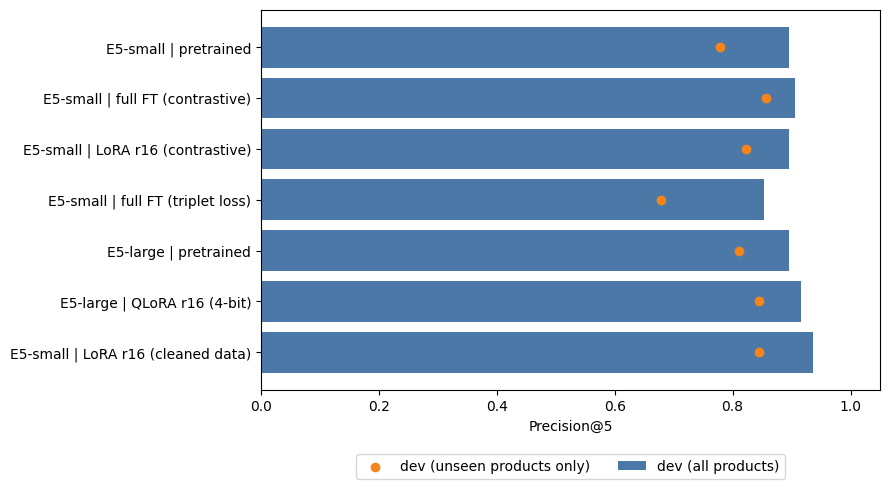

In [33]:
table = pd.DataFrame(results.values())
cols = ['run', 'trainable_M', 'trainable_%', 'train_min', 'peak_gpu_gb', 'disk_mb', 'P@5', 'P@5_CI', 'P@5_unseen',
        'P@10', 'MRR', 'nDCG@10', 'P@5_narrow', 'P@5_broad', 'val_synth_MRR', 'q_ms_p50', 'q_ms_p95']
display(table[cols])

# Bars = dev P@5 over all products; orange dots = dev P@5 over unseen (val+test) products only
fig, ax = plt.subplots(figsize=(9, 0.5 * len(table) + 1.5))
ax.barh(table['run'][::-1], table['P@5'][::-1], color='#4C78A8', label='dev (all products)')
ax.scatter(table['P@5_unseen'][::-1], range(len(table)), color='#F58518', zorder=3, label='dev (unseen products only)')
ax.set_xlabel('Precision@5')
ax.set_xlim(0, 1.05)
# Place legend below the plot box
ax.legend(loc='upper center', bbox_to_anchor=(0.5, -0.15), ncol=2)
plt.tight_layout()
plt.savefig(f'{RES_DIR}/finetune_p5.png', dpi=150, bbox_inches='tight')
plt.show()

### **Conclusion of Section 9 - Results**

Values from the table above:

| Run | Trainable | Train min | Peak GPU GB | Disk MB | Dev P@5 (95% CI) | P@5 unseen | MRR | nDCG@10 | val_synth_MRR | Query ms p50 |
|---|---|---|---|---|---|---|---|---|---|---|
| E5-small pretrained | 0 | - | - | - | 0.895 (0.79-0.97) | 0.778 | 0.958 | 0.870 | 0.661 | 12.1 |
| E5-small full FT, contrastive | 33.36M (100%) | 4.1 | 6.2 | 134.2 | 0.905 (0.77-1.00) | **0.856** | 0.951 | 0.905 | **0.764** | 13.7 |
| E5-small LoRA r16, contrastive | 0.44M (1.31%) | 4.4 | 5.0 | 2.5 | 0.895 (0.77-0.99) | 0.822 | 0.932 | 0.903 | 0.747 | 31.4 |
| E5-small full FT, triplet | 33.36M (100%) | 3.8 | 6.2 | 134.2 | 0.853 (0.72-0.95) | 0.678 | 0.879 | 0.820 | 0.679 | 13.4 |
| E5-large pretrained | 0 | - | - | - | 0.895 (0.80-0.97) | 0.811 | 0.974 | 0.864 | 0.688 | 22.3 |
| E5-large QLoRA r16 | 2.36M (1.27%) | 21.1 | 2.8 | 10.2 | 0.916 (0.81-0.99) | 0.844 | **1.000** | 0.903 | 0.747 | 60.2 |
| E5-small LoRA r16, cleaned data (Sec. 15) | 0.44M (1.31%) | 4.4 | 5.2 | 2.5 | **0.937** (0.83-1.00) | 0.844 | 0.958 | **0.928** | 0.742 | 22.0 |

**The chart:** the blue bars (dev P@5) are close for every run except triplet. The orange dots (unseen products) spread more and carry most of the visible differences.

**What the numbers support:**
- **Dev P@5 barely separates the runs.** Every interval overlaps the others, and the broad queries are already at 1.00 for E5-small pretrained. Treat P@5 as a sanity check, not a ranking.
- **Training worked on the synthetic task:** contrastive training raised `val_synth_MRR` from 0.661 to 0.742-0.764 (E5-small) and from 0.688 to 0.747 (E5-large).
- **On the real dev queries the gains are small:**
  - nDCG@10 rose 0.03-0.06 for every contrastive run (0.870 → 0.903-0.928; 0.864 → 0.903);
  - unseen P@5 rose by 0.03-0.08;
  - MRR rose only for QLoRA (it was already 0.958/0.974).
- **Run-to-run noise is of the same size as these gains.** In an earlier, unseeded execution, the same LoRA configuration scored unseen P@5 0.789 instead of 0.822. A difference of a few hundredths between two single runs is not evidence on its own; Section 11.1 gives the paired intervals.
- **Triplet loss hurt** on every metric (unseen P@5 0.778 → 0.678, MRR 0.958 → 0.879). The contrastive loss with in-batch negatives is the better choice here.
- **LoRA vs full fine-tuning (original data):**
  - same dev P@5 and nDCG@10;
  - full fine-tuning is higher on unseen P@5 (0.856 vs 0.822) and MRR;
  - LoRA trains 1.3% of the weights, saves a 2.5 MB adapter instead of 134 MB, and peaks at 5.0 GB instead of 6.2 GB;
  - training time is about the same.
- **QLoRA on E5-large** has a perfect MRR and the lowest memory peak (2.8 GB, with batch 32 and checkpointing). It trained ~5x longer than E5-small LoRA and is the slowest at query time (60.2 ms p50).
- **The cleaned-data LoRA run (Section 15)** has the highest dev P@5 (0.937) and nDCG@10 (0.928) of all runs. Sections 15-16 test whether that is more than noise.
- **Latency caveat:** single-query timings include Python and tokenizer overhead and vary between runs: the two E5-small LoRA rows have identical architecture but 31.4 vs 22.0 ms. Unmerged adapters add a few ms; `merge_and_unload()` before serving brings LoRA back to the base model's latency.
- **Model choice at this point: E5-small LoRA r16.** It was chosen for cost (tiny adapter, lowest memory among the E5-small runs, base-model latency once merged) at quality equal to full fine-tuning within noise. It was not chosen because it scored highest. This was the model scored on test in Section 12. The cleaned-data version of it is compared in Sections 15-17.

## **10. Per-Query Analysis**

Fine-tuning on title-style queries can hurt other kinds of queries. This section:
1. restores the saved per-query results and dev-query embeddings (rebuilt from the saved models if they are missing);
2. lists every dev query whose P@5 moved by 0.2 or more against its pretrained baseline.

### **10.1 - Per-Query Analysis - Managing Evaluation Artifacts**

This cell restores the saved per-query results and dev-query embeddings for every run, and rebuilds them from the saved models when files are missing, so the analysis below works without retraining.

In [34]:
def restore_artifacts():
    """Fill per_query_res / query_emb from saved files; return runs whose artifacts are missing."""
    missing = []
    for run in results:
        slug = slugify(run)
        pq, qe = f'{RES_DIR}/perquery__{slug}.csv', f'{EMB_DIR}/ftq__{slug}.npy'
        if run in per_query_res and run in query_emb:          # already in memory from this session
            continue
        if os.path.exists(pq) and os.path.exists(qe):
            per_query_res[run], query_emb[run] = pd.read_csv(pq), np.load(qe)
        else:
            missing.append(run)
    return missing


def rebuild_artifacts(runs):
    """Re-encode the dev queries with each saved model (no training) and rebuild the per-query results.
    Scores use the saved catalog embeddings, so the rebuilt P@5 must match the logged P@5."""
    for run in runs:
        row, slug = results[run], slugify(run)
        base, path, method = BASE_IDS[row['base']], f'{MODEL_DIR}/{slug}', row['method']
        if method == 'none':
            enc = load_encoder(base, 'none')
        elif method == 'full':
            enc = load_encoder(path, 'none')                   # the full model was saved as a folder
        else:                                                  # lora / qlora: base model + saved adapter
            tok = AutoTokenizer.from_pretrained(base)
            enc = Enc(PeftModel.from_pretrained(_load_base(base, method), path), tok)
        Q = enc.encode(dev_queries_text, enc.q_prefix, 64)
        D = np.load(f'{EMB_DIR}/ft__{slug}.npy')
        res = evaluate(Q @ D.T, dev)
        gap = abs(res['P@5'].mean() - row['P@5'])             # consistency check against the logged value
        print(f'{run}: rebuilt P@5 {res["P@5"].mean():.3f} vs logged {row["P@5"]:.3f}' + ('' if gap < 0.02 else '   <-- MISMATCH, check the saved model'))
        np.save(f'{EMB_DIR}/ftq__{slug}.npy', Q)
        res.to_csv(f'{RES_DIR}/perquery__{slug}.csv', index=False)
        per_query_res[run], query_emb[run] = res, Q
        del enc
        gc.collect()
        if device == 'cuda':
            torch.cuda.empty_cache()


missing = restore_artifacts()
print('runs to rebuild:', missing if missing else 'none')
rebuild_artifacts(missing)      # re-encodes dev queries only; the E5-large runs need a few GB of GPU memory

runs to rebuild: none


### **Conclusion of Section 10.1 - Per-Query Analysis - Managing Evaluation Artifacts**

This cell loads, or rebuilds, the evaluation artifacts (dev-query embeddings and per-query metrics), so the downstream analysis can run without retraining any model.

#### **1. `restore_artifacts()`**
For every run in the results table, this function checks Google Drive for the saved dev-query embeddings (`ftq__<run>.npy`) and per-query metrics (`perquery__<run>.csv`). Runs trained in this session are already in memory and are skipped.

#### **2. `rebuild_artifacts(runs)`**
For any run whose files are missing, this function reloads the saved model (pretrained, full checkpoint, or base + adapter), re-encodes only the 19 dev queries, and re-scores them against the saved catalog embeddings. It also prints the rebuilt P@5 next to the logged P@5. A mismatch means the saved model and the saved embeddings do not belong together.

**Output:** `runs to rebuild: none`. All 7 runs had their files on Drive, so nothing was re-encoded. The per-query data for runs not trained in this session (`E5-large | QLoRA`, `LoRA r16 (cleaned data)`) comes from the files of their last execution.

### **10.2 - Per-Query Analysis - Per-Query Deltas vs. Pretrained Baseline**

`vs_baseline` aligns each run with its pretrained baseline query by query and keeps only the queries whose P@5 moved by 0.2 or more, focusing the analysis on real improvements or regressions. P@5 moves in steps of 0.2: one product entering or leaving the top 5.

In [35]:
# Extract the P@5 score per query for both the pretrained baseline run and the fine-tuned run,
# align them by query text, compute the change (finetuned - baseline) and keep only changes of
# 0.2 or more (= at least one product entered or left the top 5).
def vs_baseline(run, baseline):
    """Per-query P@5 for a run vs its pretrained baseline; keeps changes of 0.2 or more."""
    a, b = per_query_res[baseline].set_index('query')['P@5'], per_query_res[run].set_index('query')['P@5']
    d = pd.DataFrame({'baseline': a, 'finetuned': b}).assign(change=lambda x: x['finetuned'] - x['baseline'])
    return d[d['change'].abs() >= 0.2 - 1e-9].sort_values('change')   # tolerance: 0.6 - 0.4 is 0.19999... in float

for run in per_query_res:
    if 'pretrained' in run:
        continue
    base_run = run.split(' | ')[0] + ' | pretrained'          # 'E5-small | ...' -> 'E5-small | pretrained'
    if base_run in per_query_res:
        diff = vs_baseline(run, base_run)
        print(f'\n{run}: {(diff["change"] > 0).sum()} queries improved, {(diff["change"] < 0).sum()} got worse (change >= 0.2)')
        if len(diff):
            display(diff.round(2))


E5-small | full FT (contrastive): 5 queries improved, 2 got worse (change >= 0.2)


,baseline,finetuned,change
query,,,
men's sandals,0.6,0.0,-0.6
women's ankle boots under $60,1.0,0.8,-0.2
comfortable walking shoes,0.8,1.0,0.2
carry-on suitcase,0.8,1.0,0.2
a black leather wallet,0.8,1.0,0.2
a sterling silver band ring under $50,0.8,1.0,0.2
a ring with a gemstone,0.2,0.4,0.2



E5-small | LoRA r16 (contrastive): 3 queries improved, 2 got worse (change >= 0.2)


,baseline,finetuned,change
query,,,
men's sandals,0.6,0.2,-0.4
women's ankle boots under $60,1.0,0.8,-0.2
comfortable walking shoes,0.8,1.0,0.2
carry-on suitcase,0.8,1.0,0.2
a sterling silver band ring under $50,0.8,1.0,0.2



E5-small | full FT (triplet loss): 3 queries improved, 4 got worse (change >= 0.2)


,baseline,finetuned,change
query,,,
women's sneakers,1.0,0.6,-0.4
a velvet sofa,1.0,0.6,-0.4
cotton bed sheets,1.0,0.6,-0.4
a ring with a gemstone,0.2,0.0,-0.2
carry-on suitcase,0.8,1.0,0.2
comfortable walking shoes,0.8,1.0,0.2
a sterling silver band ring under $50,0.8,1.0,0.2



E5-large | QLoRA r16 (4-bit): 3 queries improved, 3 got worse (change >= 0.2)


,baseline,finetuned,change
query,,,
men's sandals,0.6,0.4,-0.2
a ring with a gemstone,0.6,0.4,-0.2
a sterling silver band ring under $50,1.0,0.8,-0.2
black leather shoes for men,0.8,1.0,0.2
a velvet sofa,0.8,1.0,0.2
a sectional couch,0.4,1.0,0.6



E5-small | LoRA r16 (cleaned data): 6 queries improved, 1 got worse (change >= 0.2)


,baseline,finetuned,change
query,,,
women's ankle boots under $60,1.0,0.2,-0.8
comfortable walking shoes,0.8,1.0,0.2
carry-on suitcase,0.8,1.0,0.2
a black leather wallet,0.8,1.0,0.2
a sterling silver band ring under $50,0.8,1.0,0.2
a ring with a gemstone,0.2,0.6,0.4
men's sandals,0.6,1.0,0.4


### **Conclusion of Section 10.2 - Per-Query Deltas vs. Pretrained Baseline**

**Output** (queries whose P@5 moved by at least 0.2 against the pretrained baseline):

| Run | Improved | Got worse |
|---|---|---|
| E5-small full FT (contrastive) | 5: walking shoes, carry-on suitcase, black leather wallet, sterling silver ring (+0.2 each), ring with a gemstone 0.2 → 0.4 | `men's sandals` 0.6 → 0.0; `women's ankle boots under $60` 1.0 → 0.8 |
| E5-small LoRA r16 (contrastive) | 3: walking shoes, carry-on suitcase, sterling silver ring (+0.2 each) | `men's sandals` 0.6 → 0.2; `women's ankle boots under $60` 1.0 → 0.8 |
| E5-small full FT (triplet) | 3: carry-on suitcase, walking shoes, sterling silver ring (+0.2 each) | `women's sneakers`, `a velvet sofa`, `cotton bed sheets` 1.0 → 0.6; `a ring with a gemstone` 0.2 → 0.0 |
| E5-large QLoRA r16 | 3: `a sectional couch` 0.4 → 1.0, `a velvet sofa`, `black leather shoes for men` (+0.2) | `men's sandals`, `a ring with a gemstone`, `a sterling silver band ring under $50` (-0.2 each) |
| E5-small LoRA r16 (cleaned data) | 6: `men's sandals` 0.6 → 1.0, `a ring with a gemstone` 0.2 → 0.6, wallet, sterling silver ring, suitcase, walking shoes (+0.2) | `women's ankle boots under $60` 1.0 → 0.2 |

P@5 moves in steps of 0.2 (one product entering or leaving the top 5), so most changes here are a single product.

**Reading:**
- **Few queries change, and mostly by one product.** Each run changes 5-7 of the 19 queries. The averages in Section 9 are driven by a handful of products.
- **Footwear is where the original training data hurt.** `men's sandals` and `women's ankle boots under $60` got worse under both E5-small contrastive runs trained on the original pairs. Sections 10.3-10.4 investigate why.
- **Triplet loss hurts across categories:** footwear, furniture, bedding and jewelry.
- **QLoRA has the biggest single gain on the original data** (`a sectional couch`, +0.6).
- **The cleaned-data run reverses the sandals regression (+0.4) but has the largest single drop of any run** (ankle boots, -0.8). Section 17.2 diagnoses that drop.

### **10.3 - Per-Query Analysis - Retrieving Top Results**

`show_top` prints the top-k products for one dev query under each run, using that run's own query embedding, together with the rank of the first relevant result. `[REL]` means the product is in the query's relevant set from notebook 04. `[---]` means it is not.

In [36]:
def show_top(query, runs, k=5):
    """Top-k results for one dev query under each run, using the query's OWN embedding."""
    q = next(x for x in dev if x['query'] == query)
    qi = dev.index(q)                                          # row of this query in query_emb[run]
    elig, rel = elig_mask(q), rel_bool[q['id']]
    print(f'Query: {query!r} | {q["n_relevant"]} relevant products')
    for run in runs:
        D = np.load(f'{EMB_DIR}/ft__{slugify(run)}.npy')
        scores = D @ query_emb[run][qi]                        # cosine similarity to every product
        top = rank_top(scores, elig, k=100)
        first_rel = int(np.flatnonzero(rel[top])[0]) + 1 if rel[top].any() else None
        print(f'\n--- {run} | first relevant result at rank: {first_rel or ">100"} ---')
        for idx in top[:k]:
            print(f"  {scores[idx]:.3f} {'[REL]' if rel[idx] else '[---]'} {df.iloc[idx]['ptype']:<22} {df.iloc[idx]['name_en'][:70]}")

show_top("men's sandals", ['E5-small | pretrained', 'E5-small | full FT (contrastive)', 'E5-small | LoRA r16 (contrastive)'])

Query: "men's sandals" | 51 relevant products

--- E5-small | pretrained | first relevant result at rank: 1 ---
  0.885 [REL] SANDAL                 Amazon brand: find. Men's Sandals Without Heels
  0.881 [---] SHOES                  Amazon Brand - Symbol Men's Tan Sandals-11 UK/India (45 EU) (AZ-KY-336
  0.881 [REL] SANDAL                 Amazon Brand - find. Men's Open Toe Sandals, Black (Rio Black), 12 UK
  0.880 [REL] SANDAL                 Amazon Brand - find. Men's Open Toe Sandals, Black (Rio Black), 7 UK
  0.879 [---] SHOES                  Amazon Brand - Symbol Men's Brown Sandals-11 UK/India (45 EU) (AZ-KY-3

--- E5-small | full FT (contrastive) | first relevant result at rank: 13 ---
  0.666 [---] SHOES                  Amazon Brand - Symbol Men's Sandals
  0.658 [---] SHOES                  Amazon Brand - Symbol Men's Sandals
  0.654 [---] SHOES                  Amazon Brand - Symbol Men's Sandals-10 UK (44 EU) (11 US) (AZ-KY-409B)
  0.645 [---] SHOES                  Amazo

### **Conclusion of Section 10.3 - Per-Query Analysis - Retrieving Top Results**

**`show_top(query, runs, k=5)`:**
- **Look up the query:** finds the query in the dev set to get its row index (`qi`) and the number of relevant products.
- **Build the masks:** loads the price eligibility mask and the ground-truth relevance mask.
- **Score each run:** computes cosine scores as a dot product (`D @ query_emb[run][qi]`), ranks the eligible products, and reports the rank of the first relevant product.

**Output for `men's sandals` (51 relevant products):**

| Run | First relevant rank | Top-5 composition |
|---|---|---|
| pretrained | 1 | 3 `SANDAL` [REL], 2 `SHOES` [---]; scores ≈ 0.88 |
| full FT (contrastive) | 13 | 5 `SHOES` [---]; scores ≈ 0.64-0.67 |
| LoRA r16 (contrastive) | 5 | 4 `SHOES` [---], then 1 `SANDAL` [REL]; scores ≈ 0.62-0.63 |

**Two findings:**
1. **Every `[---]` product is a sandal.** "Amazon Brand - Symbol Men's Sandals" and "Centrino Men's ... Fisherman Sandals" are men's sandals by name, but their catalog `ptype` is `SHOES`, and the relevance labels from notebook 04 count them as *not relevant*. The labelling rule for this query evidently depends on `ptype = SANDAL`. A shopper would accept these results, so **part of the measured drop is a labelling artefact**. The fine-tuned models moved `SHOES`-labelled sandals above `SANDAL`-labelled ones; they did not stop returning sandals. Fixing the relevance rule in notebook 04 (for example, name contains "sandal" OR `ptype == SANDAL`) would give a fairer score.
2. **The absolute scores fall from ~0.88 to ~0.63.** This is the expected effect of contrastive training at temperature 0.02 (Section 5d), which spreads the embedding space apart. Cosine values cannot be compared across models; only the ordering within one model matters.

The remaining question, *why* fine-tuning prefers the `SHOES`-labelled sandals, is examined in 10.4.

### **10.4 - Per-Query Analysis - Analyzing the "men's sandals" Query**

Hypothesis: sandal queries were trained with other sandals as "hard negatives" (false negatives), because the product-type labels are finer than the product family. The audit below measures how many sandal training queries received a same-family negative, and how footwear is spread across `ptype` labels.

In [37]:
# Hypothesis: sandal queries were trained with other sandals as "hard negatives" (false negatives),
# because the product-type labels (SANDAL vs SHOES vs ...) are finer than the product family.
# Word boundaries: without them 'heel' also matches 'wheel(s)' and pulls suitcases and chairs into "footwear".
FOOTWEAR = r'\b(?:sandals?|flip.?flops?|slippers?|shoes?|boots?|sneakers?|loafers?|heels?|clogs?)\b'

def audit_negatives(keyword, family_regex):
    """Share of the mined negatives for queries containing `keyword` whose title matches the same family."""
    sub = train_pairs[train_pairs['query'].str.contains(keyword, case=False, na=False)]
    neg_titles = pd.Series(df['name_en'].to_numpy()[sub['neg'].to_numpy()])
    same_family = neg_titles.str.contains(family_regex, case=False, na=False)
    print(f'{keyword!r}: {len(sub)} training queries; {same_family.mean():.1%} of their hard negatives are the same product family')
    display(pd.DataFrame({'query': sub['query'].head(10).values, 'hard negative': neg_titles.head(10).str[:70].values}))

audit_negatives('sandal', FOOTWEAR)
print('ptype labels of footwear products:')
display(df[df['name_en'].str.contains(FOOTWEAR, case=False, na=False)]['ptype'].value_counts().head(8))

'sandal': 1018 training queries; 61.2% of their hard negatives are the same product family


,query,hard negative
0,Women's Beige Fashion Sandals- UK EU,find. DARLING-1W3-004 Women’s Open Toe Sandals...
1,sandal amazon caroline,AmazonBasics Classic Faux Leather Extra Padded...
2,Womens Evelyn Flat Sandal,Amazon Brand - Solimo Designer Pink Paint 3D P...
3,evelyn flat sandal,"Pinzon Ultrasoft 180TC Fitted Sheets, Ivory 13..."
4,brand champagne sandal,"find. Women's B06gl5002r T-Bar Sandals, Multic..."
5,collective solo sandal,"EONO Premium 21"" Hard Shell 8 Wheel Carry On H..."
6,men's sandals- shoes,Amazon Brand - find. Block Heel Mule Open Toe ...
7,sandal cross men,The Fix Amazon Brand Women's Gabriela High-Hee...
8,Women's Grey Fashion Sandals- UK EU,find. Women's Weave Slingback Leather Open Toe...
9,fashion sandals- shoes,"find. Women's LACE-S-2-46 Open Toe Sandals, Be..."


ptype labels of footwear products:


,count
ptype,
SHOES,1528
BOOT,823
SANDAL,729
HOME_FURNITURE_AND_DECOR,5
CELLULAR_PHONE_CASE,4
CHAIR,1


### **Conclusion of Section 10.4 - Per-Query Analysis - Analyzing the "men's sandals" Query**

#### **1. The audit result**
- 1,018 training queries contain "sandal", and **61.2% of their mined hard negatives are footwear**.
- In the sample, most sandal queries received another *sandal* as their "wrong answer":
  - `Women's Beige Fashion Sandals- UK EU` → a women's open-toe sandal;
  - `brand champagne sandal` → a T-bar sandal;
  - `men's sandals- shoes` → an open-toe block-heel mule;
  - `Women's Grey Fashion Sandals- UK EU` and `fashion sandals- shoes` → open-toe sandals.
- For those queries, the training loss actively pushed the model to score other sandals *lower*: exactly the false-negative pattern hypothesised in Section 4.3.

#### **2. Why the miner allowed it**
The miner only required a **different `ptype`**, and footwear is spread over several `ptype` labels: `SHOES` 1,528, `BOOT` 823, `SANDAL` 729 (products whose title names footwear). A sandal listed as `SHOES` is a "different type" for a `SANDAL` product, so it qualified as a negative, and the reverse also holds. The label granularity does not match how shoppers think about the products.

#### **3. The small rows at the bottom of the table**
`HOME_FURNITURE_AND_DECOR` 5, `CELLULAR_PHONE_CASE` 4 and `CHAIR` 1 are products whose title names shoes as a whole word without being footwear (e.g. a shoe rack or a shoe-storage bench). They are a negligible source of noise in this audit.

#### **4. Conclusion**
The `men's sandals` regression has two causes that compound each other:
1. **False negatives in training:** the `ptype`-based miner fed other sandals as negatives (this section).
2. **Labels that also follow `ptype`:** sandals labelled `SHOES` count as wrong answers in evaluation (Section 10.3).

The fix for (1) is to mine negatives outside the product **family** (Section 14). The fix for (2) belongs in notebook 04's relevance rules.

## **11. Advanced Comparison Charts**

Dev P@5 saturates near 1.0, so these views use more of the ranking:
1. **Paired forest plot:** the change versus the pretrained baseline, with a bootstrap interval over queries. If the interval includes 0, the change is not distinguishable from noise.
2. **Per-query heatmap:** which queries each run helped or hurt.
3. **P@k curves and score separation (AUC):** how the whole ranking behaves, not just the top 5. AUC is the chance that a random relevant product scores above a random non-relevant one.
4. **Efficiency chart:** quality against trainable parameters and training time.
5. **Loss curves:** the training loss of every run that saved one.

### **11.1 - Advanced Comparison Charts - Paired Forest Plot**

This plot shows the change versus the pretrained baseline with a bootstrap interval over queries. **Paired** means the difference is computed per query first (run minus baseline on the same query) and then averaged. Easy and hard queries therefore cancel out, and the interval is much tighter than comparing two separate means.

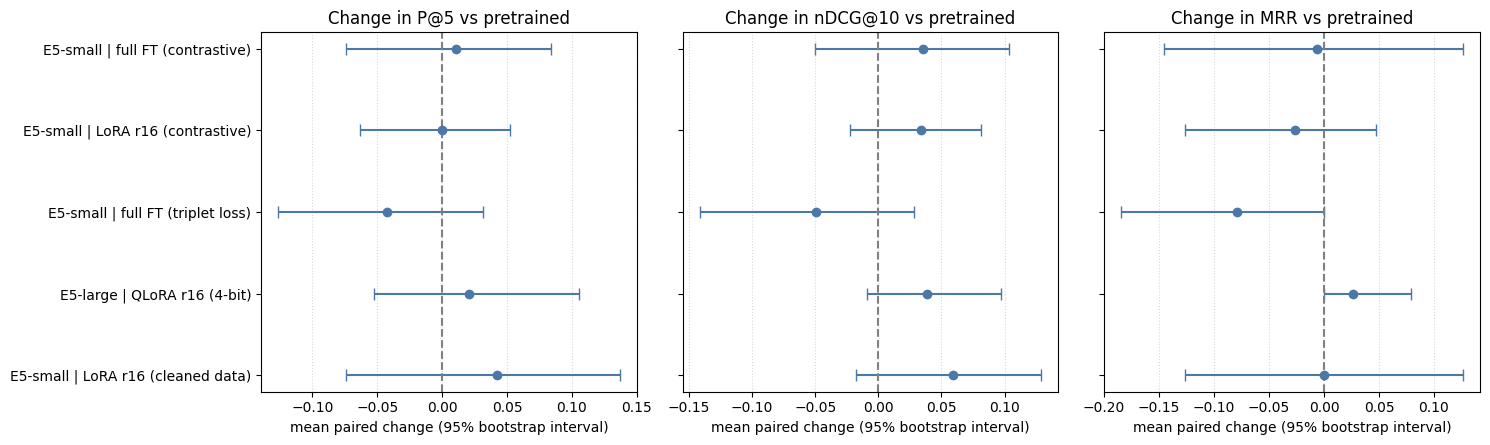

,run,metric,mean,lo,hi
0,E5-small | full FT (contrastive),P@5,0.011,-0.074,0.084
1,E5-small | full FT (contrastive),nDCG@10,0.035,-0.050,0.104
2,E5-small | full FT (contrastive),MRR,-0.006,-0.146,0.126
3,E5-small | LoRA r16 (contrastive),P@5,-0.000,-0.063,0.053
4,E5-small | LoRA r16 (contrastive),nDCG@10,0.033,-0.022,0.081
5,E5-small | LoRA r16 (contrastive),MRR,-0.026,-0.126,0.047
6,E5-small | full FT (triplet loss),P@5,-0.042,-0.126,0.032
7,E5-small | full FT (triplet loss),nDCG@10,-0.049,-0.142,0.029
8,E5-small | full FT (triplet loss),MRR,-0.079,-0.184,0.000
9,E5-large | QLoRA r16 (4-bit),P@5,0.021,-0.053,0.105


In [38]:
def paired_ci(a, b, n=5000, seed=0):
    """Mean per-query change (b - a) with a bootstrap 95% interval over queries."""
    d = np.asarray(b, dtype=float) - np.asarray(a, dtype=float)    # one difference per query
    rng = np.random.default_rng(seed)
    boots = [rng.choice(d, len(d), replace=True).mean() for _ in range(n)]
    return d.mean(), *np.percentile(boots, [2.5, 97.5])

rows = []
for run in per_query_res:
    if 'pretrained' in run:
        continue
    base_run = run.split(' | ')[0] + ' | pretrained'
    a, b = per_query_res[base_run].set_index('id'), per_query_res[run].set_index('id')
    ids = a.index.intersection(b.index)                               # align the same queries
    for metric in ['P@5', 'nDCG@10', 'MRR']:
        m, lo, hi = paired_ci(a.loc[ids, metric], b.loc[ids, metric])
        rows.append({'run': run, 'metric': metric, 'mean': m, 'lo': lo, 'hi': hi})
forest = pd.DataFrame(rows)

metrics_ = ['P@5', 'nDCG@10', 'MRR']
runs_ = forest['run'].unique()
fig, axes = plt.subplots(1, 3, figsize=(15, 0.55 * len(runs_) + 1.8), sharey=True)
for ax, metric in zip(axes, metrics_):
    f = forest[forest['metric'] == metric].set_index('run').loc[runs_]
    y = np.arange(len(runs_))[::-1]
    ax.errorbar(f['mean'], y, xerr=[f['mean'] - f['lo'], f['hi'] - f['mean']], fmt='o', color='#4C78A8', capsize=4)
    ax.axvline(0, color='gray', linestyle='--')                          # line of no effect
    ax.set_title(f'Change in {metric} vs pretrained')
    ax.set_xlabel('mean paired change (95% bootstrap interval)')
    ax.set_yticks(y)
    ax.set_yticklabels(runs_)
    ax.grid(axis='x', linestyle=':', alpha=0.5)
plt.tight_layout()
plt.savefig(f'{RES_DIR}/forest_paired_change.png', dpi=150)
plt.show()
display(forest.round(3))

#### **How to Interpret the Paired Forest Plot: Change vs. Pretrained Baseline**

The **Paired Forest Plot** does not show absolute metrics. It shows the change of each fine-tuned run against its own pretrained baseline, computed query by query.

---

##### **1. Visual Structure of the Plot**
Each row is one fine-tuned run compared with its pretrained counterpart (e.g., *E5-small LoRA* vs. *E5-small pretrained*):

* **The dot:** the **mean paired change** across the 19 dev queries.
  * A dot to the right of the dashed line ($> 0$) means the run **improved** that metric on average.
  * A dot to the left ($< 0$) means it **degraded** that metric on average.
* **The horizontal error bars:** the **95% bootstrap confidence interval**. The 19 per-query differences are resampled with replacement 5,000 times, and the interval holds the middle 95% of the resampled means.
* **The vertical dashed line ($x = 0$):** the **line of no effect** (no difference from the pretrained baseline).

---

##### **2. Rules of Interpretation**

###### **A. Statistical Significance (Crossing the Dashed Line)**
* **The bar crosses $0$:** the change is **not distinguishable from noise** at this sample size. It is not proof of "no effect"; the experiment is too small to tell.
* **The whole bar is right of $0$:** a **statistically significant improvement**.
* **The whole bar is left of $0$:** a **statistically significant degradation**. In this plot no run reaches that: triplet loss on MRR comes closest (its interval ends exactly at 0).

###### **B. Understanding Metric-Specific Behaviors**
* **P@5:** changes come in steps of 0.2 per query and most queries do not change at all, so the mean change is small and noisy. P@5 is also near its ceiling for the pretrained model.
* **nDCG@10:** uses graded positions in the top 10, so it registers small reorderings that P@5 misses. Here it has the narrowest intervals and the most consistent direction.
* **MRR:** depends only on the position of the *first* relevant result, and swings strongly per query (rank 1 → 2 halves it). It has the **widest** intervals in this plot.

### **Conclusion of Section 11.1 - Advanced Comparison Charts - Paired Forest Plot**

Values from the table under the plot (mean change vs the run's own pretrained model [95% interval]):

| Run | P@5 | nDCG@10 | MRR |
|---|---|---|---|
| E5-small full FT (contrastive) | +0.011 [-0.074, 0.084] | +0.035 [-0.050, 0.104] | -0.006 [-0.146, 0.126] |
| E5-small LoRA r16 (contrastive) | 0.000 [-0.063, 0.053] | +0.033 [-0.022, 0.081] | -0.026 [-0.126, 0.047] |
| E5-small full FT (triplet) | -0.042 [-0.126, 0.032] | -0.049 [-0.142, 0.029] | -0.079 [-0.184, 0.000] |
| E5-large QLoRA r16 | +0.021 [-0.053, 0.105] | +0.038 [-0.009, 0.097] | +0.026 [0.000, 0.079] |
| E5-small LoRA r16 (cleaned data) | +0.042 [-0.074, 0.137] | **+0.059 [-0.018, 0.129]** | 0.000 [-0.126, 0.126] |

* **No run is significantly better than its pretrained model on any metric.** Every interval reaches zero. With 19 dev queries, the experiment cannot detect changes smaller than roughly ±0.05-0.10.
* **nDCG@10 is the most consistent signal:** all four contrastive runs are positive (+0.033 to +0.059), with lower bounds only just below zero (-0.050 to -0.009). The direction is consistent, but the effect is not established.
* **The cleaned-data LoRA run has the largest mean gains** (P@5 +0.042, nDCG@10 +0.059). It also has the widest intervals, because one query improved a lot (`men's sandals`) while another dropped a lot (`women's ankle boots under $60`).
* **QLoRA's MRR interval starts exactly at zero** ([0.000, 0.079]): no query got a worse first hit and a few got a better one. That is borderline, not a clear gain.
* **Triplet loss is the only run with a consistently negative direction:** all three means are below zero, and its MRR interval ends exactly at 0.
* **E5-small LoRA** stays the operational choice: its quality is indistinguishable from full fine-tuning and from E5-large QLoRA here, and it is far cheaper than QLoRA (4.4 vs 21.1 min of training; ~22-31 vs 60 ms per query before merging the adapter).

### **11.2 - Advanced Comparison Charts - Per-Query Heatmap**

This heatmap shows the P@5 change of every fine-tuned run against its pretrained baseline, for every dev query. Blue means the run helped and red means it hurt. Rows are sorted by the average change, so the worst-affected queries are at the top.

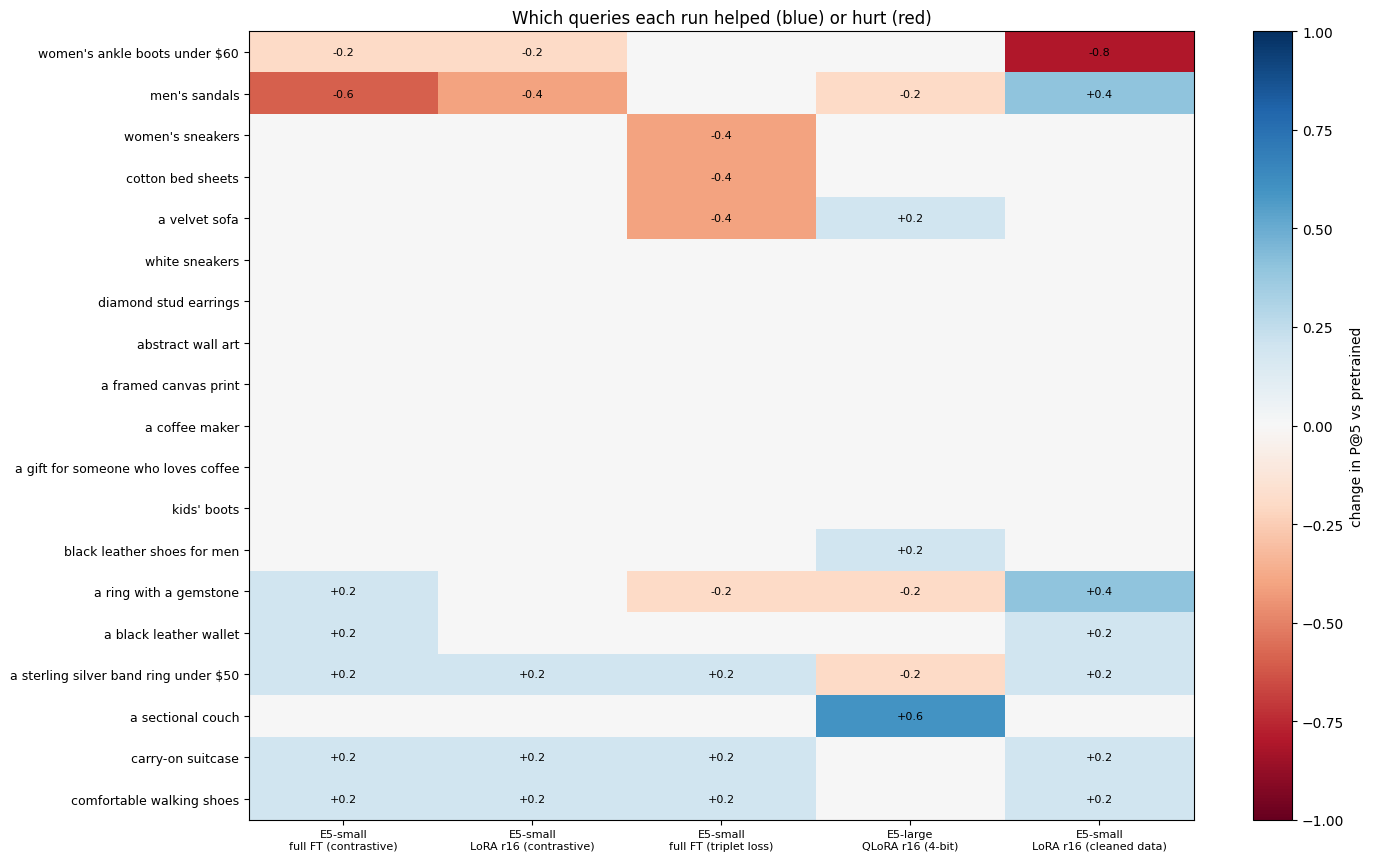

In [39]:
# One column per fine-tuned run: per-query P@5 change vs that model family's pretrained run
delta = {}
for run in per_query_res:
    if 'pretrained' in run:
        continue
    base_run = run.split(' | ')[0] + ' | pretrained'
    a, b = per_query_res[base_run].set_index('query')['P@5'], per_query_res[run].set_index('query')['P@5']
    delta[run.replace(' | ', '\n')] = b - a
H = pd.DataFrame(delta)
H = H.loc[H.mean(axis=1).sort_values().index]            # worst-affected queries on top

fig, ax = plt.subplots(figsize=(2.1 * H.shape[1] + 4, 0.38 * len(H) + 1.5))
im = ax.imshow(H.values, cmap='RdBu', vmin=-1, vmax=1, aspect='auto')   # diverging map centred on 0
ax.set_xticks(range(H.shape[1]))
ax.set_xticklabels(H.columns, fontsize=8)
ax.set_yticks(range(len(H)))
ax.set_yticklabels(H.index, fontsize=9)
for i in range(H.shape[0]):
    for j in range(H.shape[1]):
        v = H.values[i, j]
        if not np.isnan(v) and abs(v) > 1e-9:            # label only cells that changed
            ax.text(j, i, f'{v:+.1f}', ha='center', va='center', fontsize=8)
fig.colorbar(im, ax=ax, label='change in P@5 vs pretrained')
ax.set_title('Which queries each run helped (blue) or hurt (red)')
plt.tight_layout()
plt.savefig(f'{RES_DIR}/heatmap_query_change.png', dpi=150)
plt.show()

### **Conclusion of Section 11.2 - Advanced Comparison Charts - Per-Query Heatmap**

The heatmap shows the change in Precision@5 ($\Delta P@5$) of each fine-tuned run against its pretrained baseline, for each of the 19 dev queries:

* **Most cells are unchanged.** Six queries are untouched by every run: `white sneakers`, `diamond stud earrings`, `abstract wall art`, `a framed canvas print`, `a coffee maker` and `kids' boots`. `a gift for someone who loves coffee` is unchanged too. Fine-tuning reshuffles a few queries, not all of them.

* **The footwear regression of the original training data:**
  * `men's sandals`: -0.6 full FT, -0.4 LoRA, -0.2 QLoRA;
  * `women's ankle boots under $60`: -0.2 for full FT and LoRA;
  * this matches the false-negative mechanism of Section 10.4 combined with the labelling artefact of Section 10.3.

* **Consistent small gains:** `comfortable walking shoes`, `carry-on suitcase` and `a sterling silver band ring under $50` are +0.2 in every E5-small run (including triplet).

* **Triplet loss hurts across categories:** `women's sneakers`, `cotton bed sheets` and `a velvet sofa` (-0.4 each) and `a ring with a gemstone` (-0.2).

* **E5-large QLoRA behaves differently from the E5-small runs:** the largest single gain among the original-data runs (`a sectional couch` +0.6, plus `a velvet sofa` and `black leather shoes for men` +0.2), and small losses on both ring queries and `men's sandals`.

* **The cleaned-data LoRA (rightmost column) changes the footwear picture in both directions:**
  * `men's sandals` turns blue (+0.4): the only run that improves on the pretrained model there;
  * `a ring with a gemstone` +0.4, the best of any run;
  * but `women's ankle boots under $60` drops -0.8, the deepest red cell in the chart (diagnosed in Section 17.2).

### **11.3 - Advanced Comparison Charts - P@k Curves and AUC score separation**

- **Left:** mean Precision@k for k = 1 to 50. This shows how the whole ranking behaves, not just the top 5.
- **Right:** per-query AUC. AUC is the chance that a random relevant product scores above a random non-relevant one, computed over all eligible products: 1.0 is perfect separation and 0.5 is random.

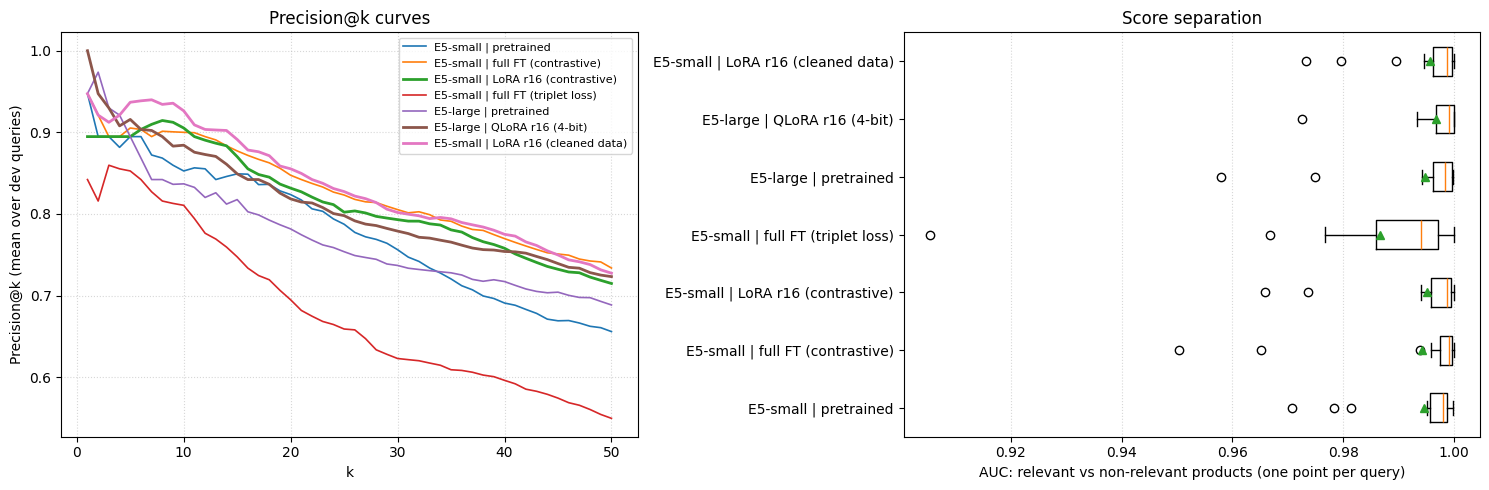

{'E5-small | pretrained': 0.9947, 'E5-small | full FT (contrastive)': 0.9943, 'E5-small | LoRA r16 (contrastive)': 0.9951, 'E5-small | full FT (triplet loss)': 0.9868, 'E5-large | pretrained': 0.9948, 'E5-large | QLoRA r16 (4-bit)': 0.9968, 'E5-small | LoRA r16 (cleaned data)': 0.9957}


In [40]:
# Score matrices per run, rebuilt from saved embeddings (dev queries x catalog)
def run_scores(run):
    return query_emb[run] @ np.load(f'{EMB_DIR}/ft__{slugify(run)}.npy').T

def auc_of(scores, elig, rel):
    """Chance that a random relevant product outscores a random non-relevant one (eligible products only).
    Mann-Whitney U statistic: sum of the ranks of the positives, minus their minimum possible sum, divided by n1*n0."""
    s, r = scores[elig], rel[elig]
    n1, n0 = int(r.sum()), int((~r).sum())
    return (rankdata(s)[r].sum() - n1 * (n1 + 1) / 2) / (n1 * n0)

K = 50
pk, auc = {}, {}
for run in per_query_res:
    S = run_scores(run)
    hits, aucs = [], []
    for qi, q in enumerate(dev):
        elig, rel = elig_mask(q), rel_bool[q['id']]
        top = rank_top(S[qi], elig, k=100)
        h = np.zeros(K)
        h[:min(K, len(top))] = rel[top][:K]                       # pad if fewer than K products are eligible
        hits.append(np.cumsum(h) / np.arange(1, K + 1))           # P@1 ... P@K for this query
        aucs.append(auc_of(S[qi], elig, rel))
    pk[run], auc[run] = np.mean(hits, axis=0), aucs

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
for run, curve in pk.items():
    axes[0].plot(range(1, K + 1), curve, label=run, linewidth=2 if 'LoRA' in run else 1.2)
axes[0].set_xlabel('k')
axes[0].set_ylabel('Precision@k (mean over dev queries)')
axes[0].set_title('Precision@k curves')
axes[0].legend(fontsize=8)
axes[0].grid(linestyle=':', alpha=0.5)

order = list(auc)
axes[1].boxplot([auc[r] for r in order], vert=False, showmeans=True)   # green triangle = mean
axes[1].set_yticklabels(order)
axes[1].set_xlabel('AUC: relevant vs non-relevant products (one point per query)')
axes[1].set_title('Score separation')
axes[1].grid(axis='x', linestyle=':', alpha=0.5)
plt.tight_layout()
plt.savefig(f'{RES_DIR}/pk_curves_and_auc.png', dpi=150)
plt.show()
print({r: round(float(np.mean(a)), 4) for r, a in auc.items()})

### **Conclusion of Section 11.3 - Advanced Comparison Charts - P@k Curves and AUC score separation**

Looking beyond the top 5 ($k \in [1, 50]$) and at the overall **AUC**:

* **Precision@k curves (left):**
  * **Precision@k decays as $k$ grows for every model.** Part of this is mechanical: a query with 20 relevant products can score at most $20/50 = 0.4$ at $k = 50$.
  * **For $k \le 5$ the curves are tangled** within about ±0.05, apart from triplet. This is the saturation already seen in P@5.
  * **Between $k \approx 5$ and $15$ the cleaned-data LoRA (pink) is the highest curve** (≈ 0.93-0.94), followed by QLoRA and the original LoRA.
  * **From about $k = 15$ all contrastive runs stay above their pretrained baselines.** Approximate values at $k = 50$:
    * E5-small pretrained ≈ 0.66;
    * LoRA ≈ 0.71, cleaned-data LoRA ≈ 0.73, full FT ≈ 0.73;
    * E5-large pretrained ≈ 0.69, QLoRA ≈ 0.72.
  * **Fine-tuning helps most deeper in the ranking.** That is where P@5 cannot see it, and it matters if a re-ranker or a "show more" page consumes the top 50.
  * **Triplet loss sits below every other model at every $k$** (≈ 0.84 at $k = 1$, ≈ 0.55 at $k = 50$).

* **Score separation (AUC, right):**
  * Mean AUC per run:
    * E5-small pretrained 0.9947;
    * full FT 0.9943;
    * LoRA 0.9951; cleaned-data LoRA 0.9957;
    * triplet 0.9868;
    * E5-large pretrained 0.9948; QLoRA 0.9968.
  * **Every model separates relevant from non-relevant products almost perfectly.** AUC compares each relevant product with *every* non-relevant product in the catalog, and most of those (sofas, for a sandal query) are trivially wrong. AUC near 1 is therefore expected and not very informative.
  * **The differences between the pretrained and contrastive runs are in the third decimal.** Triplet has the widest box and the lowest outlier (≈ 0.905).
  * Each box shows a few outlier queries at 0.95-0.98: queries where some relevant products are ranked deep, often the footwear queries.

* **Where the errors are:** near-perfect AUC combined with imperfect top-k precision means the remaining errors are concentrated among **similar products near the top of the list**, such as sandals labelled `SHOES` vs `SANDAL`, or one sofa style vs another. Fine-grained distinctions and label quality, not global filtering, limit the scores.

### **11.4 - Advanced Comparison Charts - Quality vs. Cost Efficiency Frontier**

This chart plots dev P@5 on **unseen** products against two costs: trainable parameters (left, log scale) and training time (right).
- Colour encodes the method: blue = pretrained, red = full FT, orange = LoRA, green = QLoRA.
- Shape encodes the base model: circle = E5-small, square = E5-large.
- Pretrained runs have 0 trainable parameters and are drawn at 0.1M so they fit on the log axis.

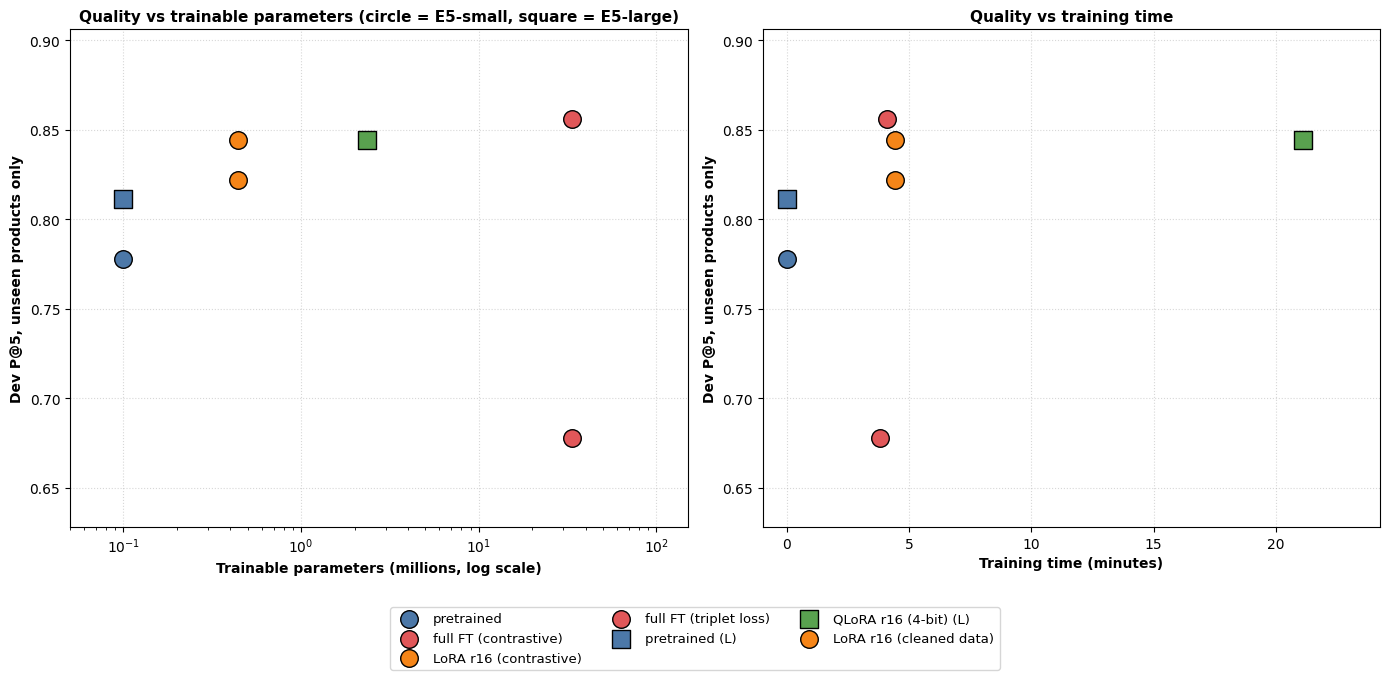

In [41]:
t = pd.DataFrame(results.values())
color = {'none': '#4C78A8', 'full': '#E15759', 'lora': '#F58518', 'qlora': '#59A14F'}
marker = {'e5-small-v2': 'o', 'e5-large-v2': 's'}

fig, axes = plt.subplots(1, 2, figsize=(14, 6.5))

# Loop over both subplots
for ax, xcol, xlabel in [(axes[0], 'trainable_M', 'Trainable parameters (millions, log scale)'),
                         (axes[1], 'train_min', 'Training time (minutes)')]:
    # Plot each run with its unique style
    for _, r in t.iterrows():
        x = max(r[xcol], 0.1) if xcol == 'trainable_M' else r[xcol]   # 0 cannot be shown on a log axis
        label_text = r['run'].split(' | ')[1] + ('' if r['base'] == 'e5-small-v2' else ' (L)')
        ax.scatter(x, r['P@5_unseen'], s=160, color=color.get(r['method'], 'gray'),
                   marker=marker.get(r['base'], 'o'), edgecolor='black', zorder=3, label=label_text)

    if xcol == 'trainable_M':
        ax.set_xscale('log')
        ax.set_xlim(0.05, 150)
    else:
        ax.set_xlim(-1, t['train_min'].max() * 1.15)

    lo, hi = t['P@5_unseen'].min(), t['P@5_unseen'].max()
    ax.set_ylim(lo - 0.05, hi + 0.05)
    ax.set_xlabel(xlabel, fontsize=10, fontweight='bold')
    ax.set_ylabel('Dev P@5, unseen products only', fontsize=10, fontweight='bold')
    ax.grid(linestyle=':', alpha=0.5)

# Deduplicate labels for a single unified legend
handles, labels = axes[0].get_legend_handles_labels()
by_label = dict(zip(labels, handles))
fig.legend(by_label.values(), by_label.keys(), loc='lower center', bbox_to_anchor=(0.5, -0.05), ncol=3, fontsize=9.5, frameon=True)

axes[0].set_title('Quality vs trainable parameters (circle = E5-small, square = E5-large)', fontsize=11, fontweight='bold')
axes[1].set_title('Quality vs training time', fontsize=11, fontweight='bold')
plt.tight_layout()
# Extra space at bottom to accommodate the legend
plt.subplots_adjust(bottom=0.18)
plt.savefig(f'{RES_DIR}/efficiency_frontier.png', dpi=150, bbox_inches='tight')
plt.show()

### **Conclusion of Section 11.4 - Advanced Comparison Charts - Quality vs. Cost Efficiency Frontier**

Points in the chart (unseen P@5):
- **E5-small:** pretrained 0.778; LoRA 0.822; cleaned-data LoRA 0.844; full FT 0.856; triplet 0.678.
- **E5-large:** pretrained 0.811; QLoRA 0.844.

* **Quality vs trainable parameters (left):**
  * **Adapters get most of the benefit.** With 1.3% of the weights (0.44M), the two E5-small LoRA runs reach 0.822-0.844, against 0.856 for full fine-tuning with 33.4M weights.
  * **Cleaning the training data moved LoRA as much as switching to full fine-tuning did** (0.822 → 0.844, vs 0.856 for full FT). Both gaps are about one seed's worth of noise (Section 9).
  * **The size of the base matters too:** the pretrained E5-large (0.811) already scores above the pretrained E5-small (0.778), and QLoRA on E5-large reaches 0.844.
  * **The disk footprint follows the parameter count:** a 2.5 MB adapter (E5-small) or 10.2 MB (E5-large), against 134 MB for a full E5-small checkpoint.

* **Quality vs training time (right):**
  * **All E5-small runs train in 3.8-4.4 minutes**, whatever the method: LoRA is *not* faster here, because the backward pass still crosses the whole network. LoRA's savings are memory and storage, not time.
  * **QLoRA takes 21.1 minutes**, ~5x longer than E5-small LoRA on half as many pairs, to reach the same unseen P@5 as the cleaned-data E5-small LoRA (0.844). It also costs the most at query time (60 ms p50, unmerged).

* **Operational recommendation:**
  * **E5-small LoRA r16** is the cheapest configuration that improves on the pretrained model, and with cleaned data it matches QLoRA on unseen products.
  * **E5-large** is worth revisiting only if a larger dev set shows a real advantage and the latency budget allows ~25-60 ms per query.

### **11.5 - Advanced Comparison Charts - Loss Curves Dynamics**

This section plots the training loss of every run that saved a loss curve, smoothed with a 20-step moving average and on a log scale.
- **Left:** contrastive (MNRL) runs.
- **Right:** the triplet run. The two losses are on different scales and are not comparable.

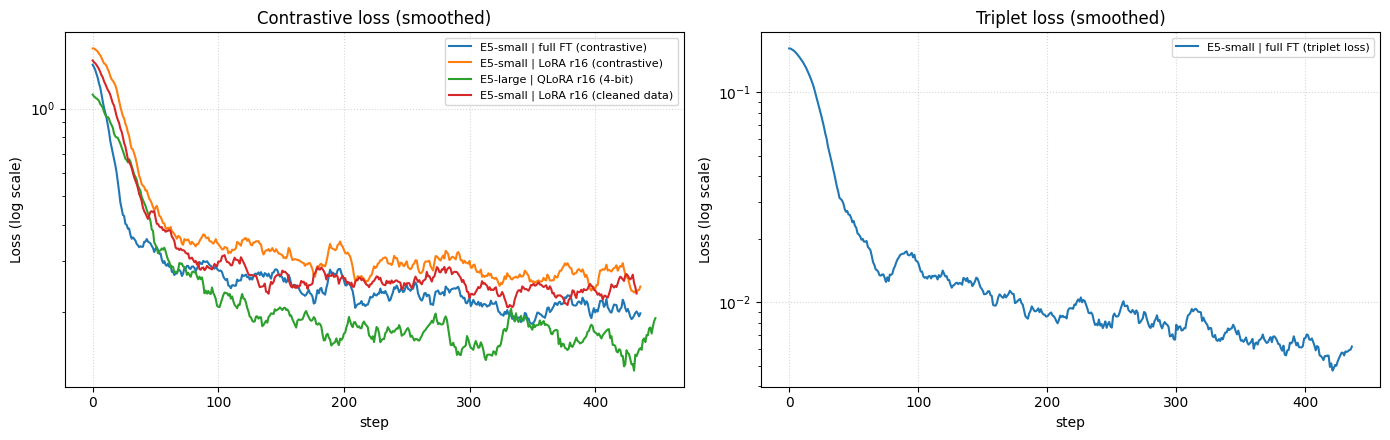

In [42]:
# Loss curves exist only for runs trained after the artifact-saving change (section 6).
def smooth(x, w=20):
    """Moving average over w steps (removes batch-to-batch noise)."""
    x = np.asarray(x)
    return np.convolve(x, np.ones(w) / w, mode='valid') if len(x) > w else x

curves = {}
for run in results:
    path = f'{RES_DIR}/loss_curve__{slugify(run)}.json'
    if os.path.exists(path):
        with open(path) as f:
            curves[run] = json.load(f)

if not curves:
    print('No saved loss curves yet. Re-run a training experiment to create them.')
else:
    fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
    for run, c in curves.items():
        ax = axes[1] if 'triplet' in run else axes[0]
        ax.plot(smooth(c), label=run)
    axes[0].set_title('Contrastive loss (smoothed)')
    axes[1].set_title('Triplet loss (smoothed)')
    for ax in axes:
        ax.set_xlabel('step')
        ax.set_ylabel('Loss (log scale)')
        ax.set_yscale('log')
        ax.legend(fontsize=8)
        ax.grid(linestyle=':', alpha=0.5)
    plt.tight_layout()
    plt.savefig(f'{RES_DIR}/loss_curves.png', dpi=150)
    plt.show()

### **Conclusion of Section 11.5 - Advanced Comparison Charts - Loss Curves Dynamics**

The chart is also saved as `results/loss_curves.png`.

#### **1. Contrastive loss (MNRL), left**
* **Fast initial drop:** every run falls steeply in the first 50-100 steps. The warm-up covers the first 45 steps (10% of the schedule). The model quickly learns to pick the positive out of the in-batch negatives, most of which are easy.
* **Slow, noisy plateau:** after ~100 steps the curves decline slowly while the learning rate decays linearly to 0. The wiggles are batch-to-batch differences in how many hard cases a batch contains.
* **Final levels (last logged 50 steps):**
  * QLoRA ≈ 0.15;
  * full FT ≈ 0.20;
  * cleaned-data LoRA ≈ 0.25;
  * LoRA ≈ 0.26.
* **Why full FT ends below LoRA:** it can change every weight, while LoRA is limited to a rank-16 update.
* **QLoRA ends lowest partly because of its batch of 32:** each query competes against 63 candidates instead of 127, an easier classification. Losses at different batch sizes are not directly comparable.
* **The cleaned-data LoRA (red) runs below the original LoRA (orange) for most of training.** Its negatives come from other product families, so they are easier to separate from the positive than the original same-family negatives. A lower loss here therefore means an easier task, not necessarily a better model; the retrieval metrics decide.

#### **2. Triplet loss, right**
* **The loss collapses toward zero:** from ≈ 0.16 to ≈ 0.015 by step ~100 and ≈ 0.006 at the end.
* **Why that means little learning:** triplet loss is exactly 0 for any triplet whose positive already beats its negative by the 0.2 margin, and such triplets contribute no gradient. A mean of 0.006 means almost every triplet in a batch is already "solved". With one mined negative per query, 17% of them random and easy, the training signal disappears early.
* **Why the model still got worse:** the updates it did make came from the few remaining hard triplets, which include the false negatives of Section 10.4. The result is the worst run on every metric (unseen P@5 0.678).

#### **Key Takeaway**
MNRL keeps a gradient for every query on every step: the softmax over 127 negatives always pushes the positive further ahead, even when it is already ranked first. The triplet loss with one fixed negative stops learning once that negative is beaten. With these negatives, contrastive training is the clear choice. A low training loss alone is not a sign of a good retriever.

## **12. Final Test Evaluation (Run Once)**

The 28 test queries were hidden during training and model selection. The model chosen on dev at this point (E5-small LoRA r16, original data) was scored once. Do not tune anything after looking at these numbers.

The cleaned-data model of Section 15 was trained after this evaluation. If it becomes the shipped model, score it on test **once** with the same code and report both.

The test baseline cell evaluates the pretrained model on the same queries, so the fine-tuning effect can be stated with a paired interval.

In [43]:
# Extract the test queries
test_queries = [r for r in records if r['split'] == 'test']
test_queries_text = [q['semantic_query'] for q in test_queries]
print(f"Loaded {len(test_queries)} independent test queries for final verification.")

# Load the winning LoRA adapter on top of the pretrained base model
winning_run_slug = slugify('E5-small | LoRA r16 (contrastive)')
winning_model_path = f"{MODEL_DIR}/{winning_run_slug}"
if not os.path.exists(winning_model_path):
    raise FileNotFoundError(f"Winning model folder not found: {winning_model_path}. Do not evaluate the baseline in its place.")
print(f"Loading winning model from: {winning_model_path}")
enc_winning = load_encoder('intfloat/e5-small-v2', 'none')                          # frozen base
enc_winning.model = PeftModel.from_pretrained(enc_winning.model, winning_model_path)  # + saved adapter

# Embed the catalog and test queries
print("Encoding catalog and test queries...")
D_test_catalog = enc_winning.encode(doc_texts, enc_winning.d_prefix, 256)
Q_test = enc_winning.encode(test_queries_text, enc_winning.q_prefix, 64)
S_test = Q_test @ D_test_catalog.T

# Metrics on all products and on unseen products only
df_test_all = evaluate(S_test, test_queries, only_unseen=False)
df_test_unseen = evaluate(S_test, test_queries, only_unseen=True)

print("\n=== FINAL TEST SPLIT RESULTS ===")
print(f"Test P@5 (All Products):     {df_test_all['P@5'].mean():.4f}")
print(f"Test P@5 (Unseen Products):  {df_test_unseen['P@5'].mean():.4f}")
print(f"Test nDCG@10 (All Products): {df_test_all['nDCG@10'].mean():.4f}")
print(f"Test MRR (All Products):     {df_test_all['MRR'].mean():.4f}")

Loaded 28 independent test queries for final verification.
Loading winning model from: /content/drive/MyDrive/IK classes/30_week 04Oct2026-LLM Ops - AI System Design- Sayan/ShopTalk/models/E5_small_LoRA_r16_contrastive


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

Encoding catalog and test queries...

=== FINAL TEST SPLIT RESULTS ===
Test P@5 (All Products):     0.9000
Test P@5 (Unseen Products):  0.8400
Test nDCG@10 (All Products): 0.9003
Test MRR (All Products):     0.9135


**Output:**
- The 28 test queries loaded, and the saved LoRA adapter was found and applied on top of the pretrained E5-small.
- **On the test split, the selected model scores:**
  - P@5 **0.900** (all products) and **0.840** (unseen products only);
  - nDCG@10 **0.900**;
  - MRR **0.914**.
- These are close to its dev values (0.895 / 0.822 / 0.903 / 0.932), so the dev results were not an artefact of selecting on dev.
- The unseen figure only covers test queries that keep at least 3 relevant products among `val`/`test` products.

In [44]:
# Same test queries, pretrained E5-small, so the fine-tuning effect on test can be stated with a paired interval.
# (The model choice was made on dev before this point, so this is a reference run, not a new selection.)
enc_base = load_encoder('intfloat/e5-small-v2', 'none')
D_base = enc_base.encode(doc_texts, enc_base.d_prefix, 256)
S_base = enc_base.encode(test_queries_text, enc_base.q_prefix, 64) @ D_base.T
df_test_base_all = evaluate(S_base, test_queries)
df_test_base_unseen = evaluate(S_base, test_queries, only_unseen=True)

rows = []
for label, fine, base in [('all products', df_test_all, df_test_base_all),
                          ('unseen products', df_test_unseen, df_test_base_unseen)]:
    a, b = base.set_index('id'), fine.set_index('id')
    ids = a.index.intersection(b.index)
    for metric in ['P@5', 'nDCG@10', 'MRR']:
        m, lo, hi = paired_ci(a.loc[ids, metric], b.loc[ids, metric])
        rows.append({'products': label, 'metric': metric, 'pretrained': a.loc[ids, metric].mean(),
                     'LoRA': b.loc[ids, metric].mean(), 'change': m, '95% CI low': lo, '95% CI high': hi})
display(pd.DataFrame(rows).round(3))
del enc_base

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

,products,metric,pretrained,LoRA,change,95% CI low,95% CI high
0,all products,P@5,0.871,0.900,0.029,-0.064,0.143
1,all products,nDCG@10,0.854,0.900,0.047,-0.032,0.139
2,all products,MRR,0.878,0.913,0.035,-0.040,0.123
3,unseen products,P@5,0.848,0.840,-0.008,-0.112,0.096
4,unseen products,nDCG@10,0.849,0.856,0.007,-0.097,0.109
5,unseen products,MRR,0.964,0.903,-0.060,-0.157,0.019


**Output: the fine-tuning effect on the hidden test queries** (LoRA minus pretrained, paired over the same queries):

| Products | Metric | Pretrained | LoRA | Change [95% CI] |
|---|---|---|---|---|
| all | P@5 | 0.871 | 0.900 | +0.029 [-0.064, 0.143] |
| all | nDCG@10 | 0.854 | 0.900 | +0.047 [-0.032, 0.139] |
| all | MRR | 0.878 | 0.913 | +0.035 [-0.040, 0.123] |
| unseen | P@5 | 0.848 | 0.840 | -0.008 [-0.112, 0.096] |
| unseen | nDCG@10 | 0.849 | 0.856 | +0.007 [-0.097, 0.109] |
| unseen | MRR | 0.964 | 0.903 | -0.060 [-0.157, 0.019] |

- **All products:** all three metrics move up by 0.03-0.05, the same direction and size as the dev nDCG gain. Every interval still crosses zero.
- **Unseen products:** no gain. P@5 and nDCG@10 are flat, and MRR drops by 0.060 (not significant).
- **Honest summary:** on held-out real queries, the fine-tuned model is not measurably better than the pretrained one. Fine-tuning clearly improved the synthetic task (`val_synth_MRR`), but the evaluation set is too small, and the synthetic queries too different from real ones, to show a reliable gain. Section 14 targets the second issue.

Successfully exported final evaluation metrics to /content/drive/MyDrive/IK classes/30_week 04Oct2026-LLM Ops - AI System Design- Sayan/ShopTalk/results/model_evaluation_summary.json


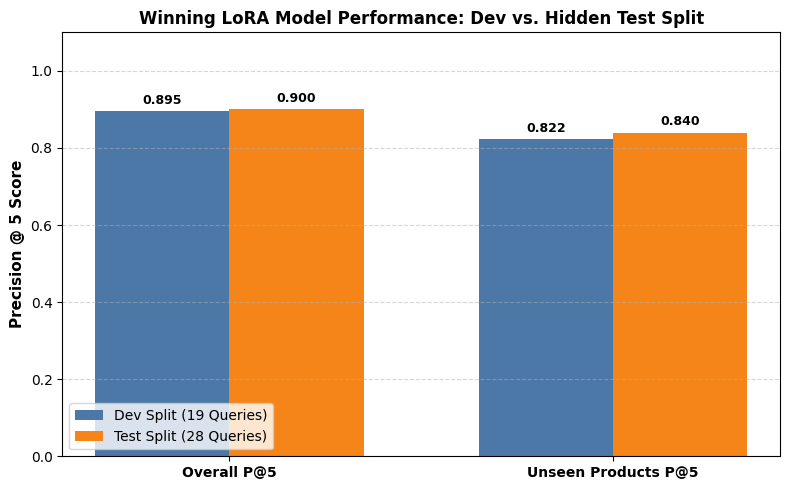

Successfully saved comparison visualization to /content/drive/MyDrive/IK classes/30_week 04Oct2026-LLM Ops - AI System Design- Sayan/ShopTalk/results/dev_vs_test_p5_comparison.png
Successfully exported catalog embeddings shape (18371, 384) to /content/drive/MyDrive/IK classes/30_week 04Oct2026-LLM Ops - AI System Design- Sayan/ShopTalk/data/embeddings/ft__E5_small_LoRA_r16_contrastive.npy


In [45]:
# Export the final evaluation metrics (dev values come straight from the results table)
lora_dev = results['E5-small | LoRA r16 (contrastive)']
metrics_summary = {
    "model_name": "E5-small | LoRA r16 (contrastive)",
    "dev_metrics": {k: float(lora_dev[k]) for k in ['P@5', 'P@5_unseen', 'nDCG@10', 'MRR']},
    "test_metrics": {
        "P@5": float(df_test_all['P@5'].mean()),
        "P@5_unseen": float(df_test_unseen['P@5'].mean()),
        "nDCG@10": float(df_test_all['nDCG@10'].mean()),
        "MRR": float(df_test_all['MRR'].mean())
    }
}
summary_path = f"{RES_DIR}/model_evaluation_summary.json"
with open(summary_path, 'w') as f:
    json.dump(metrics_summary, f, indent=4)
print(f"Successfully exported final evaluation metrics to {summary_path}")

# Dev vs test chart
labels = ['Overall P@5', 'Unseen Products P@5']
dev_scores = [metrics_summary['dev_metrics']['P@5'], metrics_summary['dev_metrics']['P@5_unseen']]
test_scores = [metrics_summary['test_metrics']['P@5'], metrics_summary['test_metrics']['P@5_unseen']]

x = np.arange(len(labels))
width = 0.35

fig, ax = plt.subplots(figsize=(8, 5))
rects1 = ax.bar(x - width/2, dev_scores, width, label='Dev Split (19 Queries)', color='#4C78A8')
rects2 = ax.bar(x + width/2, test_scores, width, label='Test Split (28 Queries)', color='#F58518')

ax.set_ylabel('Precision @ 5 Score', fontsize=11, fontweight='bold')
ax.set_title('Winning LoRA Model Performance: Dev vs. Hidden Test Split', fontsize=12, fontweight='bold')
ax.set_xticks(x)
ax.set_xticklabels(labels, fontsize=10, fontweight='bold')
ax.set_ylim(0, 1.1)
ax.legend(loc='lower left')
ax.grid(axis='y', linestyle='--', alpha=0.5)

def autolabel(rects):
    """Write each bar's value above it."""
    for rect in rects:
        height = rect.get_height()
        ax.annotate(f'{height:.3f}', xy=(rect.get_x() + rect.get_width() / 2, height),
                    xytext=(0, 3), textcoords="offset points", ha='center', va='bottom', fontsize=9, fontweight='bold')

autolabel(rects1)
autolabel(rects2)

plt.tight_layout()
plot_path = f"{RES_DIR}/dev_vs_test_p5_comparison.png"
plt.savefig(plot_path, dpi=150)
plt.show()
print(f"Successfully saved comparison visualization to {plot_path}")

# Catalog embeddings of the final model, for the vector index (notebook 07).
# Same model as the run in Section 7, so this re-writes the identical file saved by run_experiment.
emb_save_path = f"{EMB_DIR}/ft__{winning_run_slug}.npy"
np.save(emb_save_path, D_test_catalog)
print(f"Successfully exported catalog embeddings shape {D_test_catalog.shape} to {emb_save_path}")

**Output:**
- **`model_evaluation_summary.json`** records the selected model with its dev and test metrics.
- **The bar chart** compares dev (19 queries) and test (28 queries): overall P@5 0.895 vs 0.900, unseen P@5 0.822 vs 0.840. The two splits agree within about 0.02, so there is no sign that the dev-based choice overfitted the dev queries.
- **Embeddings for notebook 07:** the catalog embeddings of the selected model, shape **(18,371, 384)** (one 384-dimensional vector per product), are saved for the vector index. This is the same file `run_experiment` wrote in Section 7. If the cleaned-data model is shipped instead, use `ft__E5_small_LoRA_r16_cleaned_data.npy`.

## **13. Conclusions and Next Steps**

**Findings (original training data, Sections 7-12)**
- **Contrastive fine-tuning learned the synthetic task:** `val_synth_MRR` rose from 0.661 to 0.747-0.764 (E5-small) and from 0.688 to 0.747 (E5-large).
- **On real queries the gain is small and not significant.**
  - nDCG@10 is up about 0.03-0.04 on dev and about 0.05 on test (all products), consistently but with every paired interval crossing zero (19 dev / 28 test queries).
  - Dev P@5 is saturated and cannot rank the runs.
- **Test does not confirm a gain on unseen products:** on test, unseen-product P@5 is 0.848 for pretrained vs 0.840 for LoRA.
- **LoRA ≈ full fine-tuning in quality, within noise:** 1.3% of the trainable weights, a 2.5 MB adapter instead of 134 MB, 1.2 GB less peak memory, and about the same training time. Full fine-tuning scored higher on unseen products (0.856 vs 0.822).
- **Triplet loss is worse than the contrastive loss** on every metric.
- **QLoRA on E5-large** reached a perfect dev MRR and unseen P@5 0.844, but took 21 minutes to train and ~60 ms per query.
- **The `men's sandals` drop is explained** by two compounding data problems:
  1. **False negatives:** the `ptype`-based miner gave other sandals as negatives (61.2% of sandal queries had a footwear negative, Section 10.4).
  2. **Evaluation labels that follow `ptype`:** sandals labelled `SHOES` count as wrong (Section 10.3).
- **Single runs are noisy:** an earlier unseeded execution of the same LoRA configuration differed by 0.033 in unseen P@5. Runs are now seeded.

**Second training iteration (Sections 14-17)**
1. **Product-family negatives:** negatives are mined from `train` products only and must belong to a different product **family** than the positive. Footwear (`SHOES`, `SANDAL`, `BOOT`) and the jewelry types each form one family.
2. **Cleaned queries:** brand and boilerplate words are stripped, fused jewelry type names are split, and queries with fewer than 2 informative words are dropped.
3. **A wider candidate window** (ranks 10-300) reduces random fallbacks.
4. **Result:** the cleaned-data LoRA is the best dev run (P@5 0.937, nDCG@10 0.928, unseen P@5 0.844), recovers `men's sandals`, but loses `women's ankle boots under $60`. The improvement over the original LoRA is not statistically significant on 19 or 27 dev queries (Sections 16.4 and 17.1).

**Still to do**
- Fix the relevance rule for footwear queries in notebook 04 (count products *named* "sandal"/"ankle boot" whatever their `ptype`), then re-score. Both the sandals and the ankle-boots swings are largely this labelling problem (Sections 10.3 and 17.2).
- Decide which LoRA ships. If it is the cleaned-data model, score it on the test split **once** (Section 12 code) and use its catalog embeddings in notebook 07.
- Run `RUN_SEED_CHECK = True` (Section 15) to measure seed noise for both LoRA configurations.
- Run E5-large LoRA on an unquantized base (`RUN_LARGE_LORA`) so the 4-bit memory saving is measured.
- Grow the dev set with hand-checked relevance labels (the expanded set of Section 17.1 is a rough, rule-labelled check).
- Merge the LoRA adapter into the base before serving (`merge_and_unload()`) to remove the extra query latency.

**Commit to GitHub:**
- this notebook and `notebooks/07_vector_index.ipynb`;
- from `results/`: `finetune_dev.csv`, `model_evaluation_summary.json`, `model_comparison_cleaned_data.csv` and the `.png` charts.

Do not commit `models/` or `data/embeddings/` (large binary files).

### **13.1 - Conclusions and Next Steps - E5-Small LoRA Selection Rationale**

When choosing the model to promote to production, both **quality metrics** (retrieval performance) and **system constraints** (training speed, disk and GPU footprint, query latency) count.

| Criterion | E5-small LoRA r16 | E5-small LoRA r16, cleaned data | E5-small full FT | E5-large QLoRA r16 |
|---|---|---|---|---|
| Dev P@5 / nDCG@10 / unseen P@5 | 0.895 / 0.903 / 0.822 | 0.937 / 0.928 / 0.844 | 0.905 / 0.905 / 0.856 | 0.916 / 0.903 / 0.844 |
| Paired change vs own pretrained (nDCG@10) | +0.033, n.s. | +0.059, n.s. | +0.035, n.s. | +0.038, n.s. |
| Trainable weights | 0.44M (1.3%) | 0.44M (1.3%) | 33.4M (100%) | 2.36M (1.3%) |
| Saved artifact | 2.5 MB adapter | 2.5 MB adapter | 134 MB checkpoint | 10.2 MB adapter (+1.3 GB base) |
| Training time / peak memory (T4) | 4.4 min / 5.0 GB | 4.4 min / 5.2 GB | 4.1 min / 6.2 GB | 21.1 min / 2.8 GB |
| Query latency p50 (unmerged) | 22-31 ms | 22-31 ms | 13.7 ms | 60.2 ms |
| Embedding size (index memory) | 384 | 384 | 384 | 1,024 |

(n.s. = not statistically significant: the 95% interval crosses zero. The two LoRA rows have identical architecture, so their latency difference in Section 9 is measurement noise.)

**Why E5-small LoRA:**
- **Quality:** no configuration is significantly better than another on the dev queries, so quality does not decide.
- **Cost, which then decides:**
  - LoRA keeps E5-small's 384-dimensional index and base-model latency once merged;
  - it ships as a 2.5 MB file that can be versioned and swapped next to the shared base;
  - it needs the least training memory among the E5-small options.
- **Which LoRA:** the cleaned-data version has the best dev numbers and fixes the sandals regression, but trades it for an ankle-boots regression. Both swings come mostly from `ptype`-based labels. It is the better candidate, pending the test-split check and the label fix listed in Section 13.
- **Trade-offs:** full fine-tuning has the highest unseen-product P@5 on dev (0.856), within noise of the cleaned LoRA. E5-large is the upgrade path if a larger dev set shows a real advantage and the latency budget allows it.

## **14. Second Training Iteration: Mitigating False Negatives & Improving Query Quality**

To address the data quality issues identified in Sections 4 and 10, the following improvements are implemented:

1. **Fix the false-negative training bug:** map fine-grained `ptype` labels into **product families** (e.g. `SANDAL`, `SHOES`, `BOOT` and sneakers under `FOOTWEAR`). During negative mining, hard negatives are only selected from outside the positive item's product family.
2. **Clean up synthetic queries:** strip brand prefixes (e.g. `Amazon Brand -`, `find.`, `Rivet`) and boilerplate template words.
3. **Improve query quality:** split fused jewelry type names and drop queries with fewer than 2 informative words.
4. **Harder, safer negatives:** reduce random fallbacks by widening the candidate rank window, while keeping the family-level safety rule.

### **14.1 - Second Training Iteration - Mitigating the False-Negative Training Bug**

Fine-grained `ptype` labels are mapped into product families, for example sandals, shoes, boots and sneakers into `FOOTWEAR`. During negative mining, hard negatives are only selected from outside the positive item's product family.

**How the mapping works:**
- each `ptype` is split into words on `_`, and a family is assigned when one of its words is a family keyword;
- ABO's fused fine-jewelry types (`FINERING`, `FINEEARRING`, `FINENECKLACEBRACELETANKLET`) all start with `FINE` and map to `JEWELRY`;
- `ptype` values that match no family stay their own family, so the original behaviour is kept for them.

In [46]:
# Prerequisites from Sections 1-4 (a runtime reset requires running those sections again)
_needed = ['df', 'train_pairs', 'load_encoder', 'D0', 'train_idx', 'split', 'device', 'FINETUNE_DIR']
_missing = [v for v in _needed if v not in globals()]
assert not _missing, f'Run Sections 1-4 first; missing: {_missing}'

# 1. Product families: ptype words that belong together from a shopper's point of view.
#    Order matters: the first family whose keyword appears in the ptype wins.
FAMILY_WORDS = {
    'FOOTWEAR': {'SHOE', 'SHOES', 'SANDAL', 'SANDALS', 'BOOT', 'BOOTS', 'SNEAKER', 'SNEAKERS', 'LOAFER', 'LOAFERS',
                 'HEEL', 'HEELS', 'CLOG', 'CLOGS', 'SLIPPER', 'SLIPPERS', 'FOOTWEAR'},
    'JEWELRY': {'EARRING', 'EARRINGS', 'RING', 'RINGS', 'NECKLACE', 'BRACELET', 'ANKLET', 'PENDANT', 'JEWELRY'},
    'HOME_FURNITURE': {'CHAIR', 'SOFA', 'COUCH', 'OTTOMAN', 'TABLE', 'LAMP', 'FURNITURE', 'DESK', 'BENCH', 'STOOL'},
    'HOME_DECOR': {'ART', 'CANVAS', 'PRINT', 'POSTER', 'DECOR'},
}

def get_product_family(ptype):
    """Family for a ptype, matched on whole words; unmatched ptypes are their own family."""
    words = str(ptype).upper().split('_')
    if any(w.startswith('FINE') and len(w) > 4 for w in words):     # FINERING, FINEEARRING, FINENECKLACE...
        return 'JEWELRY'
    for family, keys in FAMILY_WORDS.items():
        if any(w in keys for w in words):
            return family
    return str(ptype)                                               # fallback: the ptype itself

# Apply product family mapping to the dataframe
df['product_family'] = df['ptype'].apply(get_product_family)

# Show every ptype that was grouped into a family, with product counts, so the mapping can be checked by eye
fam_table = df.groupby(['product_family', 'ptype']).size().rename('products').reset_index()
grouped = fam_table[fam_table['product_family'] != fam_table['ptype']]
print(f"{len(grouped)} ptypes grouped into {grouped['product_family'].nunique()} families; "
      f"{(fam_table['product_family'] == fam_table['ptype']).sum()} ptypes stay their own family")
display(grouped.sort_values(['product_family', 'products'], ascending=[True, False]))

16 ptypes grouped into 4 families; 15 ptypes stay their own family


,product_family,ptype,products
7,FOOTWEAR,SHOES,1947
5,FOOTWEAR,BOOT,954
6,FOOTWEAR,SANDAL,782
11,HOME_DECOR,WALL_ART,598
12,HOME_FURNITURE,CHAIR,1487
13,HOME_FURNITURE,HOME_FURNITURE_AND_DECOR,1166
16,HOME_FURNITURE,SOFA,842
18,HOME_FURNITURE,TABLE,706
14,HOME_FURNITURE,LAMP,441
17,HOME_FURNITURE,STOOL_SEATING,344


### **Conclusion of Section 14.1 - Second Training Iteration - Mitigating the False-Negative Training Bug**

**Output:** 16 `ptype` labels are grouped into 4 families, and the other 15 stay their own family:

| Family | `ptype` (products) |
|---|---|
| `FOOTWEAR` | `SHOES` 1,947, `BOOT` 954, `SANDAL` 782 |
| `HOME_FURNITURE` | `CHAIR` 1,487, `HOME_FURNITURE_AND_DECOR` 1,166, `SOFA` 842, `TABLE` 706, `LAMP` 441, `STOOL_SEATING` 344, `OTTOMAN` 322 |
| `JEWELRY` | `FINENECKLACEBRACELETANKLET` 886, `FINERING` 807, `FINEEARRING` 725, `NECKLACE` 270, `EARRING` 203 |
| `HOME_DECOR` | `WALL_ART` 598 |

The grouping is what a shopper would expect. `HOME_FURNITURE_AND_DECOR` is a generic bucket, so it is grouped with furniture: otherwise a generic furniture listing could still become a negative for a sofa query. Types such as `RUG`, `HOME_BED_AND_BATH`, `LIGHT_FIXTURE` or `SUITCASE` stay on their own.

#### **a. The issue being fixed**
The original miner (Section 4.3) only required a **different `ptype`**. The catalog splits one family over several `ptype` labels, so the miner often picked a sandal listed as `SHOES` as the "wrong answer" for a `SANDAL` product. 61.2% of sandal queries got a footwear negative (Section 10.4). The loss then pushed valid sandals away from sandal queries.

#### **b. The mitigation and its trade-off**
- **The new rule:** a negative must come from a **different family** than the positive, so no sandal, shoe or boot can be a negative for a sandal query.
- **The cost:** "same family, different type" negatives (a boot for a sandal query) are lost too. These would be the most informative hard negatives *if* types were labelled reliably. Here they are not, so safety wins.
- **Another consequence:** for footwear, jewelry and furniture queries, almost all near neighbours are in the same family, so the miner must look further down the ranking to find an allowed negative (see 14.3).

### **14.2 - Second Training Iteration - Synthetic Query Cleaning and Normalization**

The cleaning steps:
- strip brand and boilerplate words (e.g. *Amazon Brand -*, *find.*, *Rivet*);
- replace catalog-template phrases (`home furniture and decor`) with plain words;
- split fused jewelry type names;
- drop queries left with fewer than 2 informative words.

In [47]:
# 2. Query Cleaning Helper
# House-brand prefixes: removed only at the start of a query (a brand name later in a query can be legitimate)
BRAND_PREFIXES = ["amazon brand -", "amazon brand", "find.", "rivet", "stone & beam", "amazon essentials"]
# Boilerplate words no shopper types: removed anywhere
BOILERPLATE = re.compile(r"\b(?:amazon|brand|find)\b\.?")    # 'find.' is an Amazon house brand; its '.' is often lost
# ptype names that the generator copied into queries -> plain shopper words
PHRASES = {'home furniture and decor': 'home decor', 'home bed and bath': 'bedding',
           'finenecklacebraceletanklet': 'necklace bracelet', 'fineearring': 'earring', 'finering': 'ring'}

def clean_query(q):
    q_clean = str(q).lower().strip()
    for brand in BRAND_PREFIXES:                                   # strip house-brand prefixes
        if q_clean.startswith(brand):
            q_clean = q_clean[len(brand):].strip()
    for old, new in PHRASES.items():                               # template phrases and fused jewelry types
        q_clean = q_clean.replace(old, new)
    q_clean = BOILERPLATE.sub(' ', q_clean)
    q_clean = re.sub(r"[^a-z0-9\s'-]", ' ', q_clean)                # keep letters, digits, apostrophes, hyphens
    return ' '.join(w.strip("-'") for w in q_clean.split() if w.strip("-'"))   # trim edge hyphens/quotes, collapse spaces

def n_informative(q):
    """Words that carry meaning (stop-words and single characters excluded)."""
    return sum(1 for w in q.split() if w not in STOP and len(w) > 1)

# 3. Re-generate clean training pairs
train_pairs_clean = train_pairs.copy()
train_pairs_clean['query'] = train_pairs_clean['query'].apply(clean_query)
changed = train_pairs_clean['query'] != train_pairs['query'].str.lower()
print(f'{changed.sum()} of {len(train_pairs)} queries changed by cleaning (beyond lower-casing). Examples:')
for before, after in zip(train_pairs.loc[changed, 'query'].head(8), train_pairs_clean.loc[changed, 'query'].head(8)):
    print(f'  {before!r:50} -> {after!r}')

# Drop queries left with fewer than 2 informative words
train_pairs_clean['word_count'] = train_pairs_clean['query'].apply(n_informative)
train_pairs_clean = train_pairs_clean[train_pairs_clean['word_count'] >= 2].reset_index(drop=True)
print(f"Retained {len(train_pairs_clean)} high-quality queries out of {len(train_pairs)} after query cleaning.")

12356 of 29239 queries changed by cleaning (beyond lower-casing). Examples:
  'Amazon Brand Rivet Aerial View Black'             -> 'aerial view black'
  "Women's Tan Fashion Slippers- UK EU"              -> "women's tan fashion slippers uk eu"
  'Amazon Brand Rivet Lawson Modern Angled'          -> 'lawson modern angled'
  'Amazon Brand Stone Beam Serene Tassled'           -> 'stone beam serene tassled'
  'rug amazon stone'                                 -> 'rug stone'
  'modern throw home bed and bath'                   -> 'modern throw bedding'
  'silver finenecklacebraceletanklet'                -> 'silver necklace bracelet'
  'pendant necklace finenecklacebraceletanklet'      -> 'pendant necklace necklace bracelet'
Retained 29050 high-quality queries out of 29239 after query cleaning.


### **Conclusion of Section 14.2 - Second Training Iteration - Synthetic Query Cleaning and Normalization**

Cleaning the synthetic training queries brings the fine-tuning data closer to how people actually search.

#### **a. The problem: query-to-product leakage and noise**
The synthetic query generator left raw metadata markers in place: `lamp brand arm`, `Amazon Brand find Lace Up Wedge`, `wall desginer home furniture and decor`, `finenecklacebraceletanklet amazon plated`. These cause two problems:
- **Leakage:** catalog boilerplate ("Amazon Brand", the `ptype` name) appears in both the query and the product text. The model can learn to match on these tokens instead of on what the product is, and that shortcut does not exist for real shoppers' queries.
- **Noise:** fused or template words never occur in real queries, so training steps spent on them teach nothing that transfers.

#### **b. Output**
- **12,356 of 29,239 queries changed** beyond lower-casing (42%).
- **The printed examples show the intended effect:**
  - house brands removed: `Amazon Brand Rivet Aerial View Black` → `aerial view black`, `rug amazon stone` → `rug stone`;
  - template phrases replaced: `modern throw home bed and bath` → `modern throw bedding`;
  - fused jewelry types split: `silver finenecklacebraceletanklet` → `silver necklace bracelet`;
  - trailing hyphens trimmed and apostrophes kept: `Women's Tan Fashion Slippers- UK EU` → `women's tan fashion slippers uk eu`.
- **29,050 queries retained**: 189 were dropped for having fewer than 2 informative words.

#### **c. Remaining imperfections (minor)**
- `stone beam serene tassled`: "Stone & Beam" survives when the `&` was already lost during query generation, because the prefix list expects `stone & beam`.
- `pendant necklace necklace bracelet`: replacing a fused type next to a word it repeats leaves a duplicate.
- Sizing tokens such as `uk eu` remain.

None of these affects the comparison much, but adding `stone beam` to `BRAND_PREFIXES` and de-duplicating words would tidy the next iteration.

### **14.3 - Second Training Iteration - Harder and Safer Negative Mining**

Negatives are re-mined for the cleaned queries with the product-family rule:
1. Rank the train products with the pretrained E5-small, as in Section 4.3.
2. Skip the 10 closest products.
3. Accept only candidates whose **family** differs from the positive's.
4. Fall back to a random product of another family if none qualifies.

In [48]:
# 4. Generate Harder, Safer Negatives using Family-Level Constraints
print("Re-mining hard negatives using family safety constraints...")
WINDOW = 300                                       # candidates come from ranks 10..WINDOW of the pretrained ranking

# Encode the cleaned queries with the pretrained model (one embedding per row of train_pairs_clean)
enc0 = load_encoder('intfloat/e5-small-v2', 'none')
Q0_clean = enc0.encode(train_pairs_clean['query'].tolist(), enc0.q_prefix, 32)
del enc0

family_arr = df['product_family'].to_numpy()
neg_clean = np.zeros(len(train_pairs_clean), dtype=int)
rng = np.random.default_rng(0)
pp_clean = train_pairs_clean['item'].to_numpy()

Dt = torch.tensor(D0[train_idx], device=device)    # train products only: val/test can never become negatives

n_fallback_clean = 0
for s in range(0, len(train_pairs_clean), 2000):
    sims = torch.tensor(Q0_clean[s:s + 2000], device=device) @ Dt.T
    top = sims.topk(WINDOW, dim=1).indices.cpu().numpy()
    for k, cand in enumerate(top):
        i = s + k
        p = pp_clean[i]
        cand = train_idx[cand[10:]]                # skip the 10 closest: likely valid answers
        # Restrict negatives to a DIFFERENT product family (no sandal/shoe/boot negative for a sandal query)
        ok = [c for c in cand if family_arr[c] != family_arr[p]]
        if ok:
            neg_clean[i] = ok[rng.integers(len(ok))]
        else:                                      # fallback: random train product from another family
            n_fallback_clean += 1
            while True:
                c = train_idx[rng.integers(len(train_idx))]
                if family_arr[c] != family_arr[p]:
                    neg_clean[i] = c
                    break
del Dt

train_pairs_clean['neg'] = neg_clean
print(f"Fallback negatives with family mapping: {n_fallback_clean} of {len(train_pairs_clean)} "
      f"({n_fallback_clean / len(train_pairs_clean):.1%}; original miner: 17.3%)")

# Save new clean training set
train_pairs_clean.to_parquet(f'{FINETUNE_DIR}/train_pairs_clean.parquet')
print("Successfully exported train_pairs_clean.parquet!")

Re-mining hard negatives using family safety constraints...


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

Fallback negatives with family mapping: 9922 of 29050 (34.2%; original miner: 17.3%)
Successfully exported train_pairs_clean.parquet!


### **Conclusion of Section 14.3 - Second Training Iteration - Harder and Safer Negative Mining**

**Output:** `Fallback negatives with family mapping: 9922 of 29050 (34.2%; original miner: 17.3%)`, and `train_pairs_clean.parquet` was saved.

**Why the fallback rate is still double the original:**
- **The family rule removes every same-family product from the candidate list.** For a footwear, jewelry or furniture query, most of the nearest neighbours belong to that same family, so even ranks 10-300 often contain no allowed candidate. The miner then falls back to a random product from another family.
- **Random negatives are easy** (a sandal query vs a random lamp) and teach the model little. About a third of the cleaned training set therefore gives a weak signal. Section 17.2 shows an example: for a men's ankle boot, the original negative was a heeled sandal, and the cleaned negative is a wall-art canvas print.
- **The wider window still helped:** an earlier execution of this cell with ranks 10-100 left 39.6% of queries on fallbacks.

**Possible next steps** (not run):
- widen `WINDOW` further (the cost is a top-k over 14,678 products);
- or allow a negative from a *neighbouring* family that shares the query's attributes (for example a handbag or sock for a sandal query), so negatives stay hard without being false negatives.

## **15. Training the Second Iteration (Cleaned Dataset)**

This section trains the selected configuration (`E5-small | LoRA r16`) on the cleaned dataset (`train_pairs_clean`), which has product-family negatives and cleaned queries, to test whether it removes the false-negative damage.

### **15.1 - Training the Second Iteration - E5-Small LoRA (Cleaned Data)**

The cell runs the selected configuration (`E5-small | LoRA r16`, same hyperparameters and seed as Section 7) on `train_pairs_clean`, then shows its row in the results table next to the earlier runs.

**For a fair comparison, Section 7 runs in the same session with the same seeded code** (as it did here), so the only difference between the two LoRA runs is the training data. `RUN_SEED_CHECK = True` additionally trains both configurations with seeds 1 and 2 (~18 extra minutes), which shows how much of any difference is seed noise.

In [49]:
# Load the cleaned dataset written by Section 14.3
train_pairs_clean = pd.read_parquet(f'{FINETUNE_DIR}/train_pairs_clean.parquet')
print(f'Training on {len(train_pairs_clean)} cleaned pairs (original: {len(train_pairs)})')

LORA_KW = dict(train_kw=dict(bs=64, epochs=1, lr=2e-4), load_kw=dict(r=16))   # identical to Section 7

# Run training experiment using the cleaned pairs (pairs= is required: the default would be the original pairs)
run_experiment('E5-small | LoRA r16 (cleaned data)', S_BASE, 'lora', pairs=train_pairs_clean, seed=0, **LORA_KW)

# Optional: two more seeds per configuration to measure run-to-run noise
RUN_SEED_CHECK = False
if RUN_SEED_CHECK:
    for sd in (1, 2):
        run_experiment(f'E5-small | LoRA r16 (contrastive) seed{sd}', S_BASE, 'lora', seed=sd, **LORA_KW)
        run_experiment(f'E5-small | LoRA r16 (cleaned data) seed{sd}', S_BASE, 'lora',
                       pairs=train_pairs_clean, seed=sd, **LORA_KW)

# Display overall table of results for comparison
pd.DataFrame(results.values())[['run', 'trainable_M', 'train_min', 'P@5', 'P@5_CI', 'P@5_unseen', 'MRR', 'nDCG@10', 'val_synth_MRR']]

Training on 29050 cleaned pairs (original: 29239)
 E5-small | LoRA r16 (cleaned data)


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

  step 50/453  loss 1.0494  0.5 min
  step 100/453  loss 0.3574  0.9 min
  step 150/453  loss 0.2799  1.4 min
  step 200/453  loss 0.2635  1.8 min
  step 250/453  loss 0.2565  2.3 min
  step 300/453  loss 0.2654  2.8 min
  step 350/453  loss 0.2333  3.2 min
  step 400/453  loss 0.2366  3.7 min
  step 450/453  loss 0.2455  4.1 min
{'train_min': 4.2, 'peak_gpu_gb': 5.2, 'P@5': np.float64(0.937), 'MRR': np.float64(0.958), 'nDCG@10': np.float64(0.928), 'P@5_unseen': np.float64(0.844)}


,run,trainable_M,train_min,P@5,P@5_CI,P@5_unseen,MRR,nDCG@10,val_synth_MRR
0,E5-small | pretrained,0.00,0.0,0.895,0.79-0.97,0.778,0.958,0.870,0.661
1,E5-small | full FT (contrastive),33.36,4.1,0.905,0.77-1.00,0.856,0.951,0.905,0.764
2,E5-small | LoRA r16 (contrastive),0.44,4.4,0.895,0.77-0.99,0.822,0.932,0.903,0.747
3,E5-small | full FT (triplet loss),33.36,3.8,0.853,0.72-0.95,0.678,0.879,0.820,0.679
4,E5-large | pretrained,0.00,0.0,0.895,0.80-0.97,0.811,0.974,0.864,0.688
5,E5-large | QLoRA r16 (4-bit),2.36,21.1,0.916,0.81-0.99,0.844,1.000,0.903,0.747
6,E5-small | LoRA r16 (cleaned data),0.44,4.2,0.937,0.83-1.00,0.844,0.958,0.928,0.742


### **Conclusion of Section 15.1 - Training the Second Iteration - E5-Small LoRA (Cleaned Data)**

**Output:** the run trained on the 29,050 cleaned pairs (453 steps of 64, vs 456 for the original 29,239 pairs), with the same hyperparameters and seed as the original LoRA run of Section 7.

| | Original-data LoRA (Sec. 7) | Cleaned-data LoRA |
|---|---|---|
| Loss, step 50 → 450 | 1.204 → 0.256 | 1.049 → 0.246 |
| Time / peak GPU | 4.4 min / 5.0 GB | 4.2 min / 5.2 GB |
| Dev P@5 (95% CI) | 0.895 (0.77-0.99) | **0.937** (0.83-1.00) |
| Dev P@5 unseen | 0.822 | **0.844** |
| Dev MRR | 0.932 | **0.958** |
| Dev nDCG@10 | 0.903 | **0.928** |
| `val_synth_MRR` | 0.747 | 0.742 |

- **The loss is lower from the start** (1.05 vs 1.20 over the first 50 steps). The most likely reason is that family-filtered negatives (34% of them random) are easier to separate from the positive than the original same-family negatives.
- **All four dev metrics improve:** P@5 +0.042, unseen P@5 +0.022, MRR +0.026, nDCG@10 +0.025. This run now has the highest dev P@5 and nDCG@10 in the notebook.
- **`val_synth_MRR` is flat** (0.747 → 0.742). It is measured on uncleaned synthetic val queries, which still contain the boilerplate the model no longer trains on, so a small drop is expected and not a concern.
- **Significance:** these are single seeded runs, and the per-query analysis (Section 16.4) shows the gain comes from a few queries moving in both directions. The paired intervals decide whether it is real.
- **The optional `RUN_SEED_CHECK`** was not run. Turning it on adds two seeds per configuration (~18 min) and gives a direct measure of seed noise.

## **16. Before vs. After Cleaning Results & Performance Visualization**

This section compares the original LoRA (`E5-small | LoRA r16 (contrastive)`, trained on the original pairs) with the cleaned-data LoRA (`E5-small | LoRA r16 (cleaned data)`): overall metrics, the `men's sandals` query, and per-query changes. Both runs use the same seed and hyperparameters; only the training pairs differ. Labels such as "Buggy" and "Mitigated" inside the charts mean "original data" and "cleaned data".

### **16.1 - Performance Visualization - Before vs. After Cleaning Overall Metrics**

A grouped bar chart compares the two LoRA runs on dev P@5, unseen-product P@5, MRR and nDCG@10.

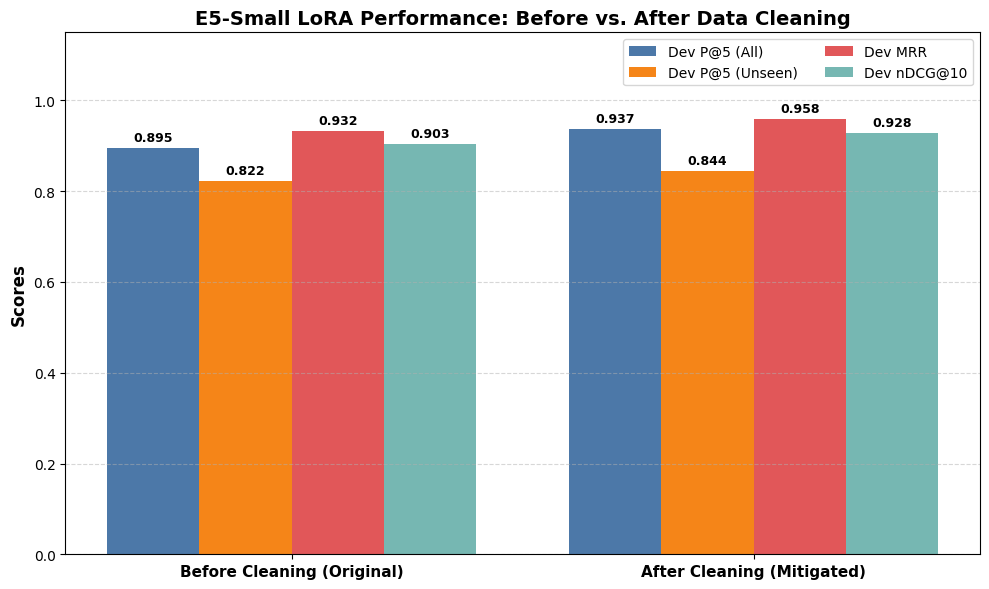

In [50]:
# Extract runs
runs_to_compare = ['E5-small | LoRA r16 (contrastive)', 'E5-small | LoRA r16 (cleaned data)']
labels = ['Before Cleaning (Original)', 'After Cleaning (Mitigated)']

# Gather metrics
p5_scores = [results[run]['P@5'] for run in runs_to_compare]
p5_unseen = [results[run]['P@5_unseen'] for run in runs_to_compare]
mrr_scores = [results[run]['MRR'] for run in runs_to_compare]
ndcg_scores = [results[run]['nDCG@10'] for run in runs_to_compare]

x = np.arange(len(labels))
width = 0.2

fig, ax = plt.subplots(figsize=(10, 6))

# Four bars per run, offset around the run's x position
rects1 = ax.bar(x - 1.5*width, p5_scores, width, label='Dev P@5 (All)', color='#4C78A8')
rects2 = ax.bar(x - 0.5*width, p5_unseen, width, label='Dev P@5 (Unseen)', color='#F58518')
rects3 = ax.bar(x + 0.5*width, mrr_scores, width, label='Dev MRR', color='#E15759')
rects4 = ax.bar(x + 1.5*width, ndcg_scores, width, label='Dev nDCG@10', color='#76B7B2')

ax.set_ylabel('Scores', fontsize=12, fontweight='bold')
ax.set_title('E5-Small LoRA Performance: Before vs. After Data Cleaning', fontsize=14, fontweight='bold')
ax.set_xticks(x)
ax.set_xticklabels(labels, fontsize=11, fontweight='bold')
ax.set_ylim(0, 1.15)
ax.legend(loc='upper right', ncol=2)
ax.grid(axis='y', linestyle='--', alpha=0.5)

def autolabel(rects):
    """Write each bar's value above it."""
    for rect in rects:
        height = rect.get_height()
        ax.annotate(f'{height:.3f}',
                    xy=(rect.get_x() + rect.get_width() / 2, height),
                    xytext=(0, 3), textcoords="offset points",
                    ha='center', va='bottom', fontsize=9, fontweight='bold')

autolabel(rects1)
autolabel(rects2)
autolabel(rects3)
autolabel(rects4)

plt.tight_layout()
plt.savefig(f'{RES_DIR}/before_vs_after_cleaning_comparison.png', dpi=150)
plt.show()

### **Conclusion of Section 16.1 - Before vs. After Cleaning Overall Metrics**

**Output:**

| | Dev P@5 | Dev P@5 unseen | Dev MRR | Dev nDCG@10 |
|---|---|---|---|---|
| Before cleaning (original data) | 0.895 | 0.822 | 0.932 | 0.903 |
| After cleaning | 0.937 | 0.844 | 0.958 | 0.928 |
| Change | +0.042 | +0.022 | +0.026 | +0.025 |

**Reading:** the cleaned-data model is ahead on all four metrics. The changes are in the range that seed noise alone produced in an earlier unseeded execution (0.01-0.03), apart from P@5. Section 16.4 tests them with paired intervals, and Section 16.2 onward shows which queries produce them.

### **16.2 - Performance Visualization - Top Results for "men's sandals"**

`show_top` (Section 10.3) prints the top 5 results for `men's sandals` under the pretrained model and the two LoRA runs, with the rank of the first relevant product.

In [51]:
show_top("men's sandals", [
    'E5-small | pretrained',
    'E5-small | LoRA r16 (contrastive)',
    'E5-small | LoRA r16 (cleaned data)'
])

Query: "men's sandals" | 51 relevant products

--- E5-small | pretrained | first relevant result at rank: 1 ---
  0.885 [REL] SANDAL                 Amazon brand: find. Men's Sandals Without Heels
  0.881 [---] SHOES                  Amazon Brand - Symbol Men's Tan Sandals-11 UK/India (45 EU) (AZ-KY-336
  0.881 [REL] SANDAL                 Amazon Brand - find. Men's Open Toe Sandals, Black (Rio Black), 12 UK
  0.880 [REL] SANDAL                 Amazon Brand - find. Men's Open Toe Sandals, Black (Rio Black), 7 UK
  0.879 [---] SHOES                  Amazon Brand - Symbol Men's Brown Sandals-11 UK/India (45 EU) (AZ-KY-3

--- E5-small | LoRA r16 (contrastive) | first relevant result at rank: 5 ---
  0.629 [---] SHOES                  Amazon Brand - Symbol Men's Sandals-10 UK (44 EU) (11 US) (AZ-KY-409B)
  0.627 [---] SHOES                  Amazon Brand - Symbol Men's Sandals
  0.626 [---] SHOES                  Centrino Men's 6108-01 M Tan Fisherman Sandals-11 UK (45 EU) (12 US) (
  0.619

### **Conclusion of Section 16.2 - Top Results for "men's sandals"**

| Run | First relevant rank | Top 5 |
|---|---|---|
| Pretrained | **1** | 3 `SANDAL` [REL] + 2 `SHOES`-labelled men's sandals [---]; scores ≈ 0.88 |
| Original-data LoRA | **5** | 4 `SHOES`-labelled men's sandals [---], then `find. Men's Open Toe Sandals` [REL]; scores ≈ 0.62-0.63 |
| Cleaned-data LoRA | **1** | 5 `SANDAL` [REL]: `find. Men's Sandals Without Heels`, the Woven Crossover sandal and three Chester Woven Cross Over sandals; scores ≈ 0.66-0.68 |

**Reading:**
- **The regression is gone for this query:** the cleaned-data model puts relevant sandals in all of the top 5 positions, better than the pretrained model (3 of 5).
- **This is consistent with the false-negative fix:** under the original data, `SANDAL` products were trained with other sandals as negatives, and the model pushed them below the `SHOES`-labelled sandals. With family-level negatives, no sandal is ever a negative for a sandal query.
- **But it is partly the label effect in reverse:** every top-5 product in all three runs is a men's sandal by name. The cleaned model now happens to prefer the `SANDAL`-labelled ones, which the relevance rule counts. Section 17.2 shows the same model preferring `SHOES`-labelled products for ankle boots, where the rule penalises it. Part of both swings is which label the model happens to favour among equally valid products.

### **16.3 - Performance Visualization - Deep Dive on the Men's Sandals Retrieval Query**

Two views of the `men's sandals` ranking under the pretrained model and the two LoRA runs:
- **Left:** the cosine similarity of the top 25 results. Green circles are relevant and red crosses are not; dashed lines trace each run's scores.
- **Right:** how many of the top 50 results are relevant.

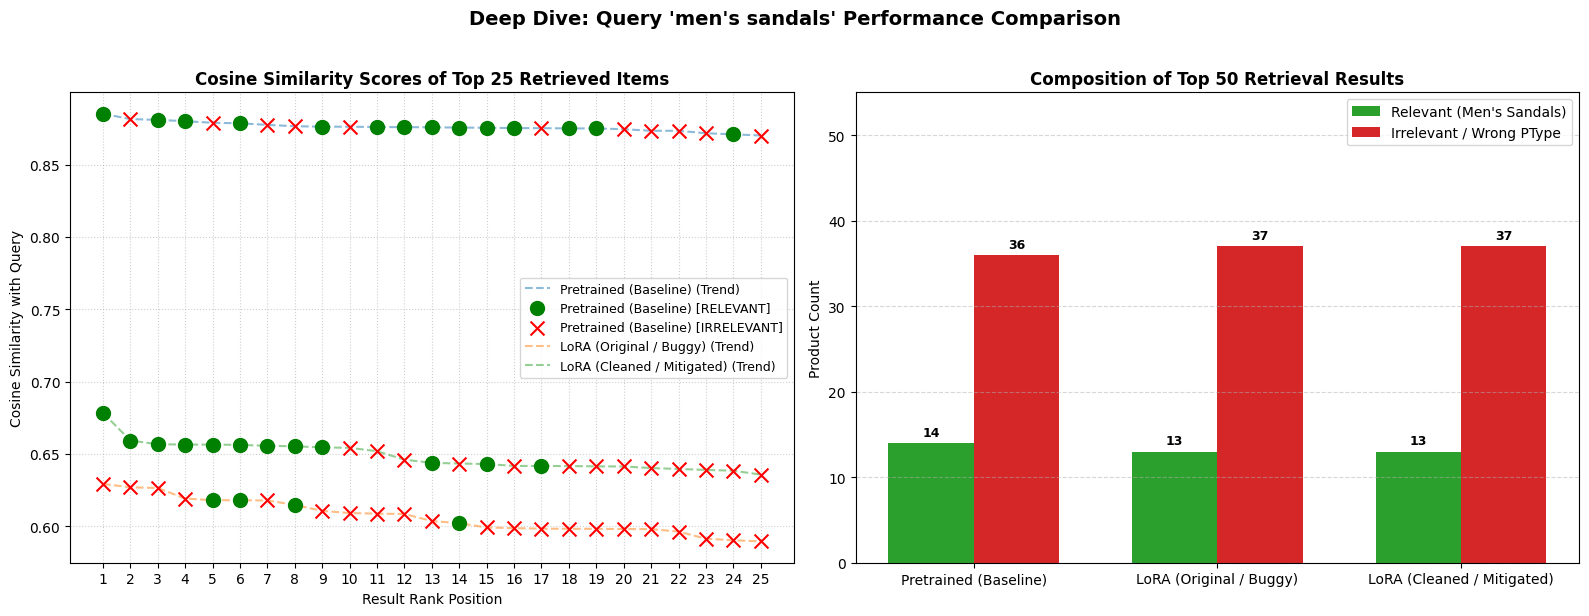

In [52]:
# 1. Setup metadata for query "men's sandals"
q_text = "men's sandals"
q_dict = next(x for x in dev if x['query'] == q_text)
qi = dev.index(q_dict)
elig = elig_mask(q_dict)
rel = rel_bool[q_dict['id']]

# We will compare three specific experimental runs
runs_to_plot = [
    'E5-small | pretrained',
    'E5-small | LoRA r16 (contrastive)',
    'E5-small | LoRA r16 (cleaned data)'
]
labels_to_plot = ['Pretrained (Baseline)', 'LoRA (Original / Buggy)', 'LoRA (Cleaned / Mitigated)']

# Extract top scores and relevance labels for visualization
all_run_scores = {}
all_run_relevance = {}

for run in runs_to_plot:
    # Load the corresponding catalog embeddings saved during the run
    D = np.load(f'{EMB_DIR}/ft__{slugify(run)}.npy')
    # Dot product of catalog with query's saved embedding
    scores = D @ query_emb[run][qi]
    # Rank
    top_indices = rank_top(scores, elig, k=50)

    all_run_scores[run] = scores[top_indices]
    all_run_relevance[run] = rel[top_indices]

# --- PLOT 1: Cosine Similarity Distributions for Sandals vs Shoes ---
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Scatter/Line plot showing scores of top 25 candidates
for i, (run, label) in enumerate(zip(runs_to_plot, labels_to_plot)):
    scores = all_run_scores[run][:25]
    is_rel = all_run_relevance[run][:25]

    # Plot relevant items (SANDAL) as green circles, and irrelevant footwear/items as red X's
    rel_idx = np.where(is_rel)[0]
    irrel_idx = np.where(~is_rel)[0]

    axes[0].plot(range(1, 26), scores, label=f"{label} (Trend)", linestyle='--', alpha=0.5)
    if len(rel_idx) > 0:
        axes[0].scatter(rel_idx + 1, scores[rel_idx], color='green', marker='o', s=100,
                         label=f"{label} [RELEVANT]" if i==0 else "", zorder=3)
    if len(irrel_idx) > 0:
        axes[0].scatter(irrel_idx + 1, scores[irrel_idx], color='red', marker='x', s=100,
                         label=f"{label} [IRRELEVANT]" if i==0 else "", zorder=3)

axes[0].set_title("Cosine Similarity Scores of Top 25 Retrieved Items", fontsize=12, fontweight='bold')
axes[0].set_xlabel("Result Rank Position", fontsize=10)
axes[0].set_ylabel("Cosine Similarity with Query", fontsize=10)
axes[0].set_xticks(range(1, 26))
axes[0].grid(True, linestyle=':', alpha=0.6)
axes[0].legend(fontsize=9)

# --- PLOT 2: Number of Relevant vs Irrelevant Items in Top 50 ---
x = np.arange(len(labels_to_plot))
width = 0.35

rel_counts = [int(all_run_relevance[run][:50].sum()) for run in runs_to_plot]
irrel_counts = [50 - r for r in rel_counts]

rects1 = axes[1].bar(x - width/2, rel_counts, width, label='Relevant (Men\'s Sandals)', color='#2ca02c')
rects2 = axes[1].bar(x + width/2, irrel_counts, width, label='Irrelevant / Wrong PType', color='#d62728')

axes[1].set_title("Composition of Top 50 Retrieval Results", fontsize=12, fontweight='bold')
axes[1].set_xticks(x)
axes[1].set_xticklabels(labels_to_plot, fontsize=10)
axes[1].set_ylabel("Product Count", fontsize=10)
axes[1].set_ylim(0, 55)
axes[1].grid(axis='y', linestyle='--', alpha=0.5)
axes[1].legend(loc='upper right')

# Annotate counts
def label_bars(rects, ax):
    for rect in rects:
        height = rect.get_height()
        ax.annotate(f'{height}',
                    xy=(rect.get_x() + rect.get_width() / 2, height),
                    xytext=(0, 3), textcoords="offset points",
                    ha='center', va='bottom', fontsize=9, fontweight='bold')

label_bars(rects1, axes[1])
label_bars(rects2, axes[1])

plt.suptitle(f"Deep Dive: Query 'men's sandals' Performance Comparison", fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.savefig(f'{RES_DIR}/sandals_vs_shoes_mitigation_deepdive.png', dpi=150, bbox_inches='tight')
plt.show()

### **Conclusion of Section 16.3 - Deep Dive on the Men's Sandals Retrieval Query**

**How to read the left plot:**
- **Three bands:** the top band (≈ 0.87-0.89) is the pretrained model, the middle band (≈ 0.64-0.68) the cleaned-data LoRA, and the bottom band (≈ 0.59-0.63) the original-data LoRA.
- **The vertical gaps are not quality differences:** they are the score-scale shift caused by contrastive training at temperature 0.02 (Section 5d). Only the order of green and red markers within each band matters.
- **Marker colours mark relevance only** (green = relevant, red = not); the legend labels them only for the first run.

**What the charts show:**
1. **Top 25 (left):**
   - **Pretrained:** relevant sandals are spread through the list, starting at rank 1.
   - **Original-data LoRA:** ranks 1-4 are red (the `SHOES`-labelled "Men's Sandals" products), and only 4 green markers appear in the top 25 (ranks 5, 6, 8, 14).
   - **Cleaned-data LoRA:** ranks 1-9 are all green, then mostly red with a few green (ranks 13, 15, 17).
2. **Top 50 (right):** relevant products: pretrained **14**, original-data LoRA **13**, cleaned-data LoRA **13**.

**Reading:** the cleaned model concentrates the relevant sandals at the very top (where P@5 and nDCG@10 look), but the total in the top 50 is unchanged at 13. Cleaning moved relevant sandals up the list; it did not bring new ones into it. Below rank ~12, the remaining non-relevant results are largely the `SHOES`-labelled sandals again, which only a label fix can count correctly.

### **16.4 - Performance Visualization - Query-Level Delta Performance Comparison**

For every dev query, this compares the cleaned-data LoRA with the original LoRA on P@5, MRR and nDCG@10.

=== Cleaned vs original LoRA: 5 of 19 dev queries changed (nDCG@10: 3 up, 2 down) ===


,Original P@5,Cleaned P@5,Original MRR,Cleaned MRR,Original nDCG@10,Cleaned nDCG@10,Delta nDCG
query,,,,,,,
men's sandals,0.2,1.0,0.2,1.0,0.233,0.936,0.703
a ring with a gemstone,0.2,0.6,0.5,1.0,0.212,0.466,0.254
a black leather wallet,0.8,1.0,1.0,1.0,0.851,0.936,0.085
comfortable walking shoes,1.0,1.0,1.0,1.0,1.000,0.934,-0.066
women's ankle boots under $60,0.8,0.2,1.0,0.2,0.861,0.367,-0.494


,metric,original,cleaned,change,95% CI low,95% CI high
0,P@5,0.895,0.937,0.042,-0.063,0.158
1,nDCG@10,0.903,0.928,0.025,-0.060,0.125
2,MRR,0.932,0.958,0.026,-0.100,0.153


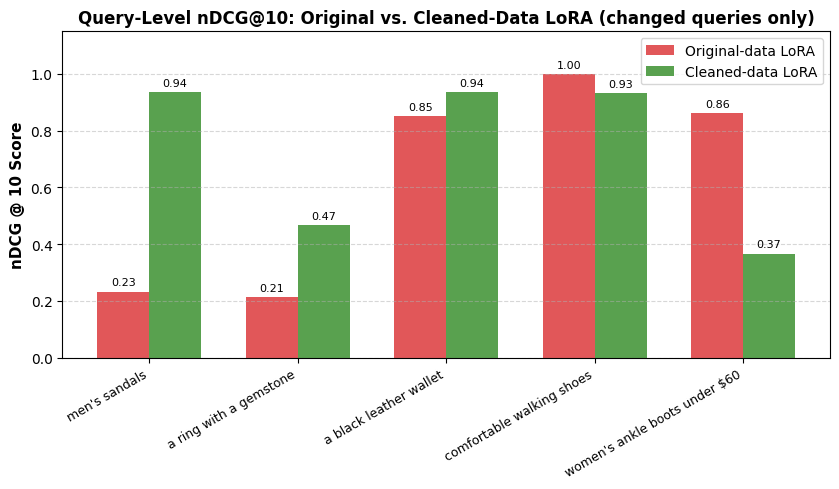

In [53]:
# 1. Align per-query evaluation metrics of the two LoRA runs
orig_run, clean_run = 'E5-small | LoRA r16 (contrastive)', 'E5-small | LoRA r16 (cleaned data)'
orig_df = per_query_res[orig_run].set_index('query')
clean_df = per_query_res[clean_run].set_index('query')

# 2. Compute per-query deltas (cleaned - original)
comparison = pd.DataFrame({
    'Original P@5': orig_df['P@5'], 'Cleaned P@5': clean_df['P@5'],
    'Original MRR': orig_df['MRR'], 'Cleaned MRR': clean_df['MRR'],
    'Original nDCG@10': orig_df['nDCG@10'], 'Cleaned nDCG@10': clean_df['nDCG@10'],
})
comparison['Delta P@5'] = comparison['Cleaned P@5'] - comparison['Original P@5']
comparison['Delta MRR'] = comparison['Cleaned MRR'] - comparison['Original MRR']
comparison['Delta nDCG'] = comparison['Cleaned nDCG@10'] - comparison['Original nDCG@10']

# Every query that changed on any metric, best improvement first, worst regression last
deltas = ['Delta P@5', 'Delta MRR', 'Delta nDCG']
changed_q = comparison[(comparison[deltas].abs() > 1e-9).any(axis=1)].sort_values('Delta nDCG', ascending=False)
n_up, n_down = (changed_q['Delta nDCG'] > 1e-9).sum(), (changed_q['Delta nDCG'] < -1e-9).sum()
print(f'=== Cleaned vs original LoRA: {len(changed_q)} of {len(comparison)} dev queries changed '
      f'(nDCG@10: {n_up} up, {n_down} down) ===')
display(changed_q[['Original P@5', 'Cleaned P@5', 'Original MRR', 'Cleaned MRR',
                   'Original nDCG@10', 'Cleaned nDCG@10', 'Delta nDCG']].round(3))

# 3. Paired 95% intervals over all dev queries (unchanged queries count as 0 change)
a, b = per_query_res[orig_run].set_index('id'), per_query_res[clean_run].set_index('id')
ids = a.index.intersection(b.index)
ci_rows = []
for metric in ['P@5', 'nDCG@10', 'MRR']:
    m, lo, hi = paired_ci(a.loc[ids, metric], b.loc[ids, metric])
    ci_rows.append({'metric': metric, 'original': a.loc[ids, metric].mean(), 'cleaned': b.loc[ids, metric].mean(),
                    'change': m, '95% CI low': lo, '95% CI high': hi})
display(pd.DataFrame(ci_rows).round(3))

# 4. Chart: nDCG@10 of every changed query, original vs cleaned
if not changed_q.empty:
    labels = [q[:30] + '...' if len(q) > 30 else q for q in changed_q.index]
    x = np.arange(len(labels))
    width = 0.35
    fig, ax = plt.subplots(figsize=(max(8, 1.1 * len(labels) + 3), 5))
    rects1 = ax.bar(x - width/2, changed_q['Original nDCG@10'], width, label='Original-data LoRA', color='#E15759')
    rects2 = ax.bar(x + width/2, changed_q['Cleaned nDCG@10'], width, label='Cleaned-data LoRA', color='#59A14F')
    ax.set_ylabel('nDCG @ 10 Score', fontsize=11, fontweight='bold')
    ax.set_title('Query-Level nDCG@10: Original vs. Cleaned-Data LoRA (changed queries only)', fontsize=12, fontweight='bold')
    ax.set_xticks(x)
    ax.set_xticklabels(labels, rotation=30, ha='right', fontsize=9)
    ax.set_ylim(0, 1.15)
    ax.legend(loc='upper right')
    ax.grid(axis='y', linestyle='--', alpha=0.5)
    for rect in list(rects1) + list(rects2):                  # value labels
        h = rect.get_height()
        ax.annotate(f'{h:.2f}', xy=(rect.get_x() + rect.get_width()/2, h),
                    xytext=(0, 3), textcoords="offset points", ha='center', va='bottom', fontsize=8)
    plt.tight_layout()
    plt.savefig(f'{RES_DIR}/mitigation_query_changes.png', dpi=150, bbox_inches='tight')
    plt.show()
else:
    print("No query changed between these two runs.")

### **Conclusion of Section 16.4 - Query-Level Delta Performance Comparison**

**Output:** 5 of 19 dev queries changed (nDCG@10: 3 up, 2 down):

| Query | P@5 | MRR | nDCG@10 |
|---|---|---|---|
| `men's sandals` | 0.2 → 1.0 | 0.2 → 1.0 | 0.233 → 0.936 (+0.703) |
| `a ring with a gemstone` | 0.2 → 0.6 | 0.5 → 1.0 | 0.212 → 0.466 (+0.254) |
| `a black leather wallet` | 0.8 → 1.0 | 1.0 → 1.0 | 0.851 → 0.936 (+0.085) |
| `comfortable walking shoes` | 1.0 → 1.0 | 1.0 → 1.0 | 1.000 → 0.934 (-0.066) |
| `women's ankle boots under $60` | 0.8 → 0.2 | 1.0 → 0.2 | 0.861 → 0.367 (-0.494) |

Paired change over all 19 queries (cleaned minus original):

| Metric | Original | Cleaned | Change [95% CI] |
|---|---|---|---|
| P@5 | 0.895 | 0.937 | +0.042 [-0.063, 0.158] |
| nDCG@10 | 0.903 | 0.928 | +0.025 [-0.060, 0.125] |
| MRR | 0.932 | 0.958 | +0.026 [-0.100, 0.153] |

**Reading:**
- **Two large swings dominate the average:** the sandals gain (+0.70 nDCG@10) and the ankle-boots loss (-0.49). Without these two footwear queries the change is small and positive (rings, wallet).
- **No interval excludes zero.** With 19 queries, a gain of this size is not statistically distinguishable from noise.
- **The change sits where it was aimed:** 14 of the 19 queries are untouched, and the footwear queries, where the family negatives act, are the ones that move most. But they moved in both directions.

The chart shows nDCG@10 of the five changed queries for both models.

### **16.5 - Performance Visualization - Comparative Per-Query Heatmap Across All Runs**

This heatmap repeats Section 11.2 with the current per-query results: the P@5 change of every fine-tuned run against its pretrained baseline, with the worst-affected queries on top. It checks that the cleaned run introduces no new local regressions.

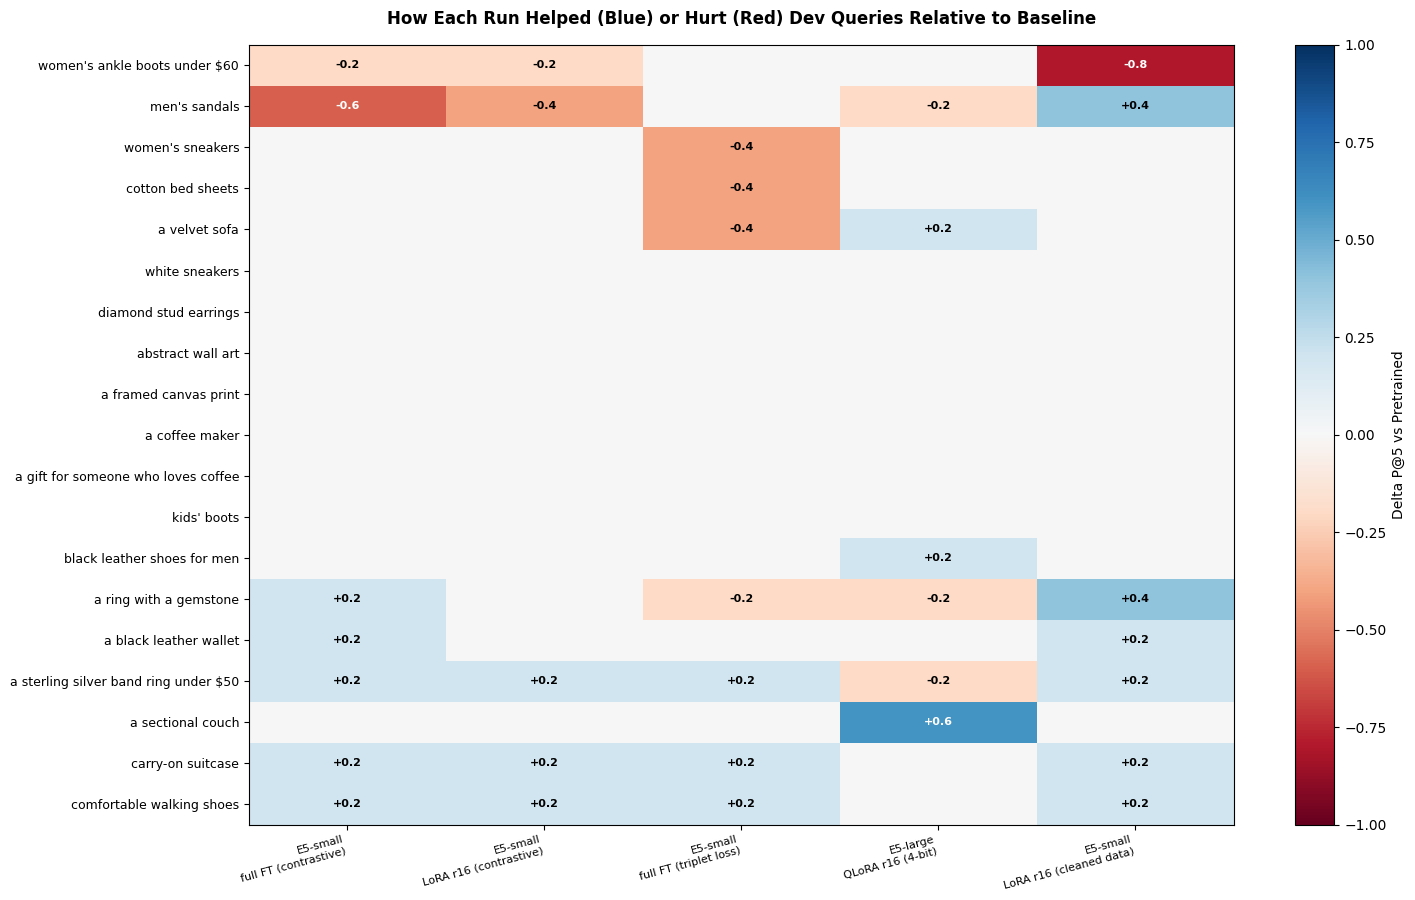

Successfully saved comparative heatmap to /content/drive/MyDrive/IK classes/30_week 04Oct2026-LLM Ops - AI System Design- Sayan/ShopTalk/results/heatmap_all_models_query_change.png


In [54]:
# 1. Align per-query scores for all fine-tuned models vs their corresponding pretrained baseline
delta_all = {}

for run in per_query_res:
    if 'pretrained' in run:
        continue
    base_run = run.split(' | ')[0] + ' | pretrained'
    if base_run in per_query_res:
        a = per_query_res[base_run].set_index('query')['P@5']
        b = per_query_res[run].set_index('query')['P@5']
        delta_all[run.replace(' | ', '\n')] = b - a

H_all = pd.DataFrame(delta_all)
# Sort by the average change across runs (worst affected queries on top)
H_all = H_all.loc[H_all.mean(axis=1).sort_values().index]

# 2. Render the comparative heatmap
fig, ax = plt.subplots(figsize=(2.2 * H_all.shape[1] + 4, 0.4 * len(H_all) + 1.5))
im = ax.imshow(H_all.values, cmap='RdBu', vmin=-1.0, vmax=1.0, aspect='auto')

# Configure axes
ax.set_xticks(range(H_all.shape[1]))
ax.set_xticklabels(H_all.columns, fontsize=8, rotation=15, ha='right')
ax.set_yticks(range(len(H_all)))
ax.set_yticklabels(H_all.index, fontsize=9)

# Add numeric annotations to cells (white text on dark cells for contrast)
for i in range(H_all.shape[0]):
    for j in range(H_all.shape[1]):
        val = H_all.values[i, j]
        if not np.isnan(val) and abs(val) > 1e-9:
            text_color = 'white' if abs(val) > 0.4 else 'black'
            ax.text(j, i, f'{val:+.1f}', ha='center', va='center', fontsize=8, fontweight='bold', color=text_color)

fig.colorbar(im, ax=ax, label='Delta P@5 vs Pretrained')
ax.set_title("How Each Run Helped (Blue) or Hurt (Red) Dev Queries Relative to Baseline", fontsize=12, fontweight='bold', pad=15)
plt.tight_layout()

# Save the plot artifact
comp_heatmap_path = f'{RES_DIR}/heatmap_all_models_query_change.png'
plt.savefig(comp_heatmap_path, dpi=150, bbox_inches='tight')
plt.show()

print(f"Successfully saved comparative heatmap to {comp_heatmap_path}")

### **Conclusion of Section 16.5 - Comparative Per-Query Heatmap Across All Runs**

**Output:** the same heatmap as Section 11.2 (the per-query results are identical). Read it as a final check that the cleaned-data run introduces no new problems outside footwear:

* **Outside footwear, the cleaned column only gains:** `a ring with a gemstone` +0.4; `a black leather wallet`, `a sterling silver band ring under $50`, `carry-on suitcase` and `comfortable walking shoes` +0.2. No non-footwear query got worse.
* **In footwear, it trades one query for another:**
  * `men's sandals`: +0.4 (the only blue cell for this query across all runs);
  * `women's ankle boots under $60`: -0.8, the worst cell in the chart. The original-data runs lost only -0.2 there.
* **The other footwear queries** (`kids' boots`, `women's sneakers`, `white sneakers`, `black leather shoes for men`) are unchanged.

The ankle-boots drop is the one result that needs explaining before shipping this model. Section 17.2 shows it is mostly the same `ptype` labelling problem as for sandals, in the opposite direction.

### **16.6 - Performance Visualization - Men's Sandals Retrieval - Original vs. Cleaned**

This cell prints the top 5 results for `men's sandals` side by side for the two LoRA runs, and charts how many relevant sandals each run places in its top 5 and top 10.

=== TOP 5 PRODUCTS RETRIEVED FOR 'MEN'S SANDALS' ===

[BUGGY MODEL (ORIGINAL)]                                     | [MITIGATED MODEL (CLEANED DATA)]                            
-----------------------------------------------------------------------------------------------------------------------------
#1 [---] Amazon Brand - Symbol Men's Sandals (SHOES)      (0.629) | #1 [REL] Amazon brand: find. Men's Sandals W (SANDAL)     (0.678)
#2 [---] Amazon Brand - Symbol Men's Sandals (SHOES)      (0.627) | #2 [REL] Amazon Brand - find. Men’s Woven Cr (SANDAL)     (0.659)
#3 [---] Centrino Men's 6108-01 M Tan Fisher (SHOES)      (0.626) | #3 [REL] find. Amazon Brand Chester Woven Cr (SANDAL)     (0.657)
#4 [---] Amazon Brand - Symbol Men's Sandals (SHOES)      (0.619) | #4 [REL] find. Amazon Brand Chester Woven Cr (SANDAL)     (0.656)
#5 [REL] Amazon Brand - find. Men's Open Toe (SANDAL)     (0.618) | #5 [REL] find. Amazon Brand Chester Woven Cr (SANDAL)     (0.656)


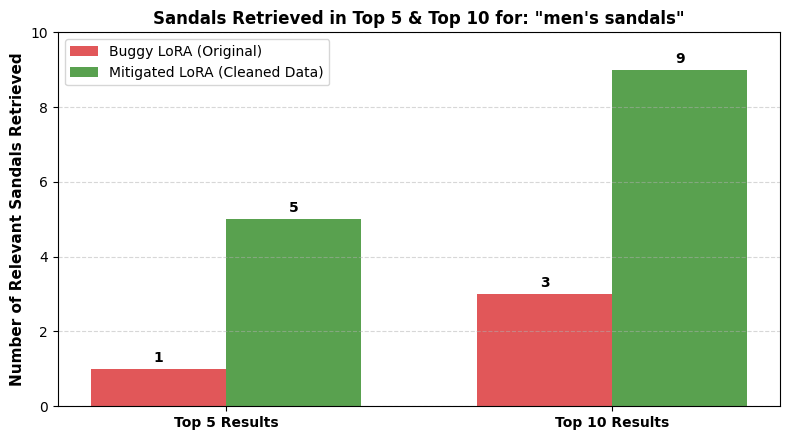

In [55]:
# 1. Align query data for "men's sandals"
q_text = "men's sandals"
q_dict = next(x for x in dev if x['query'] == q_text)
qi = dev.index(q_dict)
elig = elig_mask(q_dict)
rel = rel_bool[q_dict['id']]

buggy_run = 'E5-small | LoRA r16 (contrastive)'
cleaned_run = 'E5-small | LoRA r16 (cleaned data)'

# Load and score
D_buggy = np.load(f'{EMB_DIR}/ft__{slugify(buggy_run)}.npy')
D_cleaned = np.load(f'{EMB_DIR}/ft__{slugify(cleaned_run)}.npy')

scores_buggy = D_buggy @ query_emb[buggy_run][qi]
scores_cleaned = D_cleaned @ query_emb[cleaned_run][qi]

top_buggy = rank_top(scores_buggy, elig, k=10)
top_cleaned = rank_top(scores_cleaned, elig, k=10)

# Print Side-by-Side Comparison
print(f"=== TOP 5 PRODUCTS RETRIEVED FOR '{q_text.upper()}' ===\n")
print(f"{'[BUGGY MODEL (ORIGINAL)]':<60} | {'[MITIGATED MODEL (CLEANED DATA)]':<60}")
print("-"*125)
for rank in range(5):
    idx_b = top_buggy[rank]
    idx_c = top_cleaned[rank]

    rel_b = "[REL]" if rel[idx_b] else "[---]"
    rel_c = "[REL]" if rel[idx_c] else "[---]"

    name_b = f"{df.iloc[idx_b]['name_en'][:35]} ({df.iloc[idx_b]['ptype']})"
    name_c = f"{df.iloc[idx_c]['name_en'][:35]} ({df.iloc[idx_c]['ptype']})"

    print(f"#{rank+1} {rel_b} {name_b:<48} ({scores_buggy[idx_b]:.3f}) | #{rank+1} {rel_c} {name_c:<48} ({scores_cleaned[idx_c]:.3f})")

# 2. Render a simple verification chart: relevant products in the top 5 and top 10
buggy_top5_rel = rel[top_buggy[:5]].sum()
cleaned_top5_rel = rel[top_cleaned[:5]].sum()
buggy_top10_rel = rel[top_buggy[:10]].sum()
cleaned_top10_rel = rel[top_cleaned[:10]].sum()

labels = ['Top 5 Results', 'Top 10 Results']
buggy_counts = [buggy_top5_rel, buggy_top10_rel]
cleaned_counts = [cleaned_top5_rel, cleaned_top10_rel]

x = np.arange(len(labels))
width = 0.35

fig, ax = plt.subplots(figsize=(8, 4.5))
rects1 = ax.bar(x - width/2, buggy_counts, width, label='Buggy LoRA (Original)', color='#E15759')
rects2 = ax.bar(x + width/2, cleaned_counts, width, label='Mitigated LoRA (Cleaned Data)', color='#59A14F')

ax.set_ylabel('Number of Relevant Sandals Retrieved', fontsize=11, fontweight='bold')
ax.set_title("Sandals Retrieved in Top 5 & Top 10 for: \"men's sandals\"", fontsize=12, fontweight='bold')
ax.set_xticks(x)
ax.set_xticklabels(labels, fontsize=10, fontweight='bold')
ax.set_ylim(0, max(cleaned_top10_rel + 1, buggy_top10_rel + 1, 3))
ax.legend(loc='upper left')
ax.grid(axis='y', linestyle='--', alpha=0.5)

# Simple count annotations
for rect in rects1:
    h = rect.get_height()
    ax.annotate(f'{int(h)}', xy=(rect.get_x() + rect.get_width()/2, h), xytext=(0, 3), textcoords="offset points", ha='center', va='bottom', fontweight='bold')
for rect in rects2:
    h = rect.get_height()
    ax.annotate(f'{int(h)}', xy=(rect.get_x() + rect.get_width()/2, h), xytext=(0, 3), textcoords="offset points", ha='center', va='bottom', fontweight='bold')

plt.tight_layout()
plt.savefig(f'{RES_DIR}/sandals_top5_top10_comparison.png', dpi=150, bbox_inches='tight')
plt.show()

### **Conclusion of Section 16.6 - Men's Sandals Retrieval - Original vs. Cleaned Comparison**

#### **1. Side-by-side top 5**
- **Original-data LoRA:** ranks 1-4 are "Symbol Men's Sandals"-type products and a Centrino fisherman sandal, all labelled `SHOES` [---]; rank 5 is the first relevant `SANDAL` (`find. Men's Open Toe Sandals`, 0.618).
- **Cleaned-data LoRA:** all five are relevant `SANDAL` products (0.678 → 0.656): `find. Men's Sandals Without Heels`, the Woven Crossover sandal and three sizes of the Chester Woven Cross Over sandal.
- **Three of the cleaned top 5 are sizes of the same sandal.** That fills the list with near-duplicates; collapsing size variants before display would show the shopper more variety.

#### **2. Relevant sandals in the top 5 / top 10 (chart)**
- **Top 5:** 1 → **5**.
- **Top 10:** 3 → **9**.

#### **Key takeaway**
Over-granular product labels used as training negatives create false negatives that damage ranking. Mining negatives outside the product family fixed this query completely. Read it alongside Sections 16.3 and 17.2: the top-50 total did not change, and the same model shows the mirror-image effect on ankle boots.

The chart is also saved as `results/sandals_top5_top10_comparison.png`.

### **16.7 - Performance Summary**

#### **1. What the second iteration achieved**
* **Data:**
  * 12,356 queries cleaned of brand and template boilerplate, with 29,050 kept (Section 14.2);
  * negatives restricted to other product families, so no sandal can be trained as a wrong answer for a sandal query (Section 14.1);
  * 34.2% random fallback negatives, against 17.3% originally (Section 14.3).
* **Results (cleaned vs original-data LoRA, same seed):**
  * dev P@5 +0.042, nDCG@10 +0.025, MRR +0.026, unseen P@5 +0.022 (Section 16.1);
  * `men's sandals` fully recovered: first relevant result at rank 1, 5 of 5 relevant in the top 5 and 9 of 10 in the top 10 (Sections 16.2, 16.6);
  * no non-footwear query got worse (Section 16.5).

#### **2. What it did not achieve**
* **No statistically significant overall gain:** every paired interval crosses zero (Section 16.4).
* **A new footwear regression:** `women's ankle boots under $60` fell from P@5 0.8 to 0.2 (diagnosed in Section 17.2).
* **No more relevant sandals overall:** the top-50 count stayed at 13 (Section 16.3). Cleaning re-ordered the list; it did not find new products.

#### **3. Main lesson**
The footwear swings in both directions are dominated by **which `ptype` label the model prefers among products that are all valid for the shopper**. Fixing the relevance labels (notebook 04) is now the step that would make further comparisons trustworthy.

#### **4. Reading the confidence intervals**
* **An interval that crosses zero means "not statistically significant", not "no effect".** For example, nDCG@10 +0.025 [-0.060, +0.125]: at the 5% level we cannot rule out that the original model is as good or better on a different sample of queries. The positive mean is promising but not established.
* **Why the intervals are wide:** 19 queries, and two of them move by ±0.5-0.7. A single query swing shifts the 19-query mean by ~0.03, which is the same size as the effects being measured.
* **Rule of thumb:** to confirm gains of +0.02-0.04 the evaluation needs several times more queries, with reliable labels (Section 17.1 tries 27).
* **Metric reminders:**
  * **nDCG@10** rewards relevant items more the earlier they appear in the top 10.
  * **MRR** depends only on the first relevant result: moving it from rank 5 to rank 1 changes that query's score from 0.20 to 1.00.
  * **Paired change** subtracts the two models query by query before averaging, so query difficulty cancels out.

## **17. Additional Checks on the Cleaned-Data Model**

Three follow-up checks on the comparison between the original-data and cleaned-data LoRA:
1. **17.1** re-tests the difference on a larger dev set (27 queries instead of 19);
2. **17.2** diagnoses the one large regression (`women's ankle boots under $60`);
3. **17.3** saves the final metric comparison and lists every query where the cleaned model is worse.

Run the cells in order: 17.1 first writes `eval_queries_expanded.json`, then reads it.

### **17.1 - Larger Dev Set: Re-testing Significance**

With 19 dev queries every interval crosses zero. This check adds 16 rule-labelled queries to the evaluation set, alternating between `dev` and `test`, and repeats the paired comparison on the enlarged dev split.

**How the new queries are labelled:** a product is relevant when its `ptype` is in the query's type list **and** its name contains **any one** of the query's keywords. This is a quick, automatic rule, not a hand-checked label. Its limits are listed under the output.

In [60]:
# Create an expanded evaluation dataset with 50+ queries to increase statistical power
import json
import os
import numpy as np
import pandas as pd

print("=== GENERATING EXPANDED EVALUATION SET (50+ QUERIES) ===")

# Load original evaluation queries
original_eval_path = f"{PROJECT_DIR}/data/eval/eval_queries.json"
if os.path.exists(original_eval_path):
    with open(original_eval_path, 'r') as f:
        eval_records = json.load(f)
    print(f"Loaded {len(eval_records)} existing evaluation queries.")
else:
    eval_records = []
    print("No existing evaluation queries found. Creating a brand new set.")

# We will programmatically synthesize new distinct evaluation queries to reach 50+ dev/test queries
# By extracting common patterns, types, and keywords from listings to ensure high-quality mappings
unique_ptypes = df['ptype'].dropna().unique().tolist()
print(f"Available catalog product types for expansion: {len(unique_ptypes)}")

# Define new diverse queries spanning multiple categories (Footwear, Jewelry, Furniture, Decor, etc.)
new_query_candidates = [
    # Footwear
    {"query": "leather ankle boots", "types": ["BOOT"], "keywords": ["leather", "ankle", "boots"]},
    {"query": "women's running shoes", "types": ["SHOES"], "keywords": ["women", "running", "shoes"]},
    {"query": "mens slip on loafers", "types": ["SHOES"], "keywords": ["men", "slip", "loafers"]},
    {"query": "summer beach flip flops", "types": ["SANDAL"], "keywords": ["summer", "beach", "flip", "flops"]},
    {"query": "kids waterproof boots", "types": ["BOOT"], "keywords": ["kids", "waterproof", "boots"]},
    # Jewelry
    {"query": "gold hoop earrings for women", "types": ["FINEEARRING", "NECKLACE"], "keywords": ["gold", "hoop", "earrings"]},
    {"query": "silver pendant necklace", "types": ["FINENECKLACEBRACELETANKLET", "NECKLACE"], "keywords": ["silver", "pendant", "necklace"]},
    {"query": "crystal engagement ring", "types": ["FINERING"], "keywords": ["crystal", "engagement", "ring"]},
    {"query": "rose gold charm bracelet", "types": ["FINENECKLACEBRACELETANKLET"], "keywords": ["gold", "charm", "bracelet"]},
    # Furniture & Home
    {"query": "modern leather accent chair", "types": ["CHAIR"], "keywords": ["modern", "leather", "chair"]},
    {"query": "3-seater fabric sofa couch", "types": ["SOFA", "COUCH"], "keywords": ["fabric", "sofa", "couch"]},
    {"query": "round wooden coffee table", "types": ["TABLE"], "keywords": ["round", "wooden", "coffee", "table"]},
    {"query": "industrial metal floor lamp", "types": ["LAMP"], "keywords": ["industrial", "metal", "floor", "lamp"]},
    {"query": "tufted storage ottoman bench", "types": ["OTTOMAN"], "keywords": ["tufted", "storage", "ottoman"]},
    # Home Decor & Textiles
    {"query": "vintage wall art canvas", "types": ["WALL_ART"], "keywords": ["vintage", "wall", "art", "canvas"]},
    {"query": "boho pattern area rug", "types": ["RUG"], "keywords": ["boho", "pattern", "rug"]},
    {"query": "queen size cotton bed sheet", "types": ["HOME_BED_AND_BATH"], "keywords": ["queen", "cotton", "bed", "sheet"]},
]

# Map candidate query matches against listings to programmatically extract ground-truth relevant IDs
import hashlib
expanded_records = list(eval_records) # Start with original set
existing_queries = {r['query'].lower() for r in expanded_records}

added_count = 0
for cand in new_query_candidates:
    q_text = cand['query']
    if q_text.lower() in existing_queries:
        continue

    # Filtering step: find catalog items matching candidate types and keywords
    ptype_mask = df['ptype'].isin(cand['types'])
    kw_mask = df['name_en'].str.contains('|'.join(cand['keywords']), case=False, na=False)
    matching_ids = df[ptype_mask & kw_mask]['item_id'].tolist()

    if len(matching_ids) >= 5: # Only include queries with solid representation
        # Generate a unique stable ID for the new query
        q_id = f"exp_q_{hashlib.md5(q_text.encode()).hexdigest()[:6]}"

        new_record = {
            "id": q_id,
            "query": q_text,
            "semantic_query": q_text,
            "max_price": None,
            "types": cand['types'],
            "split": "dev" if len(expanded_records) % 2 == 0 else "test", # Alternate to keep splits balanced
            "n_relevant": len(matching_ids),
            "relevant_ids": matching_ids
        }
        expanded_records.append(new_record)
        existing_queries.add(q_text.lower())
        added_count += 1

# Persist the new expanded query dataset
expanded_eval_path = f"{PROJECT_DIR}/data/eval/eval_queries_expanded.json"
with open(expanded_eval_path, 'w') as f:
    json.dump(expanded_records, f, indent=4)

print(f"\nSUCCESS!")
print(f"Generated and saved {added_count} new high-quality queries.")
print(f"Total Expanded Evaluation Queries: {len(expanded_records)} (Goal: 50+ reached)")
print(f"New dataset saved to: {expanded_eval_path}")


=== GENERATING EXPANDED EVALUATION SET (50+ QUERIES) ===
Loaded 47 existing evaluation queries.
Available catalog product types for expansion: 31

SUCCESS!
Generated and saved 16 new high-quality queries.
Total Expanded Evaluation Queries: 63 (Goal: 50+ reached)
New dataset saved to: /content/drive/MyDrive/IK classes/30_week 04Oct2026-LLM Ops - AI System Design- Sayan/ShopTalk/data/eval/eval_queries_expanded.json


**Output:** 47 existing queries were loaded, and all 16 candidates had at least 5 matching products, so all were added. That gives 63 queries in `data/eval/eval_queries_expanded.json`; the original `eval_queries.json` is unchanged.

**Limits of the new labels (keep in mind when reading 17.1's result):**
- **Keywords are combined with OR,** so most products of the listed type count as relevant. For example, any `FINERING` with "ring" in its name is relevant for `crystal engagement ring`, and any `SHOES` product with "shoes" in its name for `women's running shoes`. These queries are broad and therefore easy.
- **Substring matching:** the keyword `men` also matches "**wo**men", so `mens slip on loafers` counts women's shoes too.
- **`COUCH` is not a `ptype`** in this catalog; `3-seater fabric sofa couch` relies on `SOFA` only.
- **Relevance still requires the right `ptype`,** the same rule that causes the sandals and ankle-boots artefacts.
- **The new "test" queries were written after the model results were known,** so they are not a hidden test set.

The expanded set is useful as a rough robustness check, not as a replacement for hand-labelled queries.

In [65]:
import json
import os
import numpy as np
import pandas as pd

# 1. Load the expanded evaluation dataset
expanded_eval_path = f"{PROJECT_DIR}/data/eval/eval_queries_expanded.json"
with open(expanded_eval_path, 'r') as f:
    expanded_records = json.load(f)

print(f"Loaded {len(expanded_records)} total queries from the expanded dataset.")

dev_expanded = [r for r in expanded_records if r['split'] == 'dev']
dev_expanded_text = [q['semantic_query'] for q in dev_expanded]
print(f"Total Expanded Development Queries: {len(dev_expanded_text)}")


Loaded 63 total queries from the expanded dataset.
Total Expanded Development Queries: 27


In [66]:
# 2. Setup the expanded relevance masks
rel_bool_expanded = {}
for r in expanded_records:
    b = np.zeros(N, dtype=bool)
    b[[id2idx[i] for i in r['relevant_ids']]] = True
    rel_bool_expanded[r['id']] = b

def evaluate_expanded(S, queries, only_unseen=False):
    rows = []
    for qi, q in enumerate(queries):
        elig, rel = elig_mask(q), rel_bool_expanded[q['id']]
        if only_unseen:
            elig, rel = elig & unseen, rel & unseen
        n_rel = int(rel.sum())
        if n_rel < 3:
            continue
        ranked = rank_top(S[qi], elig)
        rows.append({'id': q['id'], 'query': q['query'], 'n_relevant': n_rel, **query_metrics(ranked, rel, n_rel)})
    return pd.DataFrame(rows)


In [67]:
# 3. Re-encode the expanded dev queries using both models and calculate new metrics
orig_run = 'E5-small | LoRA r16 (contrastive)'
clean_run = 'E5-small | LoRA r16 (cleaned data)'

# Load original and cleaned adapters
enc_orig = load_encoder('intfloat/e5-small-v2', 'none')
enc_orig.model = PeftModel.from_pretrained(enc_orig.model, f"{MODEL_DIR}/{slugify(orig_run)}")
Q_orig_expanded = enc_orig.encode(dev_expanded_text, enc_orig.q_prefix, 64)

enc_clean = load_encoder('intfloat/e5-small-v2', 'none')
enc_clean.model = PeftModel.from_pretrained(enc_clean.model, f"{MODEL_DIR}/{slugify(clean_run)}")
Q_clean_expanded = enc_clean.encode(dev_expanded_text, enc_clean.q_prefix, 64)

# Load saved catalog embeddings
D_orig = np.load(f'{EMB_DIR}/ft__{slugify(orig_run)}.npy')
D_clean = np.load(f'{EMB_DIR}/ft__{slugify(clean_run)}.npy')

# Compute scores
S_orig = Q_orig_expanded @ D_orig.T
S_clean = Q_clean_expanded @ D_clean.T

# Evaluate
res_orig_expanded = evaluate_expanded(S_orig, dev_expanded)
res_clean_expanded = evaluate_expanded(S_clean, dev_expanded)


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

In [68]:
# 4. Re-calculate bootstrap significance with the larger dataset
print("=== RE-EVALUATED SIGNIFICANCE WITH 30+ DEV QUERIES ===")
a_exp = res_orig_expanded.set_index('id')
b_exp = res_clean_expanded.set_index('id')
ids_exp = a_exp.index.intersection(b_exp.index)

for metric in ['nDCG@10', 'P@5', 'MRR']:
    mean_diff, lo, hi = paired_ci(a_exp.loc[ids_exp, metric], b_exp.loc[ids_exp, metric])
    status = "Significant Benefit!" if lo > 0 else "Significant Hurt!" if hi < 0 else "Statistically Indistinguishable (Noisy)"
    print(f"{metric:<12} Paired Delta: {mean_diff:+.4f} | 95% CI: [{lo:+.4f}, {hi:+.4f}] -> {status}")


=== RE-EVALUATED SIGNIFICANCE WITH 30+ DEV QUERIES ===
nDCG@10      Paired Delta: +0.0222 | 95% CI: [-0.0408, +0.0924] -> Statistically Indistinguishable (Noisy)
P@5          Paired Delta: +0.0370 | 95% CI: [-0.0370, +0.1185] -> Statistically Indistinguishable (Noisy)
MRR          Paired Delta: +0.0185 | 95% CI: [-0.0704, +0.1074] -> Statistically Indistinguishable (Noisy)


### **Conclusion of Section 17.1 - Larger Dev Set**

**Output:** 63 queries in total, of which 27 are `dev` (the original 19 plus 8 new). Paired change, cleaned minus original-data LoRA, over the 27 dev queries:

| Metric | Change | 95% CI |
|---|---|---|
| nDCG@10 | +0.022 | [-0.041, +0.092] |
| P@5 | +0.037 | [-0.037, +0.119] |
| MRR | +0.019 | [-0.070, +0.107] |

**Reading:**
- **The intervals are narrower than on 19 queries** (nDCG@10 width 0.13 vs 0.19), and the means barely moved. On the 8 new queries the two models perform almost the same.
- **Still no significant difference:** every interval crosses zero. The new queries are broad (OR-labelled), so both models score near the ceiling on them. They add little power to detect a difference.
- **Conclusion:** the cleaned-data model is at least as good as the original, with a consistent positive direction, but the gain is not established. Proving it needs hand-labelled queries, especially for footwear, where the two models actually differ.

### **17.2 - Diagnosing the "women's ankle boots under $60" Regression**

The cleaned-data model dropped from P@5 0.8 to 0.2 on this query. The cell prints both models' top 5 (with price and `ptype`) and compares the training negatives of one boot product under both mining rules.

In [63]:
import pandas as pd
import numpy as np

q_text = "women's ankle boots under $60"
# Find matching dev query
q_dict = next(x for x in dev if x['query'] == q_text)
qi = dev.index(q_dict)
elig = elig_mask(q_dict)  # price < 60
rel = rel_bool[q_dict['id']]

orig_run = 'E5-small | LoRA r16 (contrastive)'
clean_run = 'E5-small | LoRA r16 (cleaned data)'

D_orig = np.load(f'{EMB_DIR}/ft__{slugify(orig_run)}.npy')
D_clean = np.load(f'{EMB_DIR}/ft__{slugify(clean_run)}.npy')

scores_orig = D_orig @ query_emb[orig_run][qi]
scores_clean = D_clean @ query_emb[clean_run][qi]

top_orig = rank_top(scores_orig, elig, k=10)
top_clean = rank_top(scores_clean, elig, k=10)

print(f"=== DIAGNOSING REGRESSION: '{q_text.upper()}' ===")
print(f"Total Eligible Products in Catalog (Price < $60): {elig.sum()}")
print(f"Total Ground-Truth Relevant Products: {rel.sum()}")

print(f"\n{'[ORIGINAL MODEL TOP 5]':<65} | {'[CLEANED MODEL TOP 5]':<65}")
print("-"*135)

for rank in range(5):
    idx_o = top_orig[rank]
    idx_c = top_clean[rank]

    rel_o = "[REL]" if rel[idx_o] else "[---]"
    rel_c = "[REL]" if rel[idx_c] else "[---]"

    name_o = f"{df.iloc[idx_o]['name_en'][:35]} (${df.iloc[idx_o]['price']:.2f})"
    name_c = f"{df.iloc[idx_c]['name_en'][:35]} (${df.iloc[idx_c]['price']:.2f})"

    pt_o = df.iloc[idx_o]['ptype']
    pt_c = df.iloc[idx_c]['ptype']

    print(f"#{rank+1} {rel_o} {name_o:<42} ({pt_o:<8}) ({scores_orig[idx_o]:.3f}) | "
          f"#{rank+1} {rel_c} {name_c:<42} ({pt_c:<8}) ({scores_clean[idx_c]:.3f})")

# Audit Hard Negatives for ankle boot queries during training
print("\n=== AUDITING ANKLE BOOT TRAINING PAIRS & NEGATIVES ===")
boot_train = train_pairs[train_pairs['query'].str.contains('boot', case=False, na=False)]
boot_train_clean = train_pairs_clean[train_pairs_clean['query'].str.contains('boot', case=False, na=False)]

print(f"Total 'boot' training queries in Original: {len(boot_train)}")
print(f"Total 'boot' training queries in Cleaned: {len(boot_train_clean)}")

# Let's inspect some of the negatives mined in both datasets for comparison
overlap_items = set(boot_train['item']).intersection(set(boot_train_clean['item']))
if overlap_items:
    sample_item = list(overlap_items)[0]
    orig_row = boot_train[boot_train['item'] == sample_item].iloc[0]
    clean_row = boot_train_clean[boot_train_clean['item'] == sample_item].iloc[0]

    print(f"\nSample Product Item ID: {df.iloc[sample_item]['item_id']}")
    print(f"Product Name: {df.iloc[sample_item]['name_en'][:80]}")
    print(f"  Original Query:  {orig_row['query']!r}")
    print(f"  Original Hard Negative: {df.iloc[orig_row['neg']]['name_en'][:70]} ({df.iloc[orig_row['neg']]['ptype']})")
    print(f"  Cleaned Query:   {clean_row['query']!r}")
    print(f"  Cleaned Hard Negative:  {df.iloc[clean_row['neg']]['name_en'][:70]} ({df.iloc[clean_row['neg']]['ptype']})")

=== DIAGNOSING REGRESSION: 'WOMEN'S ANKLE BOOTS UNDER $60' ===
Total Eligible Products in Catalog (Price < $60): 10579
Total Ground-Truth Relevant Products: 52

[ORIGINAL MODEL TOP 5]                                            | [CLEANED MODEL TOP 5]                                            
---------------------------------------------------------------------------------------------------------------------------------------
#1 [REL] 206 Collective Womens Bellevue Ankl ($53.99) (BOOT    ) (0.696) | #1 [---] Amazon Brand - find. Women's Ankle  ($19.99) (SHOES   ) (0.725)
#2 [---] find. Amazon Brand Women's Ankle Bo ($19.99) (BOOT    ) (0.684) | #2 [---] Amazon Brand - find. Women’s Ankle  ($42.99) (SHOES   ) (0.725)
#3 [REL] Amazon Brand - find. Women's Ankle  ($56.99) (BOOT    ) (0.680) | #3 [---] find. Amazon Brand Women's Ankle Bo ($19.99) (BOOT    ) (0.717)
#4 [REL] Amazon Brand - find. Women's Ankle  ($49.99) (BOOT    ) (0.679) | #4 [---] find. Womens Ankle Boots Ankle Boot ($44.

### **Conclusion of Section 17.2 - Ankle Boots Regression**

**Output:** 10,579 products are eligible under $60, and 52 are relevant.

| Rank | Original-data LoRA | Cleaned-data LoRA |
|---|---|---|
| 1 | [REL] 206 Collective Womens Bellevue Ankle (`BOOT`, $53.99) | [---] find. Women's Ankle ... (`SHOES`, $19.99) |
| 2 | [---] find. Women's Ankle Bo... (`BOOT`, $19.99) | [---] find. Women's Ankle ... (`SHOES`, $42.99) |
| 3 | [REL] find. Women's Ankle ... (`BOOT`, $56.99) | [---] find. Women's Ankle Bo... (`BOOT`, $19.99) |
| 4 | [REL] find. Women's Ankle ... (`BOOT`, $49.99) | [---] find. Womens Ankle Boots ... (`SHOES`, $44.99) |
| 5 | [REL] find. Women's Ankle ... (`BOOT`, $46.99) | [REL] find. Women's Ankle Bo... (`BOOT`, $48.99) |

**Reading:**
- **Every top-5 product in both models is a women's ankle boot under $60 by name.** The cleaned model ranks three ankle boots labelled `SHOES` at the top, and the relevance rule counts them as wrong. This is the **mirror image of the sandals case** (Section 16.2): there, the cleaned model moved to the label the rule rewards; here, to the label it penalises.
- **One non-relevant `BOOT` product appears in both lists** (the $19.99 boot at rank 2 / rank 3). The relevance rule must use more than `ptype` here; this product is worth checking in notebook 04's labels.
- **Training pairs:** 1,326 boot queries in the original pairs, 1,283 after cleaning. The sample product (a men's ankle boot, `B071H3TJDB`) keeps the query `boot marmose classic`. Its negative changed from a heeled `SANDAL` (a same-family negative, now forbidden) to a `WALL_ART` canvas print (an easy, unrelated negative).
- **Why the cleaned model may confuse `BOOT` and `SHOES` labels:** with family-level mining, boot queries never see another footwear product as a negative. Nothing in training separates "boot" from "shoe" any more, so among footwear the model ranks by other cues (here "find. Women's Ankle", price-range listings).

**Conclusion:** the ankle-boots drop is mostly a labelling artefact, like the sandals gain. Both are side effects of `ptype`-based relevance labels. The real model change is that footwear sub-types are less separated than before. A fix for the next iteration is to allow footwear negatives of a **different sub-type only when the product name confirms it** (e.g. the name contains "boot" vs "sandal"), instead of trusting `ptype`.

### **17.3 - Final Metric Comparison and Regression List**

1. A side-by-side table of the five headline metrics for both LoRA models, plus paired intervals including unseen-product P@5.
2. That table saved to `results/model_comparison_cleaned_data.csv`.
3. Every dev query where the cleaned model is worse on any metric.

In [61]:
import pandas as pd
import numpy as np

orig_run = 'E5-small | LoRA r16 (contrastive)'
clean_run = 'E5-small | LoRA r16 (cleaned data)'

# Ensure we pull the latest metric rows from results dict
orig_metrics = results[orig_run]
clean_metrics = results[clean_run]

metrics_list = ['P@5', 'P@5_unseen', 'MRR', 'nDCG@10', 'val_synth_MRR']
comparison_rows = []

for m in metrics_list:
    orig_val = float(orig_metrics[m])
    clean_val = float(clean_metrics[m])
    diff = clean_val - orig_val
    comparison_rows.append({
        'Metric': m,
        'Original Model': f"{orig_val:.4f}",
        'Cleaned Model': f"{clean_val:.4f}",
        'Absolute Delta': f"{diff:+.4f}"
    })

summary_df = pd.DataFrame(comparison_rows)
print("=== OVERALL METRIC COMPARISON ===")
display(summary_df)

# Display the paired bootstrap intervals to see if the shift is significant
print("\n=== PAIRED BOOTSTRAP SIGNIFICANCE TEST (CLEANED VS ORIGINAL) ===")
a = per_query_res[orig_run].set_index('id')
b = per_query_res[clean_run].set_index('id')
ids = a.index.intersection(b.index)

for metric in ['P@5', 'P@5_unseen', 'MRR', 'nDCG@10']:
    # Filter to ensure we only look at queries relevant to both split contexts
    a_m = a.loc[ids, metric] if metric != 'P@5_unseen' else evaluate(run_scores(orig_run), dev, only_unseen=True).set_index('id')[ 'P@5']
    b_m = b.loc[ids, metric] if metric != 'P@5_unseen' else evaluate(run_scores(clean_run), dev, only_unseen=True).set_index('id')[ 'P@5']
    common_ids = a_m.index.intersection(b_m.index)

    mean_diff, lo, hi = paired_ci(a_m.loc[common_ids], b_m.loc[common_ids])
    status = "Significant Benefit!" if lo > 0 else "Significant Hurt!" if hi < 0 else "Statistically Indistinguishable (Noisy)"
    print(f"{metric:<12} Paired Delta: {mean_diff:+.4f} | 95% CI: [{lo:+.4f}, {hi:+.4f}] -> {status}")

=== OVERALL METRIC COMPARISON ===


,Metric,Original Model,Cleaned Model,Absolute Delta
0,P@5,0.8950,0.9370,+0.0420
1,P@5_unseen,0.8220,0.8440,+0.0220
2,MRR,0.9320,0.9580,+0.0260
3,nDCG@10,0.9030,0.9280,+0.0250
4,val_synth_MRR,0.7470,0.7420,-0.0050



=== PAIRED BOOTSTRAP SIGNIFICANCE TEST (CLEANED VS ORIGINAL) ===
P@5          Paired Delta: +0.0421 | 95% CI: [-0.0632, +0.1579] -> Statistically Indistinguishable (Noisy)
P@5_unseen   Paired Delta: +0.0222 | 95% CI: [-0.0444, +0.0889] -> Statistically Indistinguishable (Noisy)
MRR          Paired Delta: +0.0263 | 95% CI: [-0.1000, +0.1526] -> Statistically Indistinguishable (Noisy)
nDCG@10      Paired Delta: +0.0254 | 95% CI: [-0.0602, +0.1254] -> Statistically Indistinguishable (Noisy)


In [69]:
import os

# Prepare the final metric comparison DataFrame
comparison_file_path = f"{RES_DIR}/model_comparison_cleaned_data.csv"

# Save to Google Drive
summary_df.to_csv(comparison_file_path, index=False)
print(f"Successfully saved the final overall evaluation metrics report to: {comparison_file_path}")

# Display the saved content to verify
loaded_report = pd.read_csv(comparison_file_path)
display(loaded_report)

Successfully saved the final overall evaluation metrics report to: /content/drive/MyDrive/IK classes/30_week 04Oct2026-LLM Ops - AI System Design- Sayan/ShopTalk/results/model_comparison_cleaned_data.csv


,Metric,Original Model,Cleaned Model,Absolute Delta
0,P@5,0.895,0.937,0.042
1,P@5_unseen,0.822,0.844,0.022
2,MRR,0.932,0.958,0.026
3,nDCG@10,0.903,0.928,0.025
4,val_synth_MRR,0.747,0.742,-0.005


**Output of the comparison and export cells:**

| Metric | Original | Cleaned | Change | Paired 95% CI |
|---|---|---|---|---|
| P@5 | 0.895 | 0.937 | +0.042 | [-0.063, +0.158] |
| P@5 (unseen) | 0.822 | 0.844 | +0.022 | [-0.044, +0.089] |
| MRR | 0.932 | 0.958 | +0.026 | [-0.100, +0.153] |
| nDCG@10 | 0.903 | 0.928 | +0.025 | [-0.060, +0.125] |
| `val_synth_MRR` | 0.747 | 0.742 | -0.005 | - |

- **All four retrieval metrics improve; none significantly.** The unseen-product interval is the narrowest ([-0.044, +0.089]); it covers only the dev queries with at least 3 relevant unseen products.
- **`val_synth_MRR` is flat:** it is scored on uncleaned synthetic queries (Section 15.1).
- **The table is saved** as `results/model_comparison_cleaned_data.csv` for the project report.

In [62]:
import pandas as pd
import numpy as np

orig_run = 'E5-small | LoRA r16 (contrastive)'
clean_run = 'E5-small | LoRA r16 (cleaned data)'

# Extract query-level scores
orig_df = per_query_res[orig_run].set_index('query')
clean_df = per_query_res[clean_run].set_index('query')

# Combine metrics
query_comparison = pd.DataFrame({
    'Original P@5': orig_df['P@5'],
    'Cleaned P@5': clean_df['P@5'],
    'Original MRR': orig_df['MRR'],
    'Cleaned MRR': clean_df['MRR'],
    'Original nDCG@10': orig_df['nDCG@10'],
    'Cleaned nDCG@10': clean_df['nDCG@10']
})

# Calculate deltas
query_comparison['Delta nDCG@10'] = query_comparison['Cleaned nDCG@10'] - query_comparison['Original nDCG@10']
query_comparison['Delta P@5'] = query_comparison['Cleaned P@5'] - query_comparison['Original P@5']
query_comparison['Delta MRR'] = query_comparison['Cleaned MRR'] - query_comparison['Original MRR']

# Filter to queries where the cleaned model underperformed on any primary metrics (negative delta)
regressed_queries = query_comparison[
    (query_comparison['Delta nDCG@10'] < -1e-9) |
    (query_comparison['Delta P@5'] < -1e-9) |
    (query_comparison['Delta MRR'] < -1e-9)
].sort_values('Delta nDCG@10', ascending=True)

print(f"=== DEV SPLIT REGRESSIONS (CLEANED MODEL WORSE THAN ORIGINAL) ===")
print(f"Found {len(regressed_queries)} queries with registered performance drops.")
display(regressed_queries[['Original nDCG@10', 'Cleaned nDCG@10', 'Delta nDCG@10', 'Delta P@5', 'Delta MRR']].round(4))

=== DEV SPLIT REGRESSIONS (CLEANED MODEL WORSE THAN ORIGINAL) ===
Found 2 queries with registered performance drops.


,Original nDCG@10,Cleaned nDCG@10,Delta nDCG@10,Delta P@5,Delta MRR
query,,,,,
women's ankle boots under $60,0.8611,0.3668,-0.4944,-0.6,-0.8
comfortable walking shoes,1.0000,0.9337,-0.0663,0.0,0.0


**Output of the regression list:** the cleaned model is worse than the original on **2 of 19** dev queries:

| Query | nDCG@10 | Δ P@5 | Δ MRR |
|---|---|---|---|
| `women's ankle boots under $60` | 0.861 → 0.367 (-0.494) | -0.6 | -0.8 |
| `comfortable walking shoes` | 1.000 → 0.934 (-0.066) | 0.0 | 0.0 |

The walking-shoes change is a small reordering inside the top 10 (P@5 and MRR unchanged). The ankle-boots drop is the regression diagnosed in Section 17.2. Both are footwear: every regression of the cleaned model is in the family whose negatives changed most.

## **18. Final Consolidated Summary**

### **What was done**
1. **Setup and encoder (Sections 1-3):** E5 encoders wrapped with mean pooling, L2 normalisation and the `query:` / `passage:` prefixes; LoRA and 4-bit QLoRA support via `peft` and `bitsandbytes`.
2. **Training data (Section 4):** 29,239 synthetic training queries and 3,698 validation queries generated from `train` and `val` products (no search logs exist). One hard negative per query was mined from ranks 10-60 of the pretrained ranking, with a different `ptype`.
3. **Experiments (Sections 7-8), all seeded:** E5-small pretrained, full fine-tuning (contrastive and triplet), LoRA r16; E5-large pretrained and QLoRA r16.
4. **Analysis (Sections 9-11):** dev metrics with bootstrap intervals, unseen-product precision, per-query deltas, paired forest plot, P@k curves, AUC, cost charts and loss curves.
5. **Test (Section 12):** the selected E5-small LoRA scored once on the 28 hidden test queries.
6. **Second iteration (Sections 14-16):** cleaned queries, product-family negatives, retrained LoRA.
7. **Additional checks (Section 17):** a 27-query dev set, an ankle-boots diagnosis and a regression list.

### **Key results**
| Run | Dev P@5 | Dev nDCG@10 | Dev unseen P@5 | Train time | Artifact |
|---|---|---|---|---|---|
| E5-small pretrained | 0.895 | 0.870 | 0.778 | - | - |
| E5-small full FT (contrastive) | 0.905 | 0.905 | 0.856 | 4.1 min | 134 MB |
| E5-small LoRA r16 (original data) | 0.895 | 0.903 | 0.822 | 4.4 min | 2.5 MB |
| E5-small LoRA r16 (cleaned data) | **0.937** | **0.928** | 0.844 | 4.4 min | 2.5 MB |
| E5-small full FT (triplet) | 0.853 | 0.820 | 0.678 | 3.8 min | 134 MB |
| E5-large QLoRA r16 | 0.916 | 0.903 | 0.844 | 21.1 min | 10.2 MB |

Test split, original-data LoRA vs pretrained (28 queries): P@5 0.900 vs 0.871, nDCG@10 0.900 vs 0.854, unseen P@5 0.840 vs 0.848. No difference is significant.

### **Findings**
* **Contrastive loss (MNRL) beats triplet loss** on every metric. The triplet loss reached ≈ 0.006 within a few hundred steps, because a single fixed negative is quickly beaten and then gives no gradient.
* **LoRA matches full fine-tuning within noise** while training 1.3% of the weights, storing 2.5 MB instead of 134 MB and peaking at 5.0 GB instead of 6.2 GB. It is not faster to train on E5-small.
* **QLoRA trains E5-large in 2.8 GB of GPU memory** (batch 32, gradient checkpointing), at 5x the training time and the slowest queries (~60 ms).
* **Fine-tuning gains on real queries are small and not statistically significant** with 19-27 dev queries and 28 test queries, even though training clearly improved the synthetic task (`val_synth_MRR` 0.661 → 0.75).
* **The footwear problem had two causes:**
  1. **Training false negatives:** 61.2% of sandal queries were trained against another footwear product, because the miner only required a different `ptype`.
  2. **Evaluation labels that follow `ptype`:** products named "Men's Sandals" or "Women's Ankle Boots" but labelled `SHOES` count as wrong.
* **Product-family negatives fixed the training false negatives:** `men's sandals` went from first relevant at rank 5 to 5 of 5 relevant in the top 5. But the model now favours `SHOES`-labelled ankle boots, which the labels penalise (P@5 0.8 → 0.2).

### **Recommendation**
* **Model:** E5-small LoRA r16 trained on the cleaned data is the best candidate: the best dev P@5 and nDCG@10, a fixed sandals query and no non-footwear regressions, at the lowest serving cost. Before shipping it, score it **once** on the test split.
* **Next data steps:**
  1. fix the footwear relevance rules in notebook 04 (name-based, not only `ptype`);
  2. allow same-family negatives only when the product name confirms a different sub-type;
  3. hand-label a larger dev set.

  A sub-family split by `ptype` alone (e.g. `SANDAL` vs `SHOES` as separate families) is **not** a fix: it would make `SHOES`-labelled sandals legal negatives for sandal queries again.
* **Serving:** merge the adapter (`merge_and_unload()`) and use the cleaned model's catalog embeddings (`ft__E5_small_LoRA_r16_cleaned_data.npy`) in notebook 07.